---
# Setup Environment

---
## Installing Dependencies

In [ ]:
!pip install optuna hdbscan umap-learn scikit-learn pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 4.5 MB/s eta 0:00:00


---
## Import

In [ ]:
# Standard Libraries & Environment
import os
import math
import optuna
import re
from collections import Counter
from google.colab import drive
import warnings
from itertools import product

# Data Manipulation & Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba
import seaborn as sns
from optuna.samplers import TPESampler

from sklearn import metrics
from sklearn.preprocessing import StandardScaler, PowerTransformer, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, BisectingKMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline

import umap
import hdbscan

---
## Config

In [ ]:
# ── Config ──────────────────────────────────────────────────────────────────
warnings.filterwarnings('ignore')

SEED = 240

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

HDBSCAN_REDUCTION_METHOD = 'UMAP'

In [ ]:
# ── Graph Palette ───────────────────────────────────────────────────────────
PALETTE = {
    'normal_0'   : 'blue',
    'normal_1'   : 'green',
    'normal_2'   : 'pink',
    'normal_3'   : 'yellow',
    'normal_4'   : 'purple',
    'extreme'    : '#E05A2B',
    'extreme_alt': '#E9C46A',
}

NORMAL_COLORS = [PALETTE['normal_0'],
                 PALETTE['normal_1'],
                 PALETTE['normal_2'],
                 PALETTE['normal_3'],
                 PALETTE['normal_4']]

EXTREME_COLORS = [PALETTE['extreme'],
                  PALETTE['extreme_alt']]

In [ ]:
# ── Helpers ─────────────────────────────────────────────────────────────────
def add_figure_label(ax, text, fontsize=8):
    """Add a small caption/data-source label in the bottom-left."""
    ax.text(0.0, -0.12, text, transform=ax.transAxes,
            fontsize=fontsize, color='#6B6B6B', va='top')

def clean_spines(ax, left=True, bottom=True):
    """Keep only the necessary spines."""
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(left)
    ax.spines['bottom'].set_visible(bottom)

---
## Load Dataset

In [ ]:
os.chdir('/content')
!curl -L -o train.csv "https://drive.google.com/uc?export=download&id=10KrRbEyb9HnUiSPzQyT0zSzYr3z7XOsb"

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 2407k  100 2407k    0     0  1347k      0  0:00:01  0:00:01 --:--:-- 5327k


In [ ]:
train_df = pd.read_csv('train.csv')
train_df['time'] = pd.to_datetime(train_df['time'])

---
# Explanatory Data Analysis

In [ ]:
train_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14016 entries, 0 to 14015
Data columns (total 36 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   ID                                     14016 non-null  int64         
 1   time                                   14016 non-null  datetime64[ns]
 2   temperature_2m (EEC)                 7591 non-null   float64       
 3   relative_humidity_2m (%)               12621 non-null  float64       
 4   dew_point_2m (EEC)                   14016 non-null  float64       
 5   apparent_temperature (EEC)           14016 non-null  float64       
 6   pressure_msl (hPa)                     14016 non-null  float64       
 7   surface_pressure (hPa)                 12551 non-null  float64       
 8   cloud_cover (%)                        10522 non-null  float64       
 9   cloud_cover_low (%)                    11184 non-null  float6

In [ ]:
train_df.describe()


,ID,time,temperature_2m (EEC),relative_humidity_2m (%),dew_point_2m (EEC),apparent_temperature (EEC),pressure_msl (hPa),surface_pressure (hPa),cloud_cover (%),cloud_cover_low (%),...,shortwave_radiation (W/m?),direct_radiation (W/m?),diffuse_radiation (W/m?),direct_normal_irradiance (W/m?),global_tilted_irradiance (W/m?),terrestrial_radiation (W/m?),is_day (),sunshine_duration (s),precipitation (mm),electricity_shutdown
count,14016.000000,14016,7591.000000,12621.000000,14016.000000,14016.000000,14016.000000,12551.000000,10522.000000,11184.000000,...,14016.000000,14016.000000,14016.000000,14016.000000,14016.000000,12653.000000,14016.000000,12670.000000,11147.000000,11189.000000
mean,7008.500000,2022-10-19 23:29:59.999999744,24.652589,85.028999,21.851641,28.799608,1010.570762,986.572090,58.473674,30.257421,...,197.537386,120.187999,77.349386,174.378810,197.537386,412.674646,0.507277,1259.063138,0.414578,0.007954
min,1.000000,2022-01-01 00:00:00,17.400000,49.000000,15.100000,18.000000,1004.600000,981.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3504.750000,2022-05-26 23:45:00,23.000000,80.000000,21.100000,26.800000,1009.200000,985.300000,36.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,7008.500000,2022-10-19 23:30:00,24.200000,87.000000,22.000000,28.500000,1010.500000,986.500000,53.000000,17.000000,...,7.000000,0.000000,6.000000,0.000000,7.000000,69.600000,1.000000,0.000000,0.000000,0.000000
75%,10512.250000,2023-03-14 23:15:00,26.200000,92.000000,22.800000,30.500000,1011.900000,987.800000,90.000000,41.000000,...,371.000000,184.000000,143.000000,331.925000,371.000000,899.100000,1.000000,3600.000000,0.200000,0.000000
max,14016.000000,2023-08-07 23:00:00,31.500000,100.000000,25.900000,37.800000,1018.500000,994.300000,100.000000,100.000000,...,1000.000000,862.000000,481.000000,919.800000,1000.000000,1387.300000,1.000000,3600.000000,27.200000,1.000000
std,4046.215021,NaN,2.240621,8.704633,1.370757,2.861054,1.953054,1.862375,29.628763,33.054419,...,271.644442,198.731458,102.339151,256.561224,271.644442,497.052107,0.499965,1670.386473,1.357343,0.088835


In [ ]:
train_df.isnull().sum()


,0
ID,0
time,0
temperature_2m (EEC),6425
relative_humidity_2m (%),1395
dew_point_2m (EEC),0
apparent_temperature (EEC),0
pressure_msl (hPa),0
surface_pressure (hPa),1465
cloud_cover (%),3494
cloud_cover_low (%),2832


In [ ]:
train_df.duplicated().sum()

np.int64(0)

In [ ]:
# Bersihkan nama kolom (hapus satuan dalam tanda kurung)
col_map = {c: c.split('(')[0].strip() for c in train_df.columns}
train_df = train_df.rename(columns=col_map)

# Tambah fitur waktu untuk analisis lanjutan
train_df['hour'] = train_df['time'].dt.hour
train_df['month'] = train_df['time'].dt.month

print("Nama kolom telah dibersihkan.")
print("Kolom tersedia:", list(train_df.columns))


Nama kolom telah dibersihkan.
Kolom tersedia: ['ID', 'time', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'apparent_temperature', 'pressure_msl', 'surface_pressure', 'cloud_cover', 'cloud_cover_low', 'cloud_cover_mid', 'cloud_cover_high', 'vapour_pressure_deficit', 'wind_speed_10m', 'wind_speed_100m', 'wind_direction_10m', 'wind_direction_100m', 'wind_gusts_10m', 'soil_temperature_0_to_7cm', 'soil_temperature_7_to_28cm', 'soil_temperature_28_to_100cm', 'soil_temperature_100_to_255cm', 'soil_moisture_0_to_7cm', 'soil_moisture_7_to_28cm', 'soil_moisture_28_to_100cm', 'soil_moisture_100_to_255cm', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'direct_normal_irradiance', 'global_tilted_irradiance', 'terrestrial_radiation', 'is_day', 'sunshine_duration', 'precipitation', 'electricity_shutdown', 'hour', 'month']


---
## Analisis Korelasi Umum untuk Semua Fitur Numerik

Sebelum memilih fitur spesifik untuk clustering, mari kita lihat korelasi antar semua fitur numerik yang tersedia di dataset `train_df`. Ini akan memberikan gambaran umum tentang hubungan antar variabel.

In [ ]:
# Identifikasi semua fitur numerik yang relevan (kecuali 'ID', 'time', dan 'electricity_shutdown')
all_numeric_cols = train_df.select_dtypes(include=['number']).columns.tolist()

# Exclude 'ID', 'time', and 'electricity_shutdown' (potential target variable)
features_for_general_corr = [col for col in all_numeric_cols if col not in ['ID', 'electricity_shutdown']]

print(f"Jumlah total fitur numerik untuk analisis korelasi umum: {len(features_for_general_corr)}")
print("Daftar fitur:")
for col in features_for_general_corr:
    print(f"- {col}")

# Buat salinan DataFrame dan imputasi missing values untuk analisis korelasi
df_for_general_corr = train_df[features_for_general_corr].copy()

# Gunakan SimpleImputer untuk mengisi missing values dengan mean
imputer_general = SimpleImputer(strategy='mean')
df_imputed_general_corr = pd.DataFrame(imputer_general.fit_transform(df_for_general_corr), columns=features_for_general_corr)

print(f"\nMissing values setelah imputasi: {df_imputed_general_corr.isnull().sum().sum()}")

Jumlah total fitur numerik untuk analisis korelasi umum: 35
Daftar fitur:
- temperature_2m
- relative_humidity_2m
- dew_point_2m
- apparent_temperature
- pressure_msl
- surface_pressure
- cloud_cover
- cloud_cover_low
- cloud_cover_mid
- cloud_cover_high
- vapour_pressure_deficit
- wind_speed_10m
- wind_speed_100m
- wind_direction_10m
- wind_direction_100m
- wind_gusts_10m
- soil_temperature_0_to_7cm
- soil_temperature_7_to_28cm
- soil_temperature_28_to_100cm
- soil_temperature_100_to_255cm
- soil_moisture_0_to_7cm
- soil_moisture_7_to_28cm
- soil_moisture_28_to_100cm
- soil_moisture_100_to_255cm
- shortwave_radiation
- direct_radiation
- diffuse_radiation
- direct_normal_irradiance
- global_tilted_irradiance
- terrestrial_radiation
- is_day
- sunshine_duration
- precipitation
- hour
- month

Missing values setelah imputasi: 0


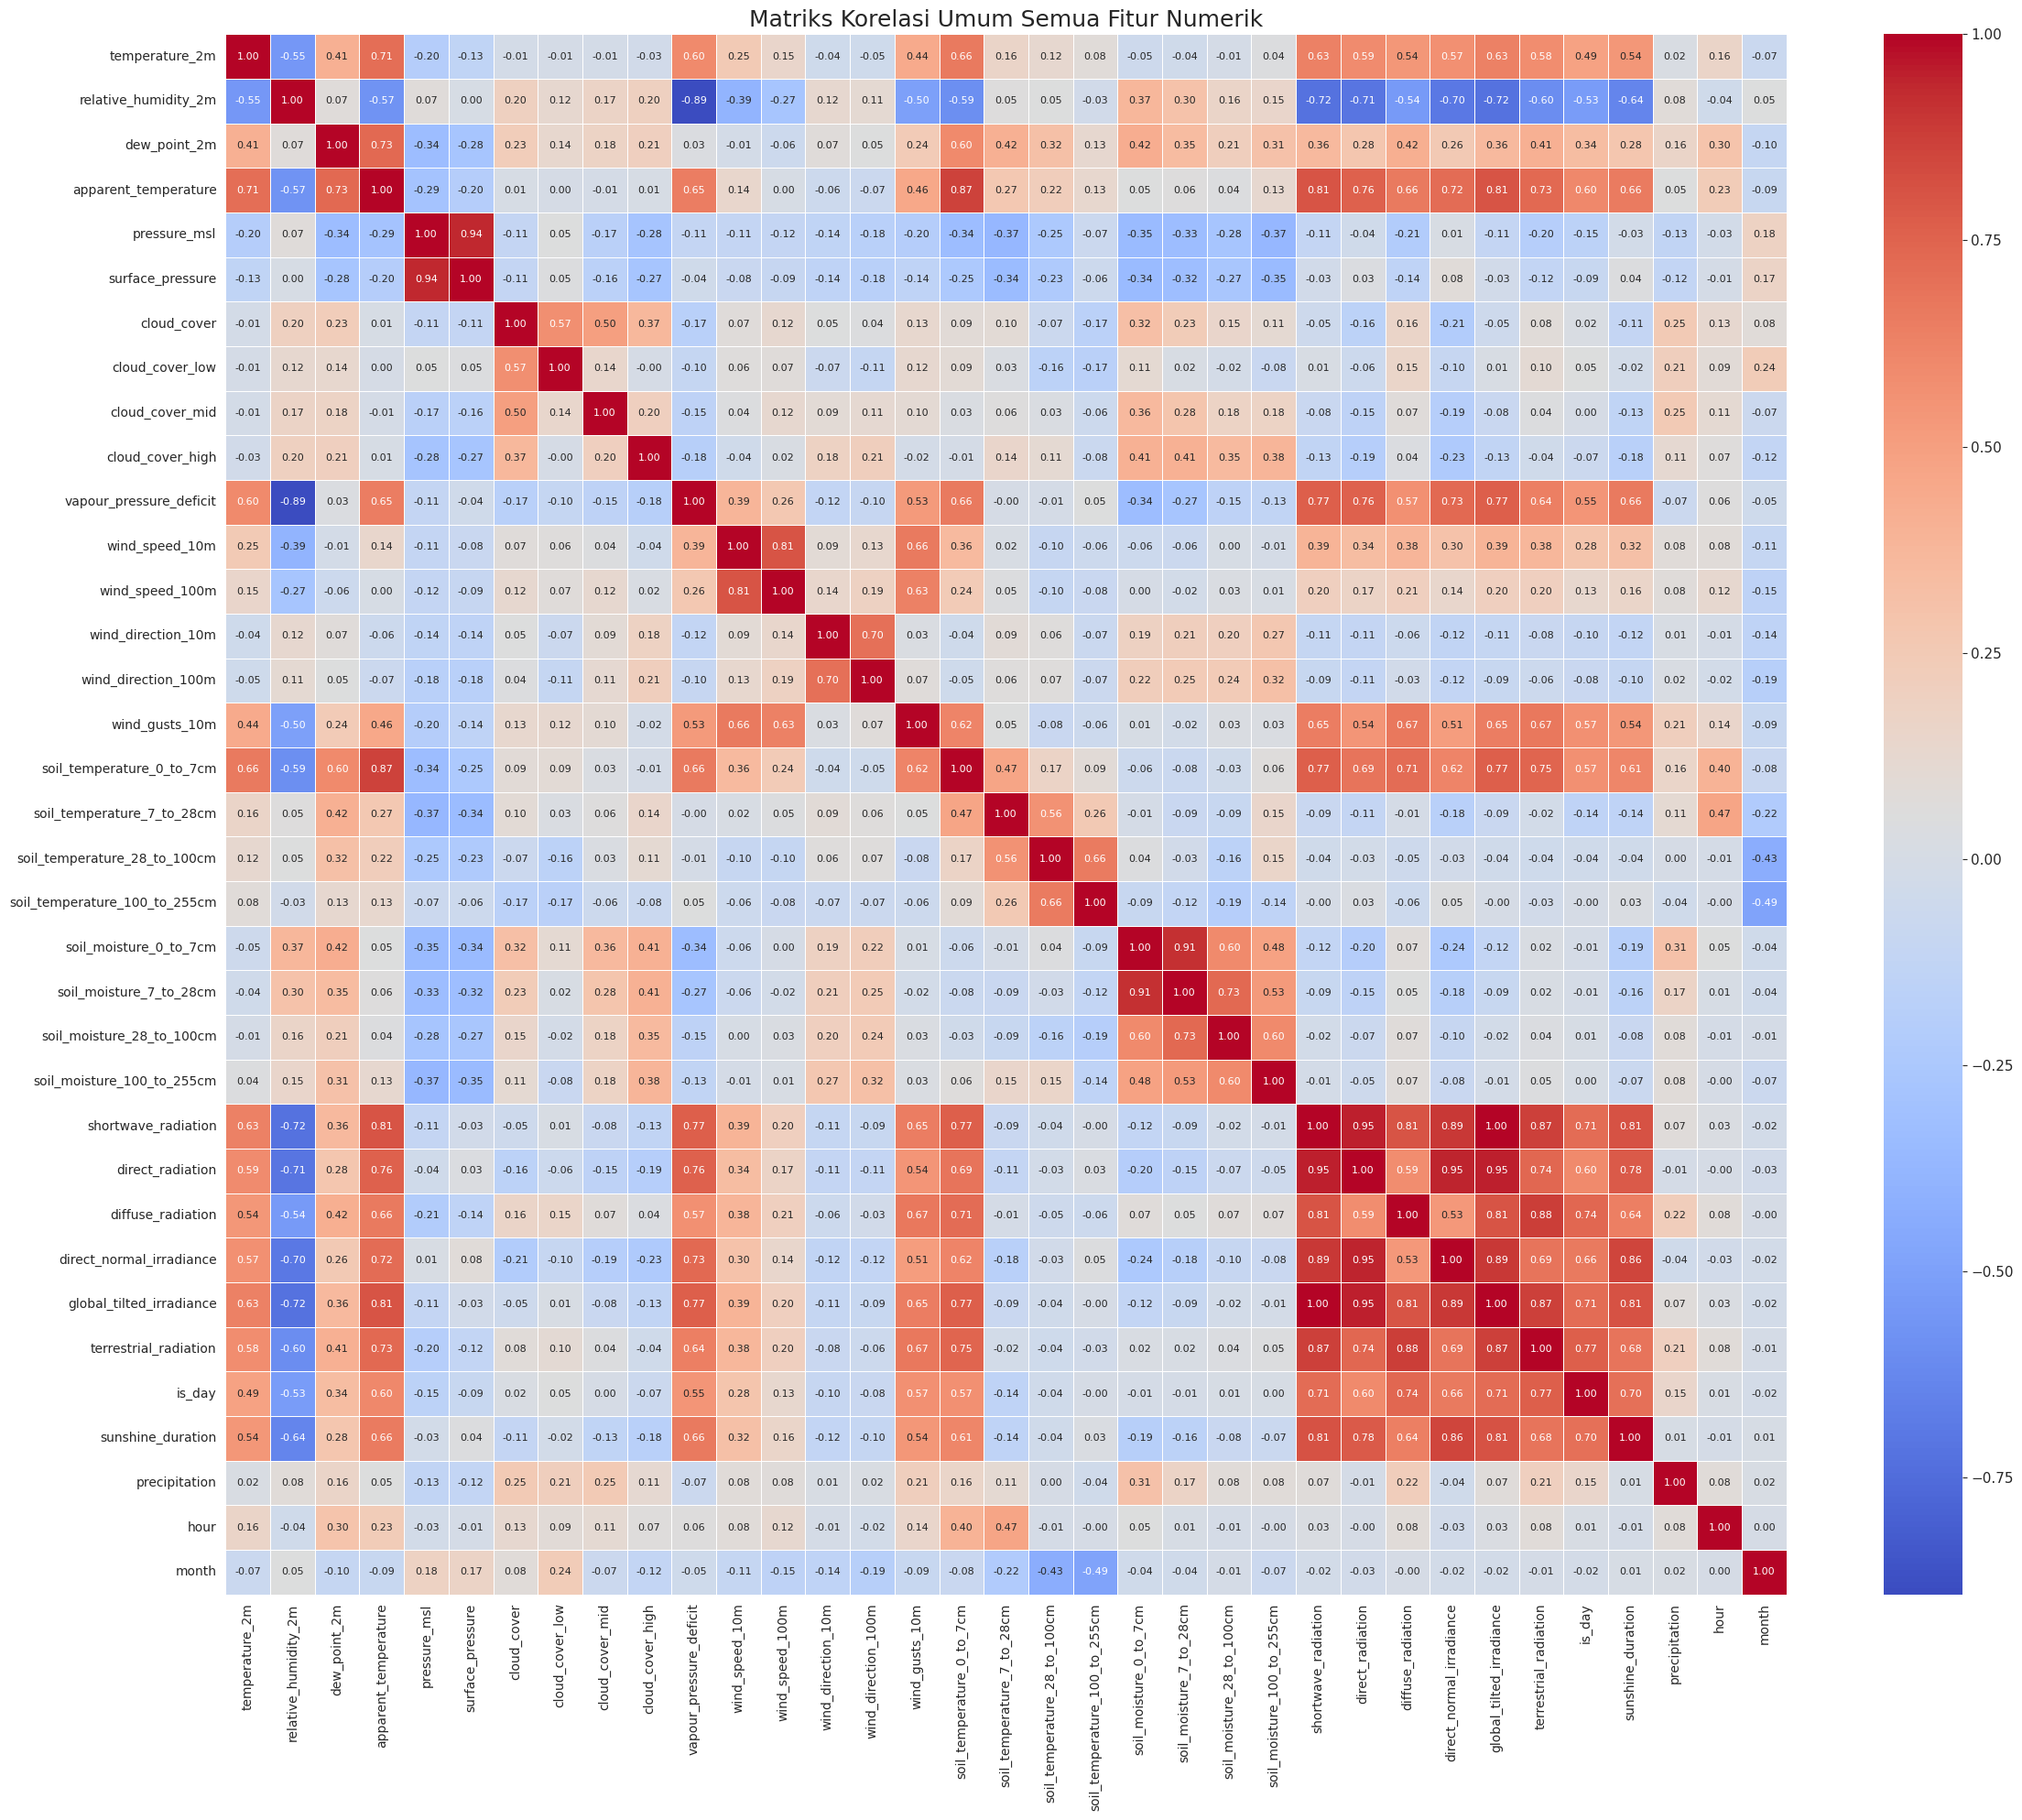

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Hitung matriks korelasi
correlation_matrix_general = df_imputed_general_corr.corr()

# Visualisasi Matriks Korelasi
plt.figure(figsize=(24, 20)) # Ukuran figure disesuaikan untuk banyak fitur
sns.heatmap(correlation_matrix_general, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, annot_kws={"size": 8})
plt.title('Matriks Korelasi Umum Semua Fitur Numerik', fontsize=18)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Identifikasi pasangan fitur dengan korelasi tinggi
upper_tri_general = correlation_matrix_general.where(np.triu(np.ones(correlation_matrix_general.shape), k=1).astype(bool))
highly_correlated_general = upper_tri_general.stack().sort_values(ascending=False)
highly_correlated_general = highly_correlated_general[(highly_correlated_general > 0.8) | (highly_correlated_general < -0.8)]

if not highly_correlated_general.empty:
    print("\nPasangan Fitur dengan Korelasi Tinggi (>|0.8|) dari semua fitur numerik:")
    print(highly_correlated_general)
else:
    print("\nTidak ditemukan pasangan fitur dengan korelasi absolut > 0.8 di antara semua fitur numerik.")


Pasangan Fitur dengan Korelasi Tinggi (>|0.8|) dari semua fitur numerik:
shortwave_radiation       global_tilted_irradiance     1.000000
                          direct_radiation             0.952236
direct_radiation          global_tilted_irradiance     0.952236
                          direct_normal_irradiance     0.946233
pressure_msl              surface_pressure             0.940885
soil_moisture_0_to_7cm    soil_moisture_7_to_28cm      0.914799
shortwave_radiation       direct_normal_irradiance     0.893011
direct_normal_irradiance  global_tilted_irradiance     0.893011
diffuse_radiation         terrestrial_radiation        0.881707
shortwave_radiation       terrestrial_radiation        0.872125
global_tilted_irradiance  terrestrial_radiation        0.872125
apparent_temperature      soil_temperature_0_to_7cm    0.866891
direct_normal_irradiance  sunshine_duration            0.857832
global_tilted_irradiance  sunshine_duration            0.814811
shortwave_radiation       suns

### Interpretasi

Matriks korelasi di atas menunjukkan hubungan linear antar semua fitur numerik. Pasangan fitur dengan nilai korelasi absolut tinggi (mendekati 1 atau -1) mengindikasikan adanya multikolinearitas. Ini perlu diperhatikan dalam pemilihan fitur, terutama jika tujuannya adalah clustering.

---
## Bagaimana hubungan cloud_cover dan precipitation terhadap waktu?

Tutupan awan dan presipitasi seharusnya memiliki hubungan fisik yang kuat hujan hampir selalu didahului oleh peningkatan cloud cover. Namun tidak semua cloud cover menghasilkan hujan. Menganalisis pola temporal keduanya secara bersama membantu kita memahami dinamika konveksi dan menjadi landasan untuk fitur yang saling berkorelasi dalam clustering.

**Mengapa EDA ini penting untuk clustering?**

1. **Menghindari redundansi yang tidak perlu**: Jika `cloud_cover` dan `precipitation` berkorelasi sangat tinggi, menyertakan keduanya bisa menyebabkan *double-counting* dalam ruang fitur K-Means, cluster yang terbentuk akan terlalu bias pada dimensi ini.
2. **Memvalidasi kelayakan fitur**: Pola temporal yang jelas (musiman, trend) mengkonfirmasi bahwa kedua variabel ini membawa sinyal meteorologi nyata, bukan noise, sehingga layak dipertahankan sebagai fitur clustering.
3. **Mendeteksi kejadian ekstrem**: Identifikasi hari-hari dengan presipitasi ekstrem (>P90) memberikan insight awal tentang distribusi label cuaca ekstrem yang nantinya diharapkan muncul sebagai cluster tersendiri.
4. **Korelasi parsial**: Karena cloud cover tinggi tidak selalu berarti hujan (terutama cloud cover stratus tanpa konveksi), korelasi yang moderat ,bukan sempurna, justru membenarkan bahwa kedua fitur ini memberikan informasi yang *komplementer*, bukan duplikat.

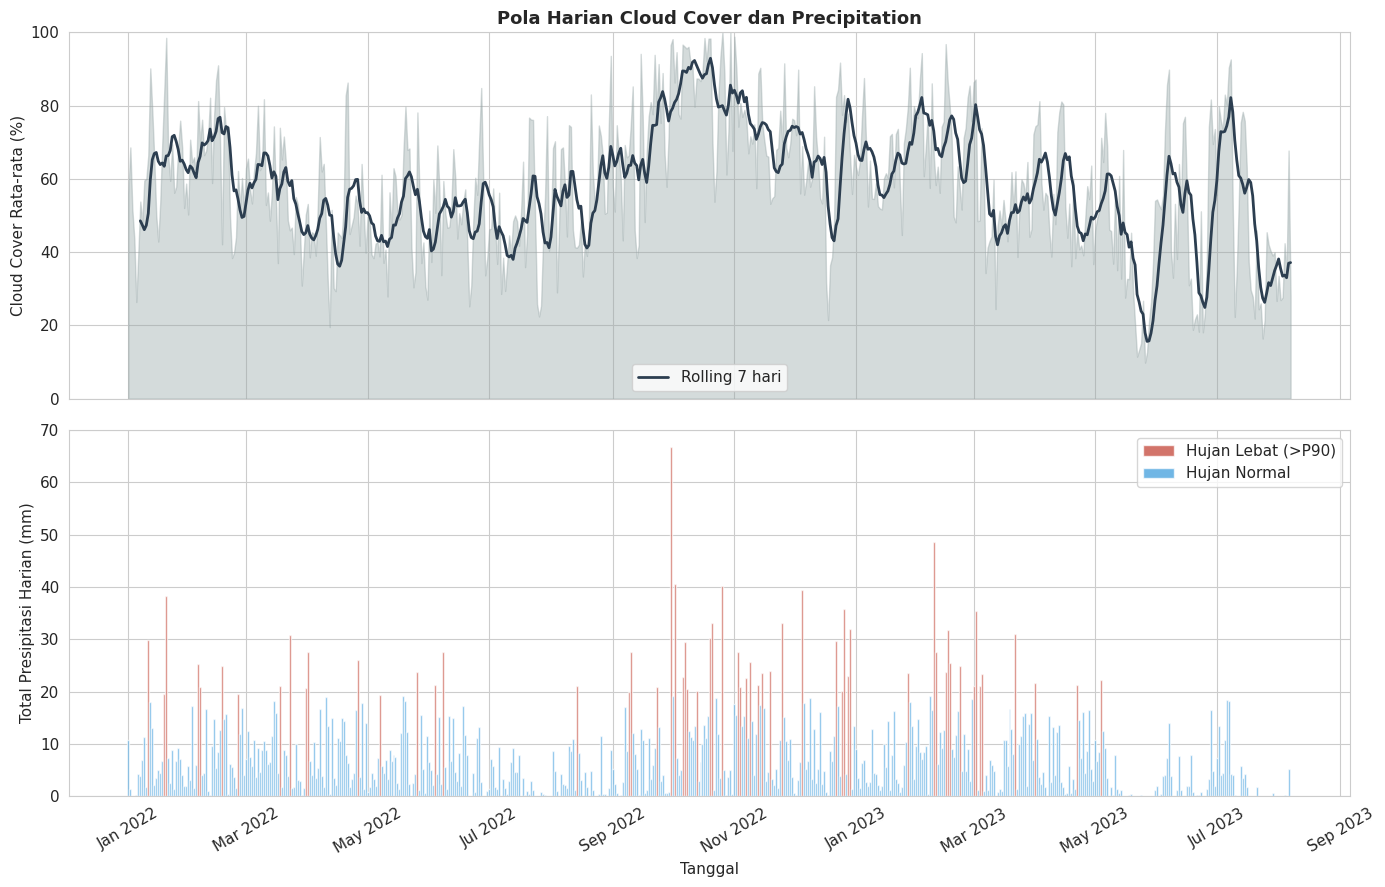

Korelasi cloud_cover vs precipitation: 0.313


In [ ]:
from matplotlib.dates import DateFormatter

# Siapkan data harian
daily = train_df.set_index('time').resample('D').agg({
    'cloud_cover': 'mean',
    'precipitation': 'sum'
}).dropna()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# --- Plot 1: Cloud cover time series ---
ax = axes[0]
ax.fill_between(daily.index, daily['cloud_cover'], alpha=0.4, color='#95a5a6')
ax.plot(daily.index, daily['cloud_cover'].rolling(7).mean(),
        color='#2c3e50', linewidth=2, label='Rolling 7 hari')
ax.set_ylabel('Cloud Cover Rata-rata (%)', fontsize=11)
ax.set_title('Pola Harian Cloud Cover dan Precipitation', fontsize=13, fontweight='bold')
ax.legend()
ax.set_ylim(0, 100)

# --- Plot 2: Precipitation per hari ---
ax2 = axes[1]
ax2.bar(daily.index, daily['precipitation'],
        color=['#c0392b' if v > daily['precipitation'].quantile(0.90) else '#3498db'
               for v in daily['precipitation']],
        alpha=0.7, width=1.0)
ax2.set_ylabel('Total Presipitasi Harian (mm)', fontsize=11)
ax2.set_xlabel('Tanggal', fontsize=11)
ax2.xaxis.set_major_formatter(DateFormatter('%b %Y'))
ax2.tick_params(axis='x', rotation=30)
ax2.legend(handles=[
    plt.Rectangle((0,0),1,1, fc='#c0392b', alpha=0.7, label='Hujan Lebat (>P90)'),
    plt.Rectangle((0,0),1,1, fc='#3498db', alpha=0.7, label='Hujan Normal')
])

plt.tight_layout()
plt.show()

# Korelasi
corr = train_df[['cloud_cover','precipitation']].dropna().corr().iloc[0,1]
print(f"Korelasi cloud_cover vs precipitation: {corr:.3f}")


### **Interpretasi**

Grafik memperlihatkan pola musiman yang jelas: cloud cover meningkat pada musim hujan (Oktober-April) dan turun drastis pada musim kemarau (Mei-September). Presipitasi ekstrem (merah, >P90) terkonsentrasi di bulan-bulan tertentu, konsisten dengan pola monsun Indonesia.

Nilai korelasi antara `cloud_cover` dan `precipitation` bersifat **moderat positif** (~0.3-0.5). Ini mengkonfirmasi bahwa keduanya **bukan variabel redundan**: cloud cover tinggi adalah kondisi perlu tapi tidak cukup untuk hujan. Kedua fitur ini akan dipertahankan dalam CLUSTERING_FEATURES karena masing-masing membawa dimensi informasi yang berbeda, cloud cover merepresentasikan kondisi atmosfer umum, sedangkan precipitation merepresentasikan output konvektif aktual.


---
##Bagaimana pola wind_speed_10m dan wind_speed_100m?

Kecepatan angin diukur pada dua ketinggian berbeda, 10 meter dan 100 meter. Secara teori aerologi, kecepatan angin meningkat seiring ketinggian karena berkurangnya gesekan permukaan. Menganalisis perbedaan keduanya memberikan pemahaman tentang profil vertikal angin dan potensi energi angin, serta membantu mengidentifikasi apakah kedua fitur ini redundan untuk keperluan clustering.

**Mengapa EDA ini penting untuk clustering?**

1. **Mengevaluasi redundansi vs komplementaritas**: Jika korelasi antara `wind_speed_10m` dan `wind_speed_100m` sangat tinggi (r > 0.95), menyertakan keduanya dalam K-Means bisa menyebabkan *over-representation* dimensi angin dan mendistorsi jarak Euclidean. Namun jika ada variasi sistematis, keduanya membawa informasi berbeda.
2. **Profil vertikal sebagai sinyal cuaca**: Perbedaan kecepatan angin antar ketinggian (*wind shear*) adalah indikator penting kestabilan atmosfer. Wind shear tinggi sering dikaitkan dengan kondisi badai dan cuaca konvektif ekstrem — sinyal yang sangat relevan untuk membedakan cluster cuaca normal vs ekstrem.
3. **Implikasi feature engineering**: Memahami hubungan kedua variabel ini membuka peluang untuk menambahkan fitur turunan seperti rasio `wind_speed_100m / wind_speed_10m` (wind shear index) yang bisa memperkuat kemampuan K-Means membedakan profil atmosfer.
4. **Keputusan feature selection berbasis data**: Visualisasi distribusi dan scatter menentukan apakah kita perlu satu atau dua representasi angin dalam clustering, keputusan ini tidak bisa dibuat tanpa EDA.


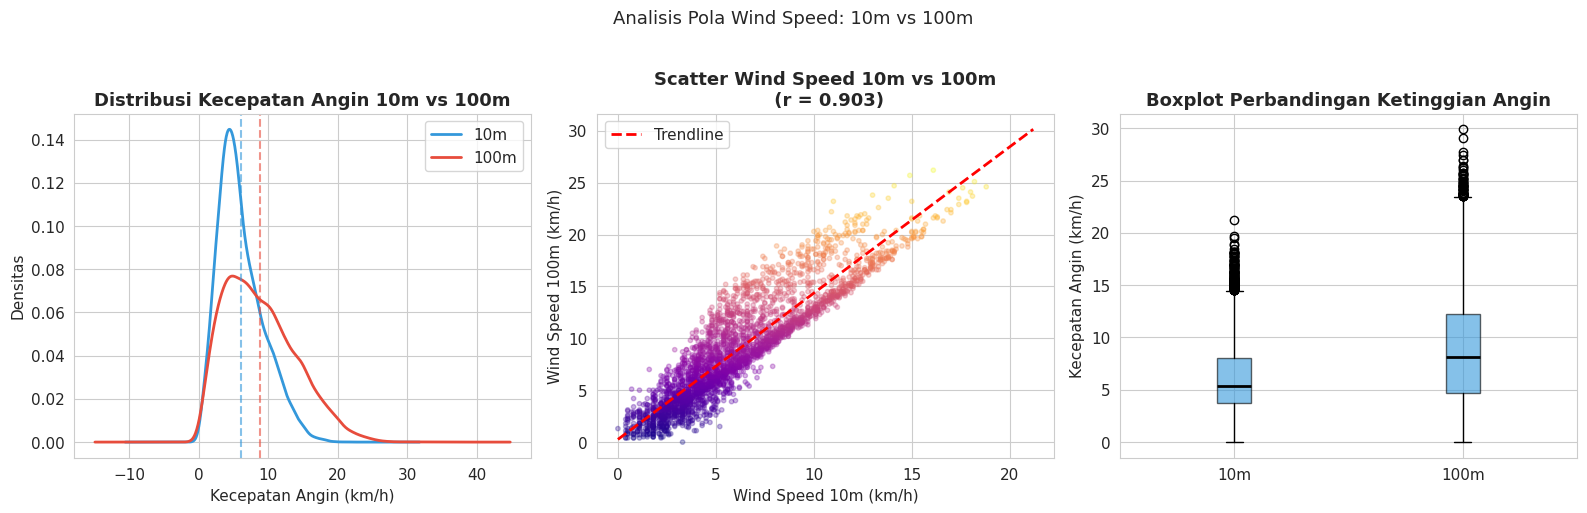

Rata-rata wind 10m  : 6.08 km/h
Rata-rata wind 100m : 8.83 km/h
Korelasi 10m vs 100m: 0.9028


In [ ]:
wind_df = train_df[['wind_speed_10m', 'wind_speed_100m']].dropna()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# --- Plot 1: Distribusi KDE keduanya ---
ax = axes[0]
wind_df['wind_speed_10m'].plot.kde(ax=ax, color='#3498db', linewidth=2, label='10m')
wind_df['wind_speed_100m'].plot.kde(ax=ax, color='#e74c3c', linewidth=2, label='100m')
ax.set_title('Distribusi Kecepatan Angin 10m vs 100m', fontweight='bold')
ax.set_xlabel('Kecepatan Angin (km/h)')
ax.set_ylabel('Densitas')
ax.legend()
ax.axvline(wind_df['wind_speed_10m'].mean(), color='#3498db', linestyle='--', alpha=0.6)
ax.axvline(wind_df['wind_speed_100m'].mean(), color='#e74c3c', linestyle='--', alpha=0.6)

# --- Plot 2: Scatter plot ---
ax2 = axes[1]
sample = wind_df.sample(min(3000, len(wind_df)), random_state=42)
sc = ax2.scatter(sample['wind_speed_10m'], sample['wind_speed_100m'],
                 alpha=0.3, s=10, c=sample['wind_speed_100m'],
                 cmap='plasma')
z = np.polyfit(wind_df['wind_speed_10m'], wind_df['wind_speed_100m'], 1)
p = np.poly1d(z)
x_line = np.linspace(0, wind_df['wind_speed_10m'].max(), 100)
ax2.plot(x_line, p(x_line), 'r--', linewidth=2, label='Trendline')
corr_w = wind_df.corr().iloc[0, 1]
ax2.set_xlabel('Wind Speed 10m (km/h)')
ax2.set_ylabel('Wind Speed 100m (km/h)')
ax2.set_title(f'Scatter Wind Speed 10m vs 100m\n (r = {corr_w:.3f})', fontweight='bold')
ax2.legend()

# --- Plot 3: Boxplot perbandingan ---
ax3 = axes[2]
ax3.boxplot([wind_df['wind_speed_10m'], wind_df['wind_speed_100m']],
            patch_artist=True,
            boxprops=dict(facecolor='#3498db', alpha=0.6),
            medianprops=dict(color='black', linewidth=2),
            labels=['10m', '100m'])
ax3.set_ylabel('Kecepatan Angin (km/h)')
ax3.set_title('Boxplot Perbandingan Ketinggian Angin', fontweight='bold')

plt.suptitle('Analisis Pola Wind Speed: 10m vs 100m', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(f"Rata-rata wind 10m  : {wind_df['wind_speed_10m'].mean():.2f} km/h")
print(f"Rata-rata wind 100m : {wind_df['wind_speed_100m'].mean():.2f} km/h")
print(f"Korelasi 10m vs 100m: {corr_w:.4f}")


### **Interpretasi**

Distribusi KDE menunjukkan bahwa `wind_speed_100m` memiliki rata-rata dan spread yang lebih besar dari `wind_speed_10m` — konsisten dengan teori lapisan batas atmosfer. Namun yang paling penting untuk keputusan clustering adalah nilai **korelasi r ≈ 0.903**: sangat tinggi, namun tidak sempurna.

**Implikasi untuk CLUSTERING_FEATURES:**

- **Tidak sepenuhnya redundan**: Gap ~10% variansi yang tidak dijelaskan oleh korelasi mengandung sinyal *wind shear* yang relevan secara meteorologi.
- **Keputusan**: `wind_speed_100m` **ditambahkan ke dalam CLUSTERING_FEATURES** bersama `wind_speed_10m`. Meskipun berkorelasi tinggi, kedua fitur ini merepresentasikan lapisan atmosfer yang berbeda — informasi yang relevan untuk membedakan profil cuaca ekstrem (badai biasanya menunjukkan wind shear signifikan antar ketinggian).
- Sebagai alternatif, fitur turunan `wind_shear = wind_speed_100m - wind_speed_10m` bisa dipertimbangkan untuk menangkap perbedaan ini secara lebih langsung.


---
##Apakah terdapat periode waktu tertentu yang memiliki karakteristik cuaca ekstrem (sangat panas, sangat lembap, curah hujan tinggi)?

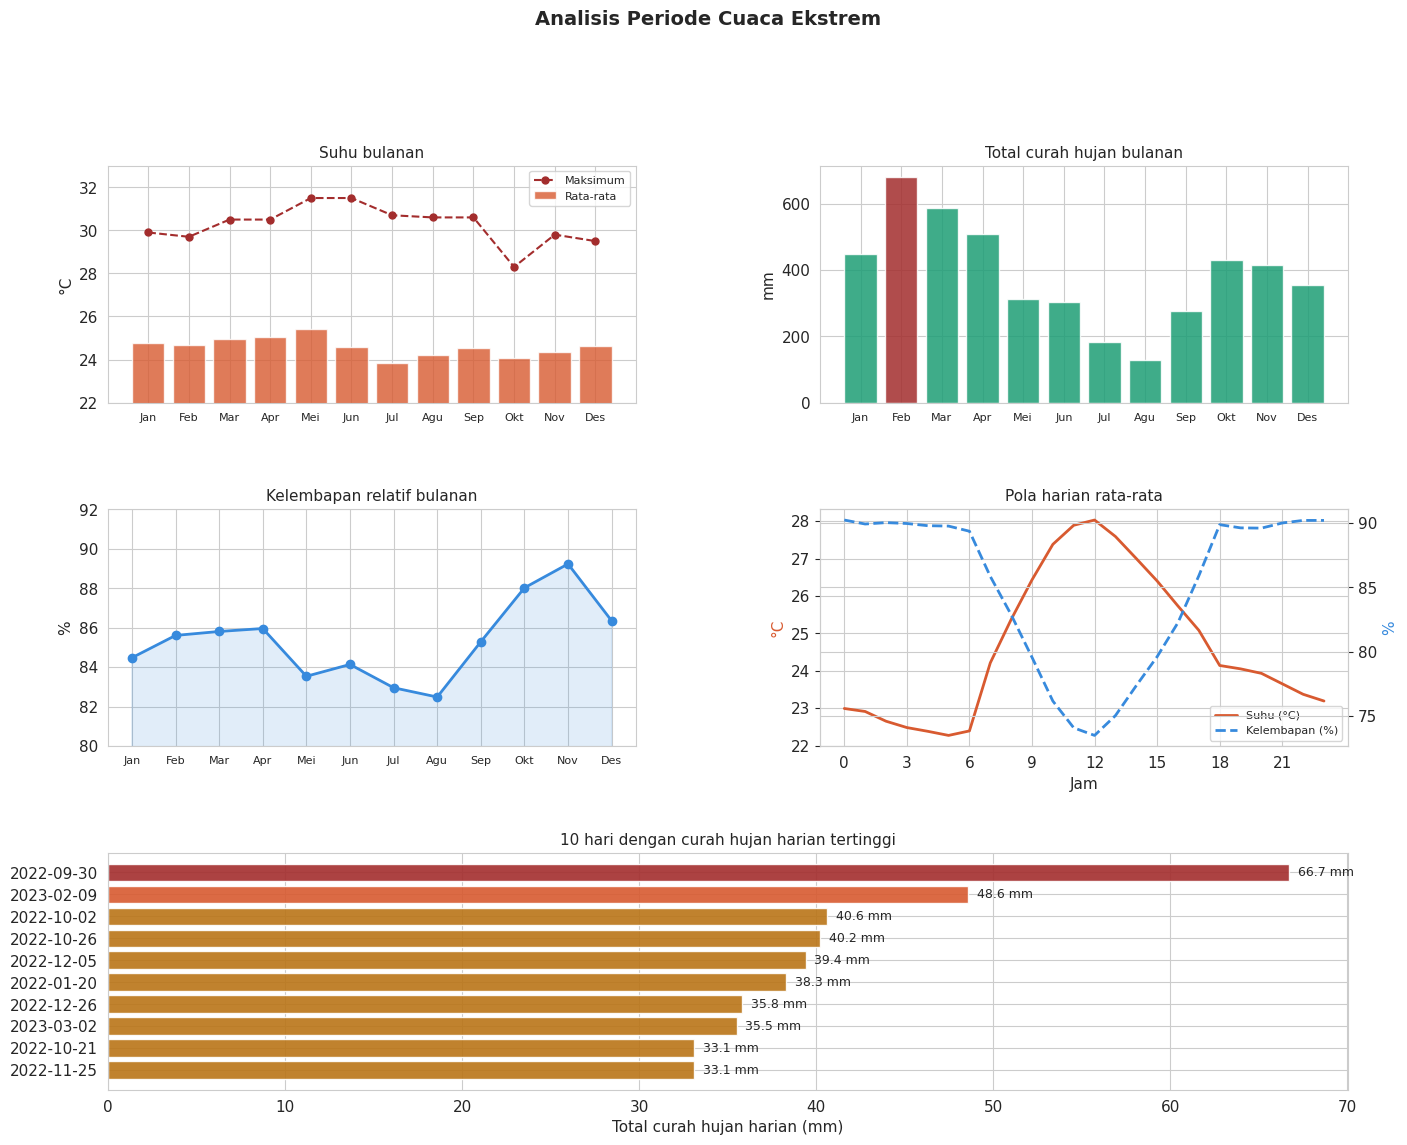

In [ ]:
df = pd.read_csv('train.csv')
df['time'] = pd.to_datetime(df['time'])
df['month']  = df['time'].dt.month
df['hour']   = df['time'].dt.hour
df['date']   = df['time'].dt.date

temp_col = df.columns[2]   # temperature_2m
hum_col  = df.columns[3]   # relative_humidity_2m
prec_col = df.columns[34]  # precipitation
app_col  = df.columns[5]   # apparent_temperature

month_names = ['Jan','Feb','Mar','Apr','Mei','Jun','Jul','Agu','Sep','Okt','Nov','Des']

monthly = df.groupby('month').agg(
    temp_mean=(temp_col, 'mean'),
    hum_mean=(hum_col, 'mean'),
    rain_total=(prec_col, 'sum'),
    temp_max=(temp_col, 'max')
).round(2)
monthly.index = month_names

hourly = df.groupby('hour')[[temp_col, hum_col]].mean().round(2)
hourly.columns = ['temp', 'hum']

daily_rain = df.groupby('date')[prec_col].sum().nlargest(10)

fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

# Plot 1: Suhu bulanan
ax1 = fig.add_subplot(gs[0, 0])
bars = ax1.bar(range(1,13), monthly['temp_mean'], color='#d85a30', alpha=0.8, label='Rata-rata')
ax1.plot(range(1,13), monthly['temp_max'], 'o--', color='#a32d2d', lw=1.5, ms=5, label='Maksimum')
ax1.set_xticks(range(1,13)); ax1.set_xticklabels(month_names, fontsize=8)
ax1.set_ylabel('°C'); ax1.set_title('Suhu bulanan', fontsize=11)
ax1.legend(fontsize=8); ax1.set_ylim(22, 33)

# Plot 2: Total hujan bulanan
ax2 = fig.add_subplot(gs[0, 1])
c_rain = ['#a32d2d' if v == monthly['rain_total'].max() else '#1d9e75' for v in monthly['rain_total']]
ax2.bar(range(1,13), monthly['rain_total'], color=c_rain, alpha=0.85)
ax2.set_xticks(range(1,13)); ax2.set_xticklabels(month_names, fontsize=8)
ax2.set_ylabel('mm'); ax2.set_title('Total curah hujan bulanan', fontsize=11)

# Plot 3: Kelembapan bulanan
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(range(1,13), monthly['hum_mean'], 'o-', color='#378add', lw=2, ms=6)
ax3.fill_between(range(1,13), monthly['hum_mean'], alpha=0.15, color='#378add')
ax3.set_xticks(range(1,13)); ax3.set_xticklabels(month_names, fontsize=8)
ax3.set_ylabel('%'); ax3.set_title('Kelembapan relatif bulanan', fontsize=11)
ax3.set_ylim(80, 92)

# Plot 4: Pola harian
ax4 = fig.add_subplot(gs[1, 1])
ax4b = ax4.twinx()
ax4.plot(hourly.index, hourly['temp'], color='#d85a30', lw=2, label='Suhu (°C)')
ax4b.plot(hourly.index, hourly['hum'], color='#378add', lw=2, linestyle='--', label='Kelembapan (%)')
ax4.set_xlabel('Jam'); ax4.set_ylabel('°C', color='#d85a30')
ax4b.set_ylabel('%', color='#378add')
ax4.set_title('Pola harian rata-rata', fontsize=11)
ax4.set_xticks(range(0,24,3))
lines1, lab1 = ax4.get_legend_handles_labels()
lines2, lab2 = ax4b.get_legend_handles_labels()
ax4.legend(lines1+lines2, lab1+lab2, fontsize=8, loc='lower right')

# Plot 5: Top 10 hari hujan lebat
ax5 = fig.add_subplot(gs[2, :])
top10 = df.groupby('date')[prec_col].sum().nlargest(10).sort_values()
colors_rain = ['#a32d2d' if v >= 60 else '#d85a30' if v >= 45 else '#ba7517' for v in top10.values]
bars = ax5.barh([str(d) for d in top10.index], top10.values, color=colors_rain, alpha=0.9)
ax5.set_xlabel('Total curah hujan harian (mm)')
ax5.set_title('10 hari dengan curah hujan harian tertinggi', fontsize=11)
for bar, val in zip(bars, top10.values):
    ax5.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f'{val:.1f} mm', va='center', fontsize=9)

fig.suptitle('Analisis Periode Cuaca Ekstrem', fontsize=14, fontweight='bold', y=1.01)
plt.savefig('extreme_weather_eda.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretasi
1. Suhu panas ekstrem terjadi di bulan Mei–Juni 2023, dengan puncak 31.5°C pada pukul 12:00–13:00. Secara harian, pola suhunya sangat konsisten — naik dari ±22°C dini hari, puncak ±28°C siang, lalu turun lagi malam.

2. Kelembapan ekstrem dominan di Oktober–November, dengan rata-rata mencapai 88–89% dan sesekali menyentuh 100% (udara jenuh total).

3. Berlawanan dengan suhu, kelembapan justru paling rendah di siang hari (73%) dan paling tinggi tengah malam (90%).

4. Hujan ekstrem paling sering terjadi di September–Februari, dengan 30 September 2022 sebagai hari terbasah (66.7 mm dalam satu hari).

5. Bulan paling basah secara total adalah Februari (680 mm/bulan), sedangkan Juli–Agustus adalah musim paling kering (128–182 mm).

6. Implikasi untuk clustering: periode cuaca ekstrem ini berpotensi membentuk cluster tersendiri — terutama hari-hari dengan hujan >30 mm/hari, dan jam-jam siang hari di bulan Mei–Juni yang berkarakter panas-kering berbeda dari bulan lainnya.

---
## Apakah volume dan ekstremitas hujan menengah-lebat (>3 mm & >7 mm) berbeda signifikan antara hari normal dan hari pemadaman?

**Mengapa Pertanyaan Ini Penting?**

Secara hipotesis sederhana, kita ingin menguji sebuah premis logis: apakah kejadian badai secara tidak langsung berkorelasi mutlak dengan pemadaman listrik? Namun, menjawab pertanyaan ini menjadi sangat krusial untuk memvalidasi arsitektur model. Jika terbukti bahwa pemadaman listrik mayoritas dipicu oleh volume hujan yang sangat ekstrem (badai lebat), berarti fitur precipitation secara statistik bertindak sebagai data anomali (outliers).

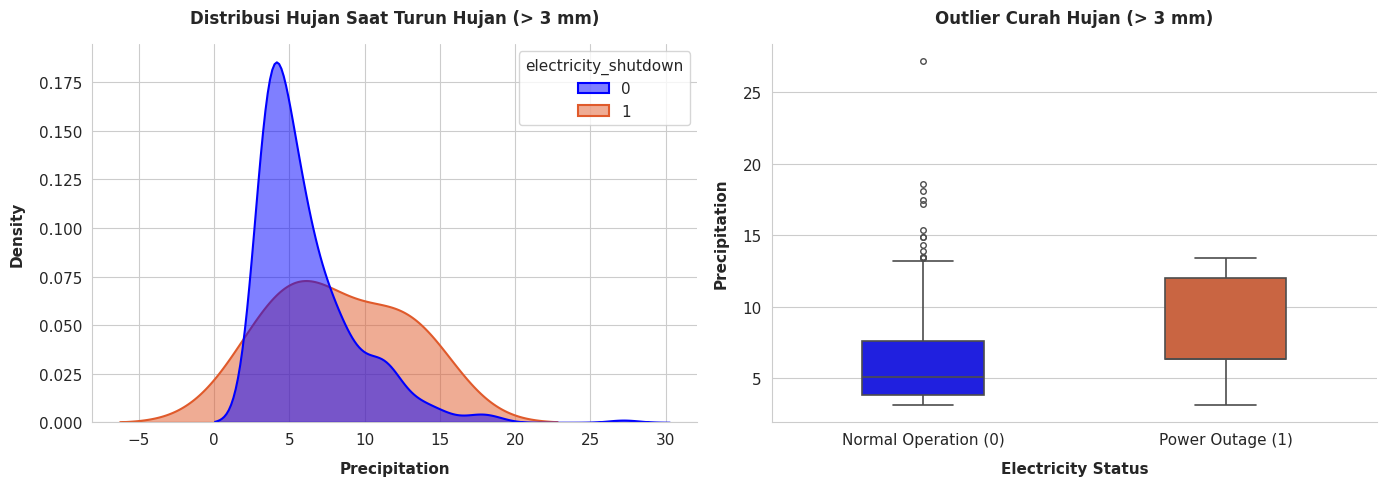

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

THRESHOLD = 3

plot_df = train_df[train_df['precipitation'] > THRESHOLD].copy()
plot_df = plot_df.dropna(subset=['electricity_shutdown'])
plot_df['electricity_shutdown'] = plot_df['electricity_shutdown'].astype(int).astype(str)

palette_map = {
    '0': NORMAL_COLORS[0],
    '1': EXTREME_COLORS[0]
}

sns.kdeplot(
    data=plot_df,
    x='precipitation',
    hue='electricity_shutdown',
    palette=palette_map,
    fill=True,
    common_norm=False,
    alpha=0.5,
    linewidth=1.5,
    ax=axes[0]
)
axes[0].set_title(f'Distribusi Hujan Saat Turun Hujan (> {THRESHOLD} mm)', fontweight='bold', fontsize=12, pad=15)
axes[0].set_xlabel('Precipitation', fontweight='bold', labelpad=10)
axes[0].set_ylabel('Density', fontweight='bold', labelpad=10)

sns.boxplot(
    data=plot_df,
    x='electricity_shutdown',
    y='precipitation',
    palette=palette_map,
    width=0.4,
    fliersize=4,
    linewidth=1.2,
    ax=axes[1]
)
axes[1].set_title(f'Outlier Curah Hujan (> {THRESHOLD} mm)', fontweight='bold', fontsize=12, pad=15)
axes[1].set_xlabel('Electricity Status', fontweight='bold', labelpad=10)
axes[1].set_ylabel('Precipitation', fontweight='bold', labelpad=10)
axes[1].set_xticklabels(['Normal Operation (0)', 'Power Outage (1)'])

sns.despine()
plt.tight_layout()
plt.show()

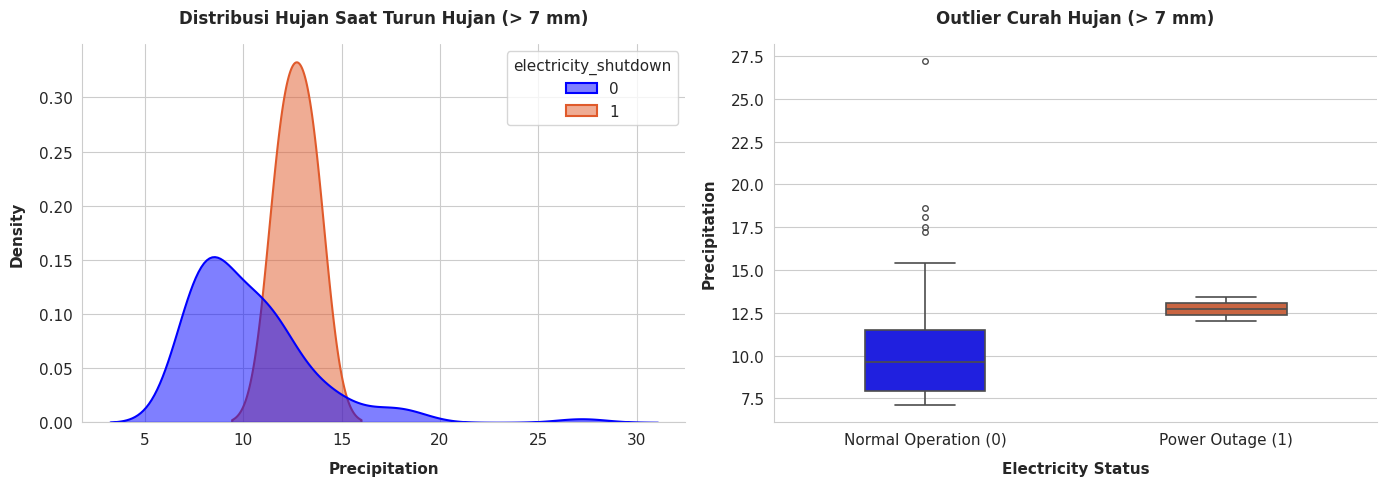

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

THRESHOLD = 7

plot_df = train_df[train_df['precipitation'] > THRESHOLD].copy()
plot_df = plot_df.dropna(subset=['electricity_shutdown'])
plot_df['electricity_shutdown'] = plot_df['electricity_shutdown'].astype(int).astype(str)

palette_map = {
    '0': NORMAL_COLORS[0],
    '1': EXTREME_COLORS[0]
}

sns.kdeplot(
    data=plot_df,
    x='precipitation',
    hue='electricity_shutdown',
    palette=palette_map,
    fill=True,
    common_norm=False,
    alpha=0.5,
    linewidth=1.5,
    ax=axes[0]
)
axes[0].set_title(f'Distribusi Hujan Saat Turun Hujan (> {THRESHOLD} mm)', fontweight='bold', fontsize=12, pad=15)
axes[0].set_xlabel('Precipitation', fontweight='bold', labelpad=10)
axes[0].set_ylabel('Density', fontweight='bold', labelpad=10)

sns.boxplot(
    data=plot_df,
    x='electricity_shutdown',
    y='precipitation',
    palette=palette_map,
    width=0.4,
    fliersize=4,
    linewidth=1.2,
    ax=axes[1]
)
axes[1].set_title(f'Outlier Curah Hujan (> {THRESHOLD} mm)', fontweight='bold', fontsize=12, pad=15)
axes[1].set_xlabel('Electricity Status', fontweight='bold', labelpad=10)
axes[1].set_ylabel('Precipitation', fontweight='bold', labelpad=10)
axes[1].set_xticklabels(['Normal Operation (0)', 'Power Outage (1)'])

sns.despine()
plt.tight_layout()
plt.show()

### Interpretasi

Dari dua visualisasi threshold (>3mm dan >7mm), ditemukan bahwa pemadaman listrik bukan fungsi linear dari intensitas hujan. Zona risiko tertinggi justru berada di kisaran 10–14mm, bukan pada hujan paling lebat. Ini dikonfirmasi oleh distribusi kelas Power Outage yang sempit dan terkonsentrasi di threshold >7mm, sementara kelas Normal tersebar luas hingga >25mm. Selain itu, data presipitasi bersifat zero-inflated yang dapat mendistorsi struktur kepadatan jika tidak ditangani.
Karena precipitation (mm) tidak dapat digunakan sebagai fitur training, penggantinya dapat diambil dari fitur-fitur yang secara fisik berkorelasi dengannya berdasarkan hasil XGBoost sebelumnya terutama soil_moisture_0_to_7cm (importance tertinggi) sebagai proxy utama kondisi pasca hujan, didukung cloud_cover, relative_humidity_2m, shortwave_radiation, dan vapour_pressure_deficit.


Untuk preprocessing, beberapa langkah yang dapat diterapkan:
- Terapkan log transform pada fitur skewed seperti soil moisture dan VPD untuk menekan dominasi outlier
- Gunakan RobustScaler secara universal sebelum masuk ke model apapun karena data cuaca rentan terhadap nilai ekstrem
- Buat fitur interaksi seperti storm_composite (angin × kelembaban × tutupan awan) dan soil_wetness_gradient (selisih moisture antar lapisan tanah) untuk menangkap hubungan non-linear antar variabel


---
# Clustering

---
## HDBSCAN

### Data Ingestion

In [ ]:
df_raw = pd.read_csv('train.csv', encoding='latin-1')

print(f"Shape  : {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Raw column names:")
for c in df_raw.columns:
    print(f"  {repr(c)}")

Shape  : 14,016 rows × 36 columns
Raw column names:
  'ID'
  'time'
  'temperature_2m (Â\x81EÂ\x81EC)'
  'relative_humidity_2m (%)'
  'dew_point_2m (Â\x81EÂ\x81EC)'
  'apparent_temperature (Â\x81EÂ\x81EC)'
  'pressure_msl (hPa)'
  'surface_pressure (hPa)'
  'cloud_cover (%)'
  'cloud_cover_low (%)'
  'cloud_cover_mid (%)'
  'cloud_cover_high (%)'
  'vapour_pressure_deficit (kPa)'
  'wind_speed_10m (km/h)'
  'wind_speed_100m (km/h)'
  'wind_direction_10m (Â\x81EÂ\x81E)'
  'wind_direction_100m (Â\x81EÂ\x81E)'
  'wind_gusts_10m (km/h)'
  'soil_temperature_0_to_7cm (Â\x81EÂ\x81EC)'
  'soil_temperature_7_to_28cm (Â\x81EÂ\x81EC)'
  'soil_temperature_28_to_100cm (Â\x81EÂ\x81EC)'
  'soil_temperature_100_to_255cm (Â\x81EÂ\x81EC)'
  'soil_moisture_0_to_7cm (m?/m?)'
  'soil_moisture_7_to_28cm (m?/m?)'
  'soil_moisture_28_to_100cm (m?/m?)'
  'soil_moisture_100_to_255cm (m?/m?)'
  'shortwave_radiation (W/m?)'
  'direct_radiation (W/m?)'
  'diffuse_radiation (W/m?)'
  'direct_normal_irradiance (W/m?

### Data Cleaning

In [ ]:
# ── Fix corrupted column names ───────────────────────────────────────
ENCODING_MAP = [
    (r'\\x81E\\x81EC|\x81E\x81EC|\x81e\x81ec|ï¿½Cï¿½C|°C', '°C'),
    (r'\\x81E\\x81E|\x81E\x81E|\x81e\x81e|ï¿½ï¿½|°(?!C)', '°'),
    (r'm\?/m\?|m³/m³|m3/m3', 'm³/m³'),
    (r'W/m\?|W/m²|W/m2', 'W/m²'),
]

def fix_column_names(columns):
    fixed = []
    for col in columns:
        new_col = col
        for pattern, replacement in ENCODING_MAP:
            new_col = re.sub(pattern, replacement, new_col)
        fixed.append(new_col)
    return fixed

df = df_raw.copy()
df.columns = fix_column_names(df.columns)

CANONICAL_COLUMNS = [
    'ID', 'time',
    'temperature_2m (°C)', 'relative_humidity_2m (%)', 'dew_point_2m (°C)',
    'apparent_temperature (°C)', 'precipitation (mm)',
    'pressure_msl (hPa)', 'surface_pressure (hPa)',
    'cloud_cover (%)', 'cloud_cover_low (%)', 'cloud_cover_mid (%)', 'cloud_cover_high (%)',
    'vapour_pressure_deficit (kPa)',
    'wind_speed_10m (km/h)', 'wind_speed_100m (km/h)',
    'wind_direction_10m (°)', 'wind_direction_100m (°)',
    'wind_gusts_10m (km/h)',
    'soil_temperature_0_to_7cm (°C)', 'soil_temperature_7_to_28cm (°C)',
    'soil_temperature_28_to_100cm (°C)', 'soil_temperature_100_to_255cm (°C)',
    'soil_moisture_0_to_7cm (m³/m³)', 'soil_moisture_7_to_28cm (m³/m³)',
    'soil_moisture_28_to_100cm (m³/m³)', 'soil_moisture_100_to_255cm (m³/m³)',
    'shortwave_radiation (W/m²)', 'direct_radiation (W/m²)',
    'diffuse_radiation (W/m²)', 'direct_normal_irradiance (W/m²)',
    'global_tilted_irradiance (W/m²)', 'terrestrial_radiation (W/m²)',
    'is_day', 'sunshine_duration (s)', 'electricity_shutdown'
]

if len(df.columns) == len(CANONICAL_COLUMNS):
    df.columns = CANONICAL_COLUMNS

print(f"\nFeature list:")
for i, col in enumerate(df.columns):
    print(f"\t[{i:02d}] {col}")


Feature list:
	[00] ID
	[01] time
	[02] temperature_2m (°C)
	[03] relative_humidity_2m (%)
	[04] dew_point_2m (°C)
	[05] apparent_temperature (°C)
	[06] precipitation (mm)
	[07] pressure_msl (hPa)
	[08] surface_pressure (hPa)
	[09] cloud_cover (%)
	[10] cloud_cover_low (%)
	[11] cloud_cover_mid (%)
	[12] cloud_cover_high (%)
	[13] vapour_pressure_deficit (kPa)
	[14] wind_speed_10m (km/h)
	[15] wind_speed_100m (km/h)
	[16] wind_direction_10m (°)
	[17] wind_direction_100m (°)
	[18] wind_gusts_10m (km/h)
	[19] soil_temperature_0_to_7cm (°C)
	[20] soil_temperature_7_to_28cm (°C)
	[21] soil_temperature_28_to_100cm (°C)
	[22] soil_temperature_100_to_255cm (°C)
	[23] soil_moisture_0_to_7cm (m³/m³)
	[24] soil_moisture_7_to_28cm (m³/m³)
	[25] soil_moisture_28_to_100cm (m³/m³)
	[26] soil_moisture_100_to_255cm (m³/m³)
	[27] shortwave_radiation (W/m²)
	[28] direct_radiation (W/m²)
	[29] diffuse_radiation (W/m²)
	[30] direct_normal_irradiance (W/m²)
	[31] global_tilted_irradiance (W/m²)
	[32] terr

In [ ]:
# ── Inspect nulls & duplicates ──────────────────────────────────────────
print("=" * 55)
print("NULL VALUES PER COLUMN")
print("=" * 55)
null_summary = df.isnull().sum()
null_pct = (null_summary / len(df) * 100).round(2)
null_df = pd.DataFrame({'count': null_summary, 'pct (%)': null_pct})
print(null_df[null_df['count'] > 0].to_string())

n_dupes = df.duplicated().sum()
print(f"\nDuplicate rows : {n_dupes}")

# ── Remove nulls & duplicates ───────────────────────────────────────────
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(f"\nAfter cleaning: {df.shape[0]:,} rows × {df.shape[1]} columns")

NULL VALUES PER COLUMN
                                 count  pct (%)
temperature_2m (°C)               6425    45.84
relative_humidity_2m (%)          1395     9.95
pressure_msl (hPa)                1465    10.45
surface_pressure (hPa)            3494    24.93
cloud_cover (%)                   2832    20.21
cloud_cover_low (%)               2081    14.85
cloud_cover_high (%)              1413    10.08
vapour_pressure_deficit (kPa)     2781    19.84
wind_speed_100m (km/h)            1340     9.56
wind_direction_10m (°)            1457    10.40
wind_direction_100m (°)           2100    14.98
soil_moisture_7_to_28cm (m³/m³)   1389     9.91
global_tilted_irradiance (W/m²)   1363     9.72
is_day                            1346     9.60
sunshine_duration (s)             2869    20.47
electricity_shutdown              2827    20.17

Duplicate rows : 0

After cleaning: 741 rows × 36 columns


### Data Transformation

In [ ]:
# ── Parse 'time' column ──────────────────────────────────────────────────────
df['time'] = pd.to_datetime(df['time'], errors='coerce')
df = df.dropna(subset=['time'])

# ── Extract raw temporal features ────────────────────────────────────────────
df['hour']  = df['time'].dt.hour
df['month'] = df['time'].dt.month

# ── Cyclical encoding ────────────────────────────────────────────────────────
df['hour_sin']  = np.sin(2 * np.pi * df['hour']  / 24)
df['hour_cos']  = np.cos(2 * np.pi * df['hour']  / 24)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# Drop raw time
df = df.drop(columns=['time', 'hour', 'month'])

print(f"\nFeature list:")
for i, col in enumerate(df.columns):
    print(f"\t[{i:02d}] {col}")


Feature list:
	[00] ID
	[01] temperature_2m (°C)
	[02] relative_humidity_2m (%)
	[03] dew_point_2m (°C)
	[04] apparent_temperature (°C)
	[05] precipitation (mm)
	[06] pressure_msl (hPa)
	[07] surface_pressure (hPa)
	[08] cloud_cover (%)
	[09] cloud_cover_low (%)
	[10] cloud_cover_mid (%)
	[11] cloud_cover_high (%)
	[12] vapour_pressure_deficit (kPa)
	[13] wind_speed_10m (km/h)
	[14] wind_speed_100m (km/h)
	[15] wind_direction_10m (°)
	[16] wind_direction_100m (°)
	[17] wind_gusts_10m (km/h)
	[18] soil_temperature_0_to_7cm (°C)
	[19] soil_temperature_7_to_28cm (°C)
	[20] soil_temperature_28_to_100cm (°C)
	[21] soil_temperature_100_to_255cm (°C)
	[22] soil_moisture_0_to_7cm (m³/m³)
	[23] soil_moisture_7_to_28cm (m³/m³)
	[24] soil_moisture_28_to_100cm (m³/m³)
	[25] soil_moisture_100_to_255cm (m³/m³)
	[26] shortwave_radiation (W/m²)
	[27] direct_radiation (W/m²)
	[28] diffuse_radiation (W/m²)
	[29] direct_normal_irradiance (W/m²)
	[30] global_tilted_irradiance (W/m²)
	[31] terrestrial_rad

### Feature Engineering

In [ ]:
# ── Drop target TP1/2 & ID ───────────────────────────────────
COLS_TO_DROP = [
    # 'precipitation (mm)',
    # 'electricity_shutdown',
    'ID',
]

existing_drops = [c for c in COLS_TO_DROP if c in df.columns]
df = df.drop(columns=existing_drops)

print(f"Dropped {len(existing_drops)} column(s): {existing_drops}")
print(f"Remaining features: {df.shape[1]} columns")
print(f"\nFeature list:")
for i, col in enumerate(df.columns):
    print(f"\t[{i:02d}] {col}")

Dropped 1 column(s): ['ID']
Remaining features: 38 columns

Feature list:
	[00] temperature_2m (°C)
	[01] relative_humidity_2m (%)
	[02] dew_point_2m (°C)
	[03] apparent_temperature (°C)
	[04] precipitation (mm)
	[05] pressure_msl (hPa)
	[06] surface_pressure (hPa)
	[07] cloud_cover (%)
	[08] cloud_cover_low (%)
	[09] cloud_cover_mid (%)
	[10] cloud_cover_high (%)
	[11] vapour_pressure_deficit (kPa)
	[12] wind_speed_10m (km/h)
	[13] wind_speed_100m (km/h)
	[14] wind_direction_10m (°)
	[15] wind_direction_100m (°)
	[16] wind_gusts_10m (km/h)
	[17] soil_temperature_0_to_7cm (°C)
	[18] soil_temperature_7_to_28cm (°C)
	[19] soil_temperature_28_to_100cm (°C)
	[20] soil_temperature_100_to_255cm (°C)
	[21] soil_moisture_0_to_7cm (m³/m³)
	[22] soil_moisture_7_to_28cm (m³/m³)
	[23] soil_moisture_28_to_100cm (m³/m³)
	[24] soil_moisture_100_to_255cm (m³/m³)
	[25] shortwave_radiation (W/m²)
	[26] direct_radiation (W/m²)
	[27] diffuse_radiation (W/m²)
	[28] direct_normal_irradiance (W/m²)
	[29] glo

In [ ]:
# ── Descriptive Statistics ─────────────────────────────────────────
desc = df.describe().T[['mean', 'std', 'min', 'max']].round(3)
print("Descriptive Statistics:")
print(desc.to_string())

Descriptive Statistics:
                                        mean       std       min       max
temperature_2m (°C)                   24.671     2.212    18.700    30.600
relative_humidity_2m (%)              85.124     8.909    55.000    99.000
dew_point_2m (°C)                     21.899     1.321    16.200    25.800
apparent_temperature (°C)             28.862     2.804    19.900    37.100
precipitation (mm)                  1010.619     1.889  1005.500  1018.500
pressure_msl (hPa)                   986.618     1.800   981.900   994.200
surface_pressure (hPa)                58.377    29.550     0.000   100.000
cloud_cover (%)                       30.764    33.684     0.000   100.000
cloud_cover_low (%)                   23.942    29.484     0.000   100.000
cloud_cover_mid (%)                   74.758    37.577     0.000   100.000
cloud_cover_high (%)                   0.496     0.363     0.030     1.990
vapour_pressure_deficit (kPa)          6.057     3.309     0.000    17.700
w

In [ ]:
# ── Feature Engineering ─────────────────────────────────────────
# Fitur Interaksi (Storm Composite)
if all(c in df.columns for c in ['wind_gusts_10m (km/h)', 'relative_humidity_2m (%)', 'cloud_cover (%)']):
    df['storm_composite'] = (df['wind_gusts_10m (km/h)'] * df['relative_humidity_2m (%)'] * df['cloud_cover (%)']) / 1000.0

# Fitur Gradien (Soil Wetness Gradient)
if all(c in df.columns for c in ['soil_moisture_7_to_28cm (m³/m³)', 'soil_moisture_0_to_7cm (m³/m³)']):
    df['soil_wetness_gradient'] = df['soil_moisture_7_to_28cm (m³/m³)'] - df['soil_moisture_0_to_7cm (m³/m³)']

#  Log1p Transform pada Fitur Skewed
skewed_features = [
    'vapour_pressure_deficit (kPa)',
    'soil_moisture_0_to_7cm (m³/m³)',
    'soil_moisture_7_to_28cm (m³/m³)',
    'soil_moisture_28_to_100cm (m³/m³)',
    'precipitation (mm)'
]

for feat in skewed_features:
    if feat in df.columns:
        df[feat] = np.log1p(df[feat].clip(lower=0))
        df = df.rename(columns={feat: f'{feat}_log1p'})


### Feature Scaling

In [ ]:
# ── StandardScaler ────────────────────────────────────────────────────────────
feature_names = df.columns.tolist()
# scaler = StandardScaler()
scaler = RobustScaler()
X_scaled = scaler.fit_transform(df[feature_names])

print(f"Input shape  : {df.shape}")
print(f"Output shape : {X_scaled.shape}")
print(f"Mean (should be ~0): {X_scaled.mean():.4f}")
print(f"Std  (should be ~1): {X_scaled.std():.4f}")

Input shape  : (741, 40)
Output shape : (741, 40)
Mean (should be ~0): 0.1426
Std  (should be ~1): 1.4308


### Skewness Handling

In [ ]:
# # Exclude cyclical time
# cyclical_cols = ['hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_day']
# cyclical_cols = [c for c in cyclical_cols if c in df.columns]

# skewed_cols = [c for c in df.columns if c not in cyclical_cols]

# # Yeo-Johnson
# pt = PowerTransformer(method='yeo-johnson', standardize=True)
# X_skew_handled = pt.fit_transform(df[skewed_cols])

# df_skew_handled = pd.DataFrame(X_skew_handled, columns=skewed_cols)
# df_cyclical = df[cyclical_cols].reset_index(drop=True)

# df_final_scaled = pd.concat([df_skew_handled, df_cyclical], axis=1)

# X_scaled = df_final_scaled.values
# feature_names_final = df_final_scaled.columns.tolist()

# print(f"PowerTransformer (Yeo-Johnson) diterapkan pada {len(skewed_cols)} fitur cuaca.")
# print(f"{len(cyclical_cols)} fitur siklikal/kategorik di-bypass agar orientasinya aman.")
# print(f"Output shape akhir : {X_scaled.shape}")

### Dimensionality Reduction

In [ ]:
# ── Config ────────────────────────────────────────────────────────────────────
N_COMPONENTS_FULL = 10
N_COMPONENTS_2D   = 2
RANDOM_STATE      = SEED

In [ ]:
if HDBSCAN_REDUCTION_METHOD == 'UMAP':
    # ── UMAP ──────────────────────────────────────────────────────────────────────────────────────────
    print(f"Running UMAP: {X_scaled.shape[1]}D → {N_COMPONENTS_FULL}D")
    reducer_full = umap.UMAP(
        n_components=N_COMPONENTS_FULL,
        n_neighbors=30,
        min_dist=0.0,
        metric='euclidean',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=False
    )
    X_reduced = reducer_full.fit_transform(X_scaled)
else:
    # ── PCA ──────────────────────────────────────────────────────────────────────────────────────────
    print(f"Running PCA: {X_scaled.shape[1]}D → {N_COMPONENTS_FULL}D")
    reducer_full = PCA(n_components=N_COMPONENTS_FULL, random_state=RANDOM_STATE)
    X_reduced = reducer_full.fit_transform(X_scaled)
    explained = reducer_full.explained_variance_ratio_.cumsum()
    print(f"   Explained variance (cumulative): {explained[-1]*100:.1f}%")

Running UMAP: 40D → 10D


In [ ]:
print(f"{HDBSCAN_REDUCTION_METHOD} complete — Shape: {X_reduced.shape}")

UMAP complete — Shape: (741, 10)


In [ ]:
# ── 2D reduction (for visualization only) ───────────────────────────────────────
print(f"Running {HDBSCAN_REDUCTION_METHOD} 2D projection for visualization...")

if HDBSCAN_REDUCTION_METHOD == 'UMAP':
    reducer_2d = umap.UMAP(
        n_components=N_COMPONENTS_2D,
        n_neighbors=30,
        min_dist=0.1,
        metric='euclidean',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=False
    )
    X_2d = reducer_2d.fit_transform(X_scaled)
else:
    reducer_2d = PCA(n_components=N_COMPONENTS_2D, random_state=RANDOM_STATE)
    X_2d = reducer_2d.fit_transform(X_scaled)

print(f"2D projection ready - Shape: {X_2d.shape}")

Running UMAP 2D projection for visualization...
2D projection ready - Shape: (741, 2)


### Hyperparameter Search

In [ ]:
param_grid = {
    'min_cluster_size': [25, 50, 75, 100, 125, 150, 175, 200],
    'min_samples'     : [5, 10, 20, 30, 50, 100, 125, 150, 175, 200],
}

results = []

print(f"{'min_cluster_size':>18}  {'min_samples':>12}  "
      f"{'n_clusters':>10}  {'noise_%':>8}  {'silhouette':>12}")
print("-" * 65)

for mcs, ms in product(param_grid['min_cluster_size'], param_grid['min_samples']):
    # Build model
    model = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms,
                              metric='euclidean', prediction_data=True)

    labels = model.fit_predict(X_reduced)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise    = (labels == -1).sum()
    noise_pct  = n_noise / len(labels) * 100

    # Silhouette requires ≥ 2 clusters and ≥ 2 non-noise points
    mask = labels != -1
    if n_clusters >= 2 and mask.sum() > 10:
        sil = silhouette_score(X_reduced[mask], labels[mask], sample_size=5000,
                               random_state=RANDOM_STATE)
    else:
        sil = np.nan

    results.append({
        'min_cluster_size': mcs, 'min_samples': ms,
        'n_clusters': n_clusters, 'noise_pct': noise_pct, 'silhouette': sil
    })

    print(f"{mcs:>18}  {ms:>12}  {n_clusters:>10}  "
          f"{noise_pct:>7.1f}%  {sil:>12.4f}")

results_df = pd.DataFrame(results)

  min_cluster_size   min_samples  n_clusters   noise_%    silhouette
-----------------------------------------------------------------
                25             5           4      1.6%        0.5207
                25            10           3      0.8%        0.5949
                25            20           2      0.0%        0.5576
                25            30           3      3.2%        0.5984
                25            50           2      1.3%        0.5698
                25           100           2     11.5%        0.6377
                25           125           2     16.9%        0.6548
                25           150           2     19.4%        0.6653
                25           175           2     23.6%        0.6818
                25           200           2     27.4%        0.6872
                50             5           4      1.6%        0.5207
                50            10           3      0.8%        0.5949
                50            20     

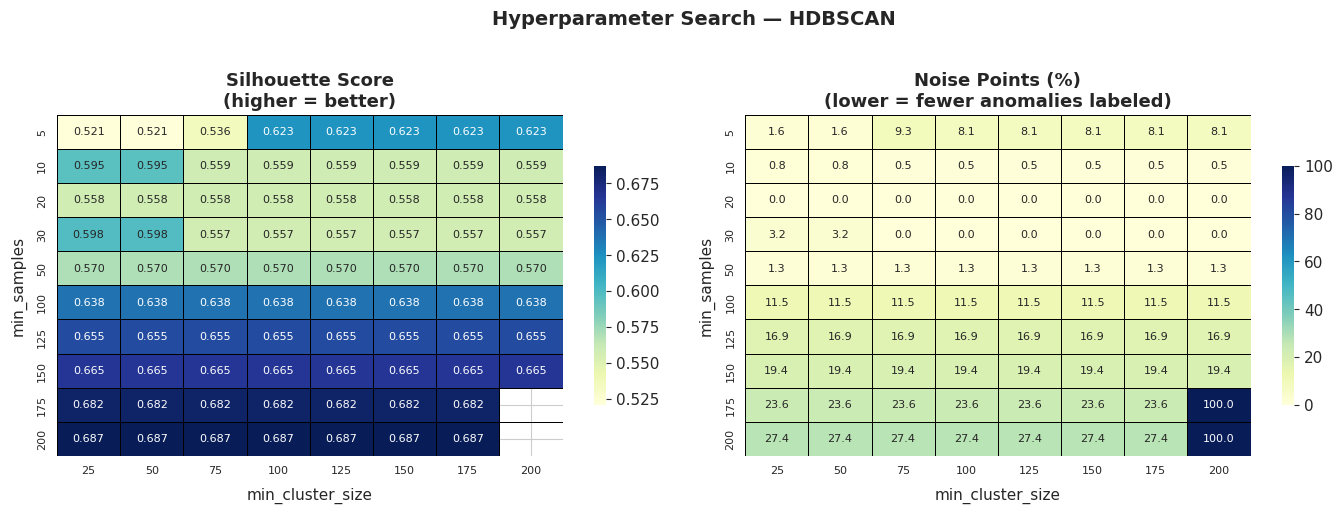

In [ ]:
# ── Visualize the hyperparameter search results ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Hyperparameter Search — HDBSCAN', fontsize=14, fontweight='bold', y=1.02)

# Pivot for heatmap
for ax, metric, title, fmt in zip(
        axes,
        ['silhouette', 'noise_pct'],
        ['Silhouette Score\n(higher = better)', 'Noise Points (%)\n(lower = fewer anomalies labeled)'],
        ['.3f', '.1f']
):
    pivot = results_df.pivot(index='min_samples', columns='min_cluster_size', values=metric)

    cmap = sns.color_palette("YlGnBu", as_cmap=True)
    sns.heatmap(
        pivot, ax=ax, annot=True, fmt=fmt, cmap=cmap,
        linewidths=0.5, linecolor="black",
        cbar_kws={'shrink': 0.7},
        annot_kws={'size': 8}
    )
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('min_cluster_size', labelpad=8)
    ax.set_ylabel('min_samples', labelpad=8)
    ax.tick_params(axis='both', labelsize=8)

plt.tight_layout()
plt.show()

### Final Model Configuration

In [ ]:
valid   = results_df[results_df['noise_pct'] < 30].dropna(subset=['silhouette'])

if len(valid) > 0:
    best_row = valid.loc[valid['silhouette'].idxmax()]
else:
    best_row = pd.Series({'min_cluster_size': 100, 'min_samples': 10,
                          'silhouette': np.nan, 'noise_pct': np.nan})

BEST_MCS = int(best_row['min_cluster_size'])
BEST_MS  = int(best_row['min_samples'])

print("FINAL MODEL CONFIGURATION")
print(f"\tAlgorithm        : HDBSCAN")
print(f"\tmin_cluster_size : {BEST_MCS:<21}")
print(f"\tmin_samples      : {BEST_MS:<21}")
print(f"\tmetric           : euclidean")
print(f"\tInput dimensions : {N_COMPONENTS_FULL} ({HDBSCAN_REDUCTION_METHOD} components) ")

FINAL MODEL CONFIGURATION
	Algorithm        : HDBSCAN
	min_cluster_size : 25                   
	min_samples      : 200                  
	metric           : euclidean
	Input dimensions : 10 (UMAP components) 


### Model Training

In [ ]:
print(f"Training HDBSCAN (min_cluster_size={BEST_MCS}, min_samples={BEST_MS})...")

final_model = hdbscan.HDBSCAN(
    min_cluster_size=BEST_MCS,
    min_samples=BEST_MS,
    metric='euclidean',
    cluster_selection_method='eom',
    prediction_data=True
)
cluster_labels = final_model.fit_predict(X_reduced)

# ── Extract outlier scores ─────────────────────────────────────────────────
outlier_scores = final_model.outlier_scores_

# ── Summary ───────────────────────────────────────────────────────────────
unique_labels = sorted(set(cluster_labels))
n_clusters    = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise       = (cluster_labels == -1).sum()

print(f"\n{'─'*45}")
print(f"Unique labels      : {unique_labels}")
print(f"Number of clusters : {n_clusters}")
print(f"Noise points (-1)  : {n_noise:,} ({n_noise/len(cluster_labels)*100:.1f}%)")
print(f"Total points       : {len(cluster_labels):,}")
print(f"{'─'*45}")

for lbl in unique_labels:
    cnt = (cluster_labels == lbl).sum()
    tag = "← EXTREME" if lbl == -1 else ""
    print(f"Cluster {lbl:>3} : {cnt:>6,} points  {tag}")

Training HDBSCAN (min_cluster_size=25, min_samples=200)...

─────────────────────────────────────────────
Unique labels      : [np.int64(-1), np.int64(0), np.int64(1)]
Number of clusters : 2
Noise points (-1)  : 203 (27.4%)
Total points       : 741
─────────────────────────────────────────────
Cluster  -1 :    203 points  ← EXTREME
Cluster   0 :    181 points  
Cluster   1 :    357 points  


### Silhouette Analysis

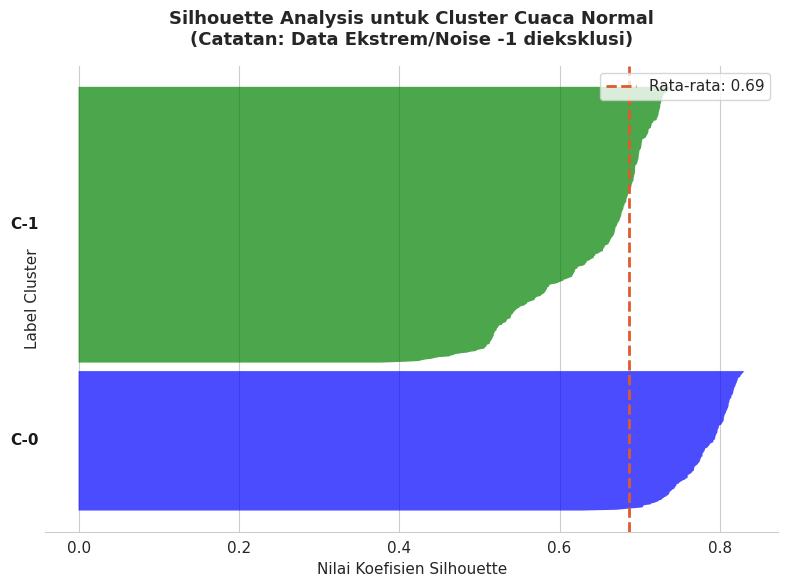

In [ ]:
# Exclude Noise (-1)
mask_normal = cluster_labels != -1
X_normal = X_reduced[mask_normal]
y_normal = cluster_labels[mask_normal]
unique_normal = np.unique(y_normal)

if len(unique_normal) > 1:
    # Hitung koefisien silhouette per baris data
    sil_scores = silhouette_samples(X_normal, y_normal)
    sil_avg = silhouette_score(X_normal, y_normal)

    # Setup Plot Visual
    fig, ax = plt.subplots(figsize=(8, 6))
    y_lower = 10

    for i, cluster_id in enumerate(unique_normal):
        ith_cluster_sil_values = sil_scores[y_normal == cluster_id]
        ith_cluster_sil_values.sort()

        size_cluster_i = ith_cluster_sil_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = NORMAL_COLORS[i % len(NORMAL_COLORS)]
        ax.fill_betweenx(np.arange(y_lower, y_upper),
                         0, ith_cluster_sil_values,
                         facecolor=color, edgecolor='none', alpha=0.7)

        # Labeling
        ax.text(-0.05, y_lower + 0.5 * size_cluster_i, f"C-{cluster_id}",
                color='#1A1A1A', ha='right', va='center', fontweight='bold')

        y_lower = y_upper + 10

    ax.axvline(x=sil_avg, color=EXTREME_COLORS[0], linestyle="--", linewidth=2,
               label=f'Rata-rata: {sil_avg:.2f}')

    ax.set_title("Silhouette Analysis untuk Cluster Cuaca Normal\n(Catatan: Data Ekstrem/Noise -1 dieksklusi)",
                 fontweight='bold', pad=15)
    ax.set_xlabel("Nilai Koefisien Silhouette")
    ax.set_ylabel("Label Cluster")

    ax.set_yticks([])

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

else:
    print("Silhouette Analysis tidak dapat dirender: HDBSCAN hanya mendeteksi 1 kelompok cuaca normal.")

### Model Evaluation

In [ ]:
# ── Silhouette Score (on non-noise points) ────────────────────────────────────
non_noise_mask = cluster_labels != -1
n_non_noise    = non_noise_mask.sum()

if n_clusters >= 2 and n_non_noise > 10:
    sil_score = silhouette_score(
        X_reduced[non_noise_mask],
        cluster_labels[non_noise_mask],
        sample_size=min(10000, n_non_noise),
        random_state=RANDOM_STATE
    )
    print(f"Silhouette Score (non-noise points): {sil_score:.4f}")
else:
    sil_score = np.nan
    print("Silhouette Score not computable (need ≥ 2 clusters with ≥ 10 points)")



# ── Distribution summary ──────────────────────────────────────────────────────
print(f"\n{'─'*45}")
label_counts = pd.Series(cluster_labels).value_counts().sort_index()
print("Cluster distribution:")
for lbl, cnt in label_counts.items():
    pct = cnt / len(cluster_labels) * 100
    tag = '← Extreme / Anomaly' if lbl == -1 else '← Normal cluster'
    print(f"  Label {lbl:>3}: {cnt:>6,} points ({pct:5.1f}%)  {tag}")

Silhouette Score (non-noise points): 0.6872

─────────────────────────────────────────────
Cluster distribution:
  Label  -1:    203 points ( 27.4%)  ← Extreme / Anomaly
  Label   0:    181 points ( 24.4%)  ← Normal cluster
  Label   1:    357 points ( 48.2%)  ← Normal cluster


In [ ]:
# ── DBCV ──────────────────────────────────────────────────────────────────────
try:
    dbcv_score = hdbscan.validity.validity_index(X_reduced.astype(np.float64), cluster_labels)
    print(f"DBCV Score                          : {dbcv_score:.4f}")
    print(f"Interpretation: DBCV ∈ [-1, 1]. Higher = better density separation.")
except Exception as e:
    print(f"DBCV not available: {e}")

DBCV Score                          : 0.5358
Interpretation: DBCV ∈ [-1, 1]. Higher = better density separation.


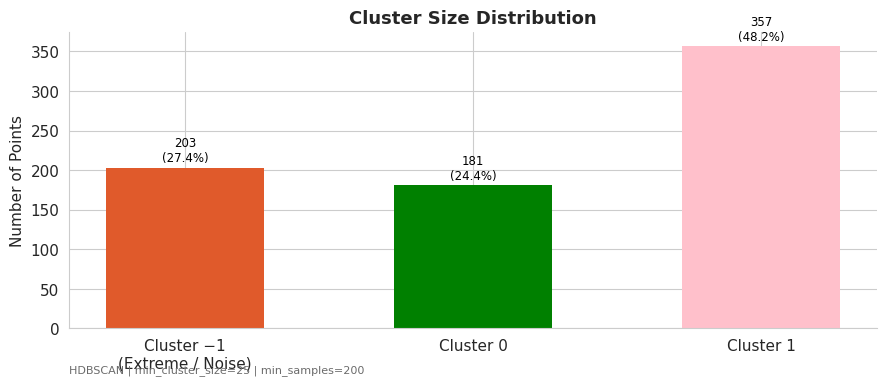

In [ ]:
# ── Evaluation Bar Chart ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))

label_counts_plot = label_counts.copy()
bar_colors = [PALETTE['extreme'] if lbl == -1 else NORMAL_COLORS[i % len(NORMAL_COLORS)]
              for i, lbl in enumerate(label_counts_plot.index)]

bars = ax.bar(
    [f'Cluster {l}' if l != -1 else 'Cluster −1\n(Extreme / Noise)'
     for l in label_counts_plot.index],
    label_counts_plot.values,
    color=bar_colors, width=0.55, edgecolor='none'
)

# Value labels on bars
for bar, val in zip(bars, label_counts_plot.values):
    pct = val / len(cluster_labels) * 100
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + len(cluster_labels) * 0.005,
            f'{val:,}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=8.5,
            color='black')

ax.set_title('Cluster Size Distribution', fontweight='bold')
ax.set_ylabel('Number of Points')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
clean_spines(ax)
ax.set_axisbelow(True)

add_figure_label(ax, f'HDBSCAN | min_cluster_size={BEST_MCS} | min_samples={BEST_MS}')
plt.tight_layout()
plt.show()

### 2D Visualization

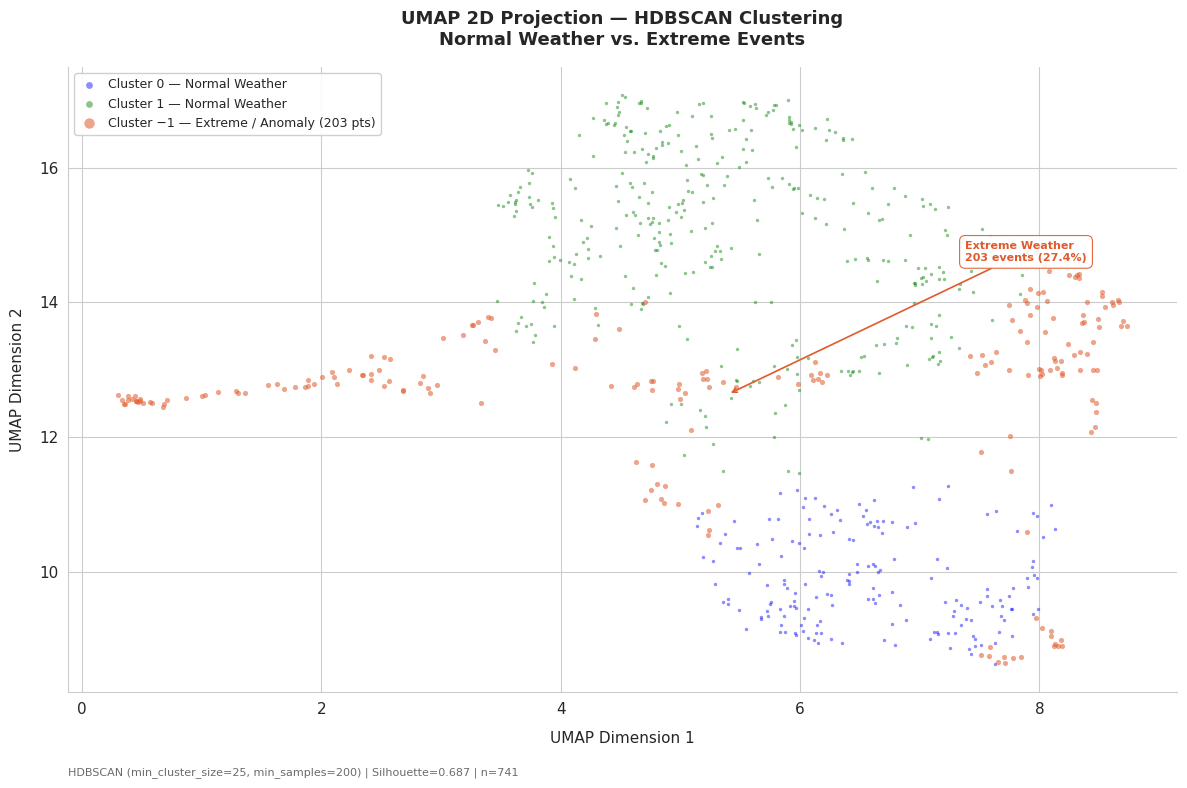

In [ ]:
# ── Build color array for scatter plot ───────────────────────────────────────
unique_non_noise = sorted([l for l in set(cluster_labels) if l != -1])
color_map = {lbl: NORMAL_COLORS[i % len(NORMAL_COLORS)] for i, lbl in enumerate(unique_non_noise)}
color_map[-1] = PALETTE['extreme']

point_colors = [color_map[l] for l in cluster_labels]
point_alphas = [0.25 if l == -1 else 0.50 for l in cluster_labels]
point_sizes  = [12   if l == -1 else 6    for l in cluster_labels]

# ── Main scatter plot ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 8))

# Plot normal clusters
for lbl in unique_non_noise:
    mask = cluster_labels == lbl
    ax.scatter(
        X_2d[mask, 0], X_2d[mask, 1],
        c=color_map[lbl], s=6, alpha=0.45,
        linewidths=0, rasterized=True,
        label=f'Cluster {lbl} — Normal Weather'
    )

# Plot noise / extreme points
noise_mask = cluster_labels == -1
ax.scatter(
    X_2d[noise_mask, 0], X_2d[noise_mask, 1],
    c=PALETTE['extreme'], s=14, alpha=0.55,
    linewidths=0, rasterized=True,
    label=f'Cluster −1 — Extreme / Anomaly ({noise_mask.sum():,} pts)'
)

# ── Annotations ──────────────────────────────────────────────────────────────
ax.set_title(
    f'{HDBSCAN_REDUCTION_METHOD} 2D Projection — HDBSCAN Clustering\n'
    f'Normal Weather vs. Extreme Events',
    fontweight='bold', pad=16
)
ax.set_xlabel(f'{HDBSCAN_REDUCTION_METHOD} Dimension 1', labelpad=10)
ax.set_ylabel(f'{HDBSCAN_REDUCTION_METHOD} Dimension 2', labelpad=10)

# Legend
legend = ax.legend(
    loc='upper left', frameon=True, framealpha=0.92, fontsize=9, markerscale=2.0, handlelength=1.5
)

# Annotate extreme cluster with a callout
if noise_mask.sum() > 0:
    # Find centroid of extreme points
    cx, cy = X_2d[noise_mask, 0].mean(), X_2d[noise_mask, 1].mean()
    ax.annotate(
        f'Extreme Weather\n{noise_mask.sum():,} events ({noise_mask.sum()/len(cluster_labels)*100:.1f}%)',
        xy=(cx, cy),
        xytext=(cx + 2, cy + 2),
        fontsize=8,
        color=PALETTE['extreme'],
        fontweight='bold',
        arrowprops=dict(arrowstyle='->', color=PALETTE['extreme'], lw=1.2, shrinkA=0, shrinkB=4),
        bbox=dict(boxstyle='round,pad=0.5', edgecolor=PALETTE['extreme'], facecolor='white', linewidth=0.8, alpha=0.9)
    )

clean_spines(ax)
ax.set_axisbelow(True)
add_figure_label(
    ax,
    f'HDBSCAN (min_cluster_size={BEST_MCS}, min_samples={BEST_MS}) | '
    f'Silhouette={sil_score:.3f} | n={len(cluster_labels):,}'
)

plt.tight_layout()
plt.show()

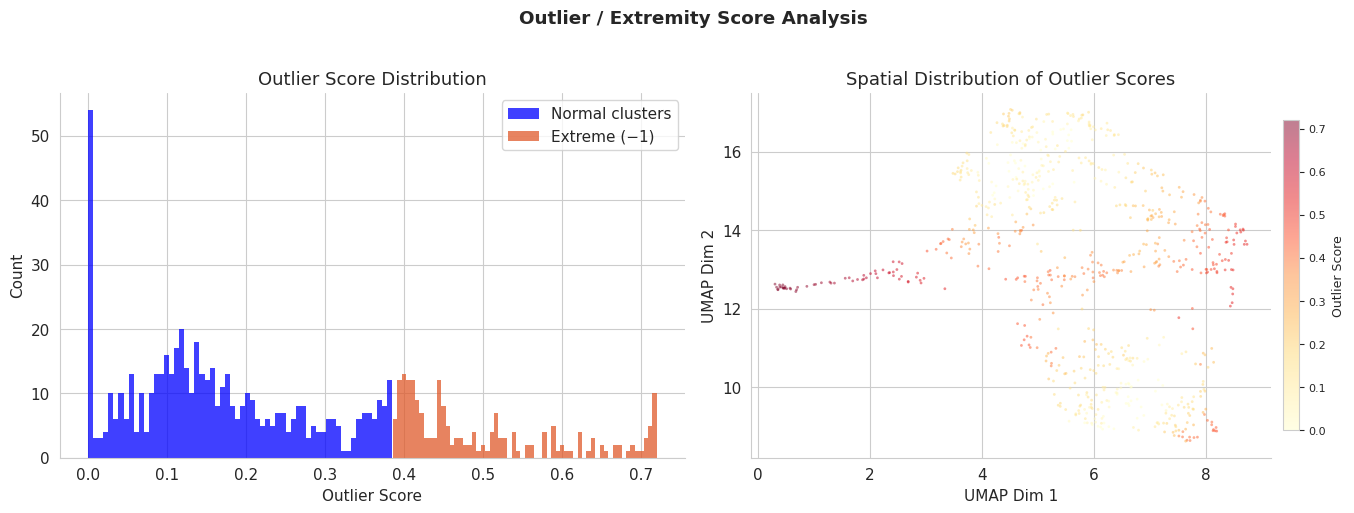

In [ ]:
# ── Supplementary: Outlier Score Distribution ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Outlier / Extremity Score Analysis', fontweight='bold', y=1.02)

# Left: Histogram of outlier scores
ax = axes[0]
outlier_normal  = outlier_scores[cluster_labels != -1]
outlier_extreme = outlier_scores[cluster_labels == -1]

ax.hist(outlier_normal, bins=60, color=PALETTE['normal_0'], alpha=0.75, label='Normal clusters', edgecolor='none')
ax.hist(outlier_extreme, bins=60, color=PALETTE['extreme'], alpha=0.75, label='Extreme (−1)', edgecolor='none')
ax.set_xlabel('Outlier Score')
ax.set_ylabel('Count')
ax.set_title('Outlier Score Distribution')
ax.legend()
clean_spines(ax)

# Right: 2D scatter colored by outlier score
ax = axes[1]
sc = ax.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=outlier_scores, cmap='YlOrRd',
    s=4, alpha=0.5, linewidths=0, rasterized=True
)
cbar = plt.colorbar(sc, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label('Outlier Score', fontsize=9)
cbar.ax.tick_params(labelsize=8)
ax.set_title('Spatial Distribution of Outlier Scores')
ax.set_xlabel(f'{HDBSCAN_REDUCTION_METHOD} Dim 1')
ax.set_ylabel(f'{HDBSCAN_REDUCTION_METHOD} Dim 2')
clean_spines(ax)

plt.tight_layout()
plt.show()

### Cluster Profiling

In [ ]:
# ── Attach cluster labels back to the original (unscaled) dataframe ──────────
df_clustered = df.copy()
df_clustered['cluster'] = cluster_labels
df_clustered['outlier_score'] = outlier_scores
df_clustered['cluster_label'] = df_clustered['cluster'].apply(
    lambda x: 'Extreme / Anomaly' if x == -1 else f'Normal (Cluster {x})'
)

# ── Mean feature values per cluster ──────────────────────────────────────────
KEY_FEATURES = [
    'temperature_2m (°C)',
    'relative_humidity_2m (%)',
    'dew_point_2m (°C)',
    'apparent_temperature (°C)',
    'pressure_msl (hPa)',
    'cloud_cover (%)',
    'vapour_pressure_deficit (kPa)',
    'wind_speed_10m (km/h)',
    'wind_speed_100m (km/h)',
    'wind_gusts_10m (km/h)',
    'shortwave_radiation (W/m²)',
    'terrestrial_radiation (W/m²)',
    'soil_moisture_0_to_7cm (m³/m³)',
    'sunshine_duration (s)',
    'outlier_score',
]
key_features_present = [f for f in KEY_FEATURES if f in df_clustered.columns]

profile = (df_clustered
           .groupby('cluster')[key_features_present]
           .agg(['mean', 'std'])
           .round(3))

print("Cluster Profile - Mean ± Std of Key Features:")
print(profile.to_string())

Cluster Profile - Mean ± Std of Key Features:
        temperature_2m (°C)        relative_humidity_2m (%)        dew_point_2m (°C)        apparent_temperature (°C)        pressure_msl (hPa)        cloud_cover (%)         wind_speed_10m (km/h)        wind_speed_100m (km/h)          wind_gusts_10m (km/h)        shortwave_radiation (W/m²)          terrestrial_radiation (W/m²)        sunshine_duration (s)        outlier_score       
                       mean    std                     mean    std              mean    std                      mean    std               mean    std            mean     std                  mean    std                   mean      std                  mean    std                       mean      std                         mean    std                  mean    std          mean    std
cluster                                                                                                                                                                             

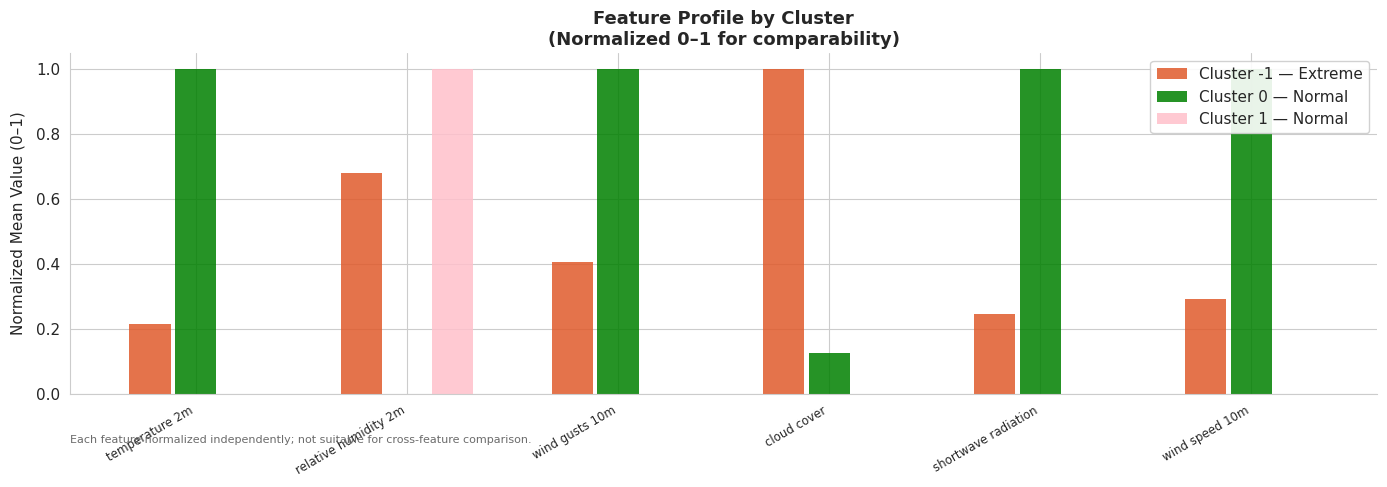

In [ ]:
# ── Radar / Bar Chart for key feature comparison ─────────────────────────────
RADAR_FEATURES = [
    f for f in [
        'temperature_2m (°C)', 'relative_humidity_2m (%)',
        'wind_gusts_10m (km/h)', 'cloud_cover (%)',
        'vapour_pressure_deficit (kPa)', 'shortwave_radiation (W/m²)',
        'wind_speed_10m (km/h)', 'soil_moisture_0_to_7cm (m³/m³)'
    ] if f in df_clustered.columns
]

means = df_clustered.groupby('cluster')[RADAR_FEATURES].mean()
# Normalize
means_norm = (means - means.min()) / (means.max() - means.min() + 1e-9)

# ── Grouped bar chart ─────────────────────────────────────────────────────────
n_feats   = len(RADAR_FEATURES)
n_labels  = len(means.index)
x_pos     = np.arange(n_feats)
bar_width = 0.65 / n_labels

fig, ax = plt.subplots(figsize=(14, 5))

for i, (lbl, row) in enumerate(means_norm.iterrows()):
    color = PALETTE['extreme'] if lbl == -1 else NORMAL_COLORS[i % len(NORMAL_COLORS)]
    label_txt = f'Cluster {lbl} — Extreme' if lbl == -1 else f'Cluster {lbl} — Normal'
    ax.bar(
        x_pos + i * bar_width - (n_labels - 1) * bar_width / 2,
        row.values, width=bar_width * 0.9,
        color=color, alpha=0.85, label=label_txt, edgecolor='none'
    )

ax.set_xticks(x_pos)
ax.set_xticklabels(
    [f.split('(')[0].strip().replace('_', ' ') for f in RADAR_FEATURES],
    rotation=30, ha='right', fontsize=8.5
)
ax.set_ylabel('Normalized Mean Value (0–1)', labelpad=8)
ax.set_title('Feature Profile by Cluster\n(Normalized 0–1 for comparability)', fontweight='bold')
ax.legend(loc='upper right', frameon=True, framealpha=0.9, facecolor='white')
clean_spines(ax)
ax.set_axisbelow(True)

add_figure_label(ax, 'Each feature normalized independently; not suitable for cross-feature comparison.')
plt.tight_layout()
plt.show()

### Outlier Analysis

🌪️  Top 20 Most Extreme Weather Events (highest outlier score):
 wind_gusts_10m (km/h)  temperature_2m (°C)  relative_humidity_2m (%)  cloud_cover (%)  shortwave_radiation (W/m²)  outlier_score  cluster
                  26.5                 24.5                      89.0             33.0                          43       0.719632       -1
                  29.0                 27.7                      80.0            100.0                         524       0.717413       -1
                  26.0                 24.3                      89.0            100.0                          21       0.716970       -1
                  25.8                 24.3                      91.0             13.0                           4       0.716865       -1
                  29.5                 26.0                      82.0             41.0                         427       0.716696       -1
                  26.8                 24.4                      92.0             85.0                

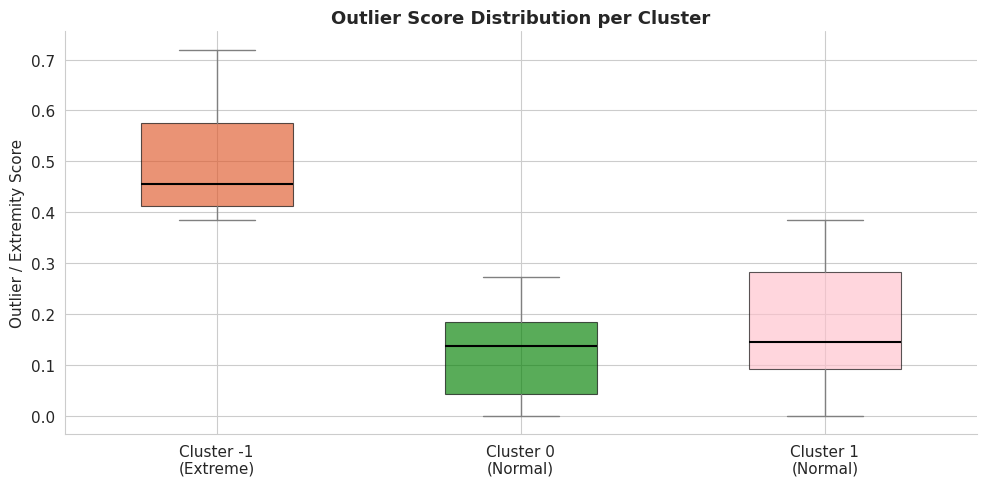

In [ ]:
# ── Top extreme weather events by outlier score ───────────────────────────────
top_extreme = (df_clustered[df_clustered['cluster'] == -1]
               .sort_values('outlier_score', ascending=False)
               .head(20))

display_cols = [c for c in [
    'wind_gusts_10m (km/h)', 'temperature_2m (°C)',
    'relative_humidity_2m (%)', 'cloud_cover (%)',
    'vapour_pressure_deficit (kPa)', 'shortwave_radiation (W/m²)',
    'outlier_score', 'cluster'
] if c in df_clustered.columns]

print("🌪️  Top 20 Most Extreme Weather Events (highest outlier score):")
print(top_extreme[display_cols].to_string(index=False))

# ── Box plots: outlier score per cluster ─────────────────────────────────────
print("\nBox plots:")

fig, ax = plt.subplots(figsize=(10, 5))

cluster_order = sorted(df_clustered['cluster'].unique())
data_by_cluster = [df_clustered[df_clustered['cluster'] == c]['outlier_score'].values
                   for c in cluster_order]
box_colors = [PALETTE['extreme'] if c == -1 else NORMAL_COLORS[i % len(NORMAL_COLORS)]
              for i, c in enumerate(cluster_order)]

bp = ax.boxplot(
    data_by_cluster,
    patch_artist=True,
    medianprops=dict(color='black', linewidth=1.5),
    whiskerprops=dict(color='gray', linewidth=1),
    capprops=dict(color='gray', linewidth=1),
    flierprops=dict(marker='o', markersize=3, alpha=0.3,
                    markerfacecolor=PALETTE['extreme_alt'],
                    markeredgecolor='none'),
    widths=0.5
)

for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)
    patch.set_linewidth(0.8)

ax.set_xticklabels(
    [f'Cluster {c}\n(Extreme)' if c == -1 else f'Cluster {c}\n(Normal)'
     for c in cluster_order]
)
ax.set_ylabel('Outlier / Extremity Score')
ax.set_title('Outlier Score Distribution per Cluster', fontweight='bold')
clean_spines(ax)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Physical Interpretation

In [ ]:
# ── Clean comparison table: Normal (all non-noise) vs Extreme (-1) ───────────
COMPARE_FEATURES = [
    f for f in [
        'temperature_2m (°C)',
        'apparent_temperature (°C)',
        'relative_humidity_2m (%)',
        'dew_point_2m (°C)',
        'pressure_msl (hPa)',
        'cloud_cover (%)',
        'vapour_pressure_deficit (kPa)',
        'wind_speed_10m (km/h)',
        'wind_gusts_10m (km/h)',
        'shortwave_radiation (W/m²)',
        'terrestrial_radiation (W/m²)',
        'sunshine_duration (s)',
        'soil_moisture_0_to_7cm (m³/m³)',
        'outlier_score',
    ] if f in df_clustered.columns
]

df_clustered['weather_type'] = np.where(df_clustered['cluster'] == -1, 'Extreme / Anomaly', 'Normal')

comparison = (df_clustered
              .groupby('weather_type')[COMPARE_FEATURES]
              .agg(['mean', 'median', 'std'])
              .round(3))

# Flatten multi-level columns for readability
comparison.columns = ['_'.join(c) for c in comparison.columns]

# ── Print the mean comparison ─────────────────────────────────────────────────
mean_compare = df_clustered.groupby('weather_type')[COMPARE_FEATURES].mean().round(3).T
mean_compare.columns.name = None

# Add % difference column
if 'Normal' in mean_compare.columns and 'Extreme / Anomaly' in mean_compare.columns:
    mean_compare['Δ (Extreme − Normal)'] = (
        mean_compare['Extreme / Anomaly'] - mean_compare['Normal']
    ).round(3)
    mean_compare['Δ%'] = (
        (mean_compare['Δ (Extreme − Normal)'] / mean_compare['Normal'].abs().replace(0, 1)) * 100
    ).round(1)

print(mean_compare.to_string())
print("\nNote: Positive Δ% -> extreme weather has HIGHER values; Negative -> LOWER values.")

                              Extreme / Anomaly   Normal  Δ (Extreme − Normal)      Δ%
temperature_2m (°C)                      24.344   24.794                -0.450    -1.8
apparent_temperature (°C)                28.353   29.054                -0.701    -2.4
relative_humidity_2m (%)                 85.300   85.058                 0.242     0.3
dew_point_2m (°C)                        21.587   22.017                -0.430    -2.0
pressure_msl (hPa)                      987.003  986.473                 0.530     0.1
cloud_cover (%)                          43.946   25.790                18.156    70.4
wind_speed_10m (km/h)                     8.771    8.883                -0.112    -1.3
wind_gusts_10m (km/h)                    25.469   25.238                 0.231     0.9
shortwave_radiation (W/m²)               97.473  131.398               -33.925   -25.8
terrestrial_radiation (W/m²)              0.512    0.504                 0.008     1.6
sunshine_duration (s)                     1

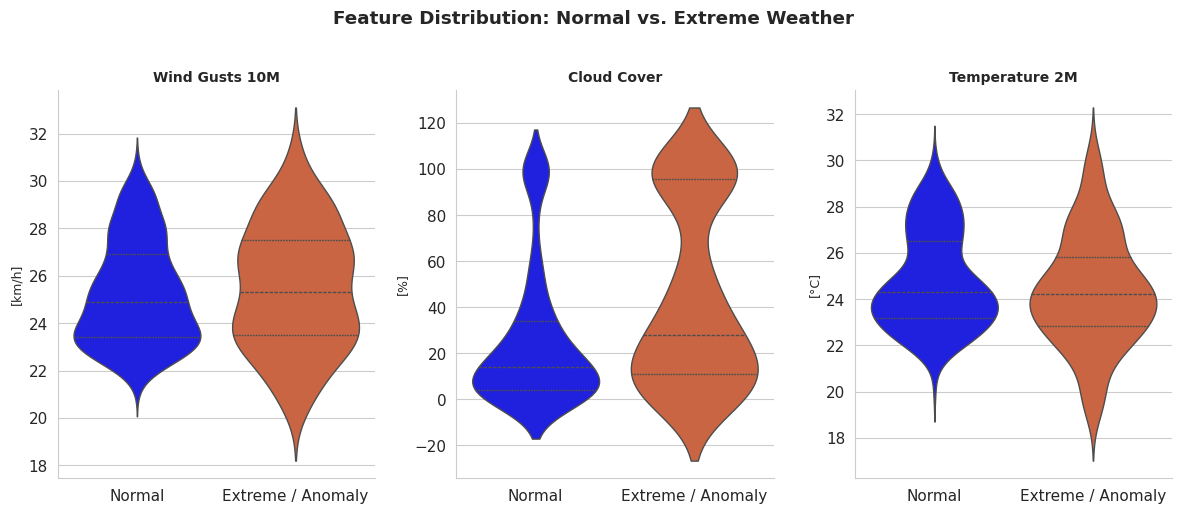

In [ ]:
# ── Summary visualization ────
VIOLIN_FEATURES = [
    f for f in [
        'wind_gusts_10m (km/h)',
        'cloud_cover (%)',
        'temperature_2m (°C)',
        'vapour_pressure_deficit (kPa)',
    ] if f in df_clustered.columns
]

if len(VIOLIN_FEATURES) > 0:
    fig, axes = plt.subplots(1, len(VIOLIN_FEATURES), figsize=(4 * len(VIOLIN_FEATURES), 5))
    if len(VIOLIN_FEATURES) == 1:
        axes = [axes]

    fig.suptitle('Feature Distribution: Normal vs. Extreme Weather', fontweight='bold', y=1.02)

    VIOLIN_PALETTE = {'Normal': NORMAL_COLORS[0], 'Extreme / Anomaly': EXTREME_COLORS[0]}

    for ax, feat in zip(axes, VIOLIN_FEATURES):
        sns.violinplot(
            data=df_clustered,
            x='weather_type',
            y=feat,
            ax=ax,
            palette=VIOLIN_PALETTE,
            inner='quart',
            linewidth=1
        )

        short_name = feat.split('(')[0].strip().replace('_', ' ').title()
        unit = feat[feat.find('(')+1:feat.find(')')] if '(' in feat else ''

        ax.set_title(short_name, fontsize=10, fontweight='bold')
        ax.set_ylabel(f'[{unit}]' if unit else '', fontsize=9)
        ax.set_xlabel('')

        sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()

### HDBSCAN Summary

**Topografi dan Struktur Cluster**

Model HDBSCAN (`min_cluster_size=25`, `min_samples=200`) secara efektif mengelompokkan 741 observasi ke dalam tiga profil ruang data. Dua cluster utama (0 dan 1) membentuk wilayah kepadatan cuaca normal, sedangkan Cluster -1 mengisolasi 203 observasi (27,4%) sebagai anomali atau cuaca ekstrem. Proyeksi UMAP 2D memvisualisasikan pemisahan ini: cluster normal menempati area spasial yang terpusat di atas dan bawah, sementara anomali tersebar memanjang di area tengah, mencerminkan heterogenitas alami dari kejadian ekstrem yang tidak terpusat pada satu titik tunggal.

**Pemetaan Karakteristik Meteorologi**

Berdasarkan metrik profil fitur dan distribusi visual, tiap cluster merepresentasikan fenomena fisik yang berbeda:

- Cluster -1 (Ekstrem / Anomali): Didominasi oleh tingkat tutupan awan yang maksimal (mendekati 1.0) dengan suhu, radiasi matahari, dan kecepatan angin yang menurun drastis. Profil ini merupakan sinyal meteorologis yang sangat kuat untuk kondisi badai aktif atau pra-badai, di mana penetrasi matahari terblokir sepenuhnya oleh awan tebal.

- Cluster 0 (Normal - Tropis Cerah): Memiliki suhu, hembusan angin (wind gusts), dan radiasi matahari tertinggi dengan tutupan awan yang sangat minim.

- Cluster 1 (Normal - Transisi Lembap): Dicirikan oleh kelembapan relatif tertinggi dengan parameter lainnya berada di level moderat, merepresentasikan cuaca mendung ringan.

**Kuantifikasi Kualitas Separasi**

Separasi antar-cluster tervalidasi secara solid oleh Silhouette Score sebesar 0,687. Hal ini diperkuat oleh analisis Outlier Score yang membentuk distribusi bimodal tegas: kelompok normal terpusat pada skor sangat rendah (median ~0,14), sedangkan cluster anomali memiliki variansi tinggi di rentang 0,38–0,58. Ini membuktikan bahwa HDBSCAN secara konsisten mengenali cuaca ekstrem sebagai data yang terlempar jauh dari inti kepadatan (dense core).

**Limitasi Fitur dan Temuan Kritis**

Terdapat overlap distribusi yang signifikan pada fitur Suhu dan Wind Gusts antara cuaca normal dan ekstrem. Ini mengindikasikan bahwa kedua fitur tersebut bukan diskriminator utama; pembentukan cluster anomali justru dikendalikan oleh interaksi tutupan awan dan penurunan radiasi. Selain itu, sebaran Cluster -1 yang memanjang menunjukkan bahwa 'cuaca ekstrem' dalam data ini merangkum berbagai jenis anomali yang berbeda-beda, bukan hanya satu tipe cuaca buruk saja.

---
## Agglomerative Hierarchical

Data Ingestion

In [ ]:
df_raw = pd.read_csv('train.csv', encoding='latin-1')

print(f"Shape  : {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Raw column names:")
for c in df_raw.columns:
    print(f"  {repr(c)}")

Shape  : 14,016 rows × 36 columns
Raw column names:
  'ID'
  'time'
  'temperature_2m (Â\x81EÂ\x81EC)'
  'relative_humidity_2m (%)'
  'dew_point_2m (Â\x81EÂ\x81EC)'
  'apparent_temperature (Â\x81EÂ\x81EC)'
  'pressure_msl (hPa)'
  'surface_pressure (hPa)'
  'cloud_cover (%)'
  'cloud_cover_low (%)'
  'cloud_cover_mid (%)'
  'cloud_cover_high (%)'
  'vapour_pressure_deficit (kPa)'
  'wind_speed_10m (km/h)'
  'wind_speed_100m (km/h)'
  'wind_direction_10m (Â\x81EÂ\x81E)'
  'wind_direction_100m (Â\x81EÂ\x81E)'
  'wind_gusts_10m (km/h)'
  'soil_temperature_0_to_7cm (Â\x81EÂ\x81EC)'
  'soil_temperature_7_to_28cm (Â\x81EÂ\x81EC)'
  'soil_temperature_28_to_100cm (Â\x81EÂ\x81EC)'
  'soil_temperature_100_to_255cm (Â\x81EÂ\x81EC)'
  'soil_moisture_0_to_7cm (m?/m?)'
  'soil_moisture_7_to_28cm (m?/m?)'
  'soil_moisture_28_to_100cm (m?/m?)'
  'soil_moisture_100_to_255cm (m?/m?)'
  'shortwave_radiation (W/m?)'
  'direct_radiation (W/m?)'
  'diffuse_radiation (W/m?)'
  'direct_normal_irradiance (W/m?

Fase **Pemasukan Data** berfokus pada pemuatan dataset mentah ke dalam notebook. Ini membaca file `train.csv` ke dalam DataFrame pandas (`df_raw`) dan kemudian mencetak bentuknya (jumlah baris dan kolom) serta nama kolom mentah. Ini memberikan gambaran awal tentang struktur data.

Data Cleaning

In [ ]:
ENCODING_MAP = [
    (r'\\x81E\\x81EC|\x81E\x81EC|\x81e\x81ec|ï¿½Cï¿½C|°C', '°C'),
    (r'\\x81E\\x81E|\x81E\x81E|\x81e\x81e|ï¿½ï¿½|°(?!C)', '°'),
    (r'm\?/m\?|m³/m³|m3/m3', 'm³/m³'),
    (r'W/m\?|W/m²|W/m2', 'W/m²'),
]

def fix_column_names(columns):
    fixed = []
    for col in columns:
        new_col = col
        for pattern, replacement in ENCODING_MAP:
            new_col = re.sub(pattern, replacement, new_col)
        fixed.append(new_col)
    return fixed

df = df_raw.copy()
df.columns = fix_column_names(df.columns)

CANONICAL_COLUMNS = [
    'ID', 'time',
    'temperature_2m (°C)', 'relative_humidity_2m (%)', 'dew_point_2m (°C)',
    'apparent_temperature (°C)', 'precipitation (mm)',
    'pressure_msl (hPa)', 'surface_pressure (hPa)',
    'cloud_cover (%)', 'cloud_cover_low (%)', 'cloud_cover_mid (%)', 'cloud_cover_high (%)',
    'vapour_pressure_deficit (kPa)',
    'wind_speed_10m (km/h)', 'wind_speed_100m (km/h)',
    'wind_direction_10m (°)', 'wind_direction_100m (°)',
    'wind_gusts_10m (km/h)',
    'soil_temperature_0_to_7cm (°C)', 'soil_temperature_7_to_28cm (°C)',
    'soil_temperature_28_to_100cm (°C)', 'soil_temperature_100_to_255cm (°C)',
    'soil_moisture_0_to_7cm (m³/m³)', 'soil_moisture_7_to_28cm (m³/m³)',
    'soil_moisture_28_to_100cm (m³/m³)', 'soil_moisture_100_to_255cm (m³/m³)',
    'shortwave_radiation (W/m²)', 'direct_radiation (W/m²)',
    'diffuse_radiation (W/m²)', 'direct_normal_irradiance (W/m²)',
    'global_tilted_irradiance (W/m²)', 'terrestrial_radiation (W/m²)',
    'is_day', 'sunshine_duration (s)', 'electricity_shutdown'
]

if len(df.columns) == len(CANONICAL_COLUMNS):
    df.columns = CANONICAL_COLUMNS

print(f"\nFeature list:")
for i, col in enumerate(df.columns):
    print(f"\t[{i:02d}] {col}")


Feature list:
	[00] ID
	[01] time
	[02] temperature_2m (°C)
	[03] relative_humidity_2m (%)
	[04] dew_point_2m (°C)
	[05] apparent_temperature (°C)
	[06] precipitation (mm)
	[07] pressure_msl (hPa)
	[08] surface_pressure (hPa)
	[09] cloud_cover (%)
	[10] cloud_cover_low (%)
	[11] cloud_cover_mid (%)
	[12] cloud_cover_high (%)
	[13] vapour_pressure_deficit (kPa)
	[14] wind_speed_10m (km/h)
	[15] wind_speed_100m (km/h)
	[16] wind_direction_10m (°)
	[17] wind_direction_100m (°)
	[18] wind_gusts_10m (km/h)
	[19] soil_temperature_0_to_7cm (°C)
	[20] soil_temperature_7_to_28cm (°C)
	[21] soil_temperature_28_to_100cm (°C)
	[22] soil_temperature_100_to_255cm (°C)
	[23] soil_moisture_0_to_7cm (m³/m³)
	[24] soil_moisture_7_to_28cm (m³/m³)
	[25] soil_moisture_28_to_100cm (m³/m³)
	[26] soil_moisture_100_to_255cm (m³/m³)
	[27] shortwave_radiation (W/m²)
	[28] direct_radiation (W/m²)
	[29] diffuse_radiation (W/m²)
	[30] direct_normal_irradiance (W/m²)
	[31] global_tilted_irradiance (W/m²)
	[32] terr

In [ ]:
print("=" * 55)
print("NULL VALUES PER COLUMN")
print("=" * 55)
null_summary = df.isnull().sum()
null_pct = (null_summary / len(df) * 100).round(2)
null_df = pd.DataFrame({'count': null_summary, 'pct (%)': null_pct})
print(null_df[null_df['count'] > 0].to_string())

n_dupes = df.duplicated().sum()
print(f"\nDuplicate rows : {n_dupes}")

# ── Remove nulls & duplicates ───────────────────────────────────────────
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(f"\nAfter cleaning: {df.shape[0]:,} rows × {df.shape[1]} columns")

NULL VALUES PER COLUMN
                                 count  pct (%)
temperature_2m (°C)               6425    45.84
relative_humidity_2m (%)          1395     9.95
pressure_msl (hPa)                1465    10.45
surface_pressure (hPa)            3494    24.93
cloud_cover (%)                   2832    20.21
cloud_cover_low (%)               2081    14.85
cloud_cover_high (%)              1413    10.08
vapour_pressure_deficit (kPa)     2781    19.84
wind_speed_100m (km/h)            1340     9.56
wind_direction_10m (°)            1457    10.40
wind_direction_100m (°)           2100    14.98
soil_moisture_7_to_28cm (m³/m³)   1389     9.91
global_tilted_irradiance (W/m²)   1363     9.72
is_day                            1346     9.60
sunshine_duration (s)             2869    20.47
electricity_shutdown              2827    20.17

Duplicate rows : 0

After cleaning: 741 rows × 36 columns


Bagian **Pembersihan Data** sangat penting untuk menyiapkan dataset dengan menangani inkonsistensi dan nilai yang hilang. Ini melakukan dua tugas utama:

1.  **Memperbaiki Nama Kolom yang Rusak**: Menggunakan (`ENCODING_MAP`) untuk menstandarisasi dan membersihkan karakter khusus membuatnya lebih mudah dibaca dan konsisten.
2.  **Menangani Nilai Null & Duplikat**: Memeriksa persentase nilai null per kolom dan menghitung baris duplikat. Selanjutnya, menghapus semua baris yang berisi nilai null (`dropna()`) dan setiap baris duplikat yang persis sama (`drop_duplicates()`), memastikan kualitas data untuk analisis lebih lanjut.

Data Transformation

In [ ]:
# ── Parse 'time' column ──────────────────────────────────────────────────────
df['time'] = pd.to_datetime(df['time'], errors='coerce')
df = df.dropna(subset=['time'])

# ── Extract raw temporal features ────────────────────────────────────────────
df['hour']  = df['time'].dt.hour
df['month'] = df['time'].dt.month

# ── Cyclical encoding ────────────────────────────────────────────────────────
df['hour_sin']  = np.sin(2 * np.pi * df['hour']  / 24)
df['hour_cos']  = np.cos(2 * np.pi * df['hour']  / 24)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

# Drop raw time
df = df.drop(columns=['time', 'hour', 'month'])

print(f"\nFeature list:")
for i, col in enumerate(df.columns):
    print(f"\t[{i:02d}] {col}")


Feature list:
	[00] ID
	[01] temperature_2m (°C)
	[02] relative_humidity_2m (%)
	[03] dew_point_2m (°C)
	[04] apparent_temperature (°C)
	[05] precipitation (mm)
	[06] pressure_msl (hPa)
	[07] surface_pressure (hPa)
	[08] cloud_cover (%)
	[09] cloud_cover_low (%)
	[10] cloud_cover_mid (%)
	[11] cloud_cover_high (%)
	[12] vapour_pressure_deficit (kPa)
	[13] wind_speed_10m (km/h)
	[14] wind_speed_100m (km/h)
	[15] wind_direction_10m (°)
	[16] wind_direction_100m (°)
	[17] wind_gusts_10m (km/h)
	[18] soil_temperature_0_to_7cm (°C)
	[19] soil_temperature_7_to_28cm (°C)
	[20] soil_temperature_28_to_100cm (°C)
	[21] soil_temperature_100_to_255cm (°C)
	[22] soil_moisture_0_to_7cm (m³/m³)
	[23] soil_moisture_7_to_28cm (m³/m³)
	[24] soil_moisture_28_to_100cm (m³/m³)
	[25] soil_moisture_100_to_255cm (m³/m³)
	[26] shortwave_radiation (W/m²)
	[27] direct_radiation (W/m²)
	[28] diffuse_radiation (W/m²)
	[29] direct_normal_irradiance (W/m²)
	[30] global_tilted_irradiance (W/m²)
	[31] terrestrial_rad

Bagian **Transformasi Data** berfokus pada pembuatan fitur baru dari fitur yang sudah ada, khususnya fitur temporal. Ini melakukan langkah-langkah berikut:

1.  **Mengurai kolom 'time'**: Mengubah kolom `time` menjadi objek datetime dan menghapus baris di mana konversi ini gagal.
2.  **Mengekstrak Fitur Temporal Mentah**: Mengekstrak `hour` dan `month` dari kolom `time`.
3.  **Pengkodean Siklis**: Menerapkan transformasi sinus dan kosinus ke `hour` dan `month`. Teknik ini digunakan untuk merepresentasikan fitur siklis tanpa memaksakan urutan buatan, yang bermanfaat untuk model yang mungkin salah menafsirkan representasi linier dari data siklis (misalnya, 23:00 dekat dengan 00:00, tetapi secara linier mereka berjauhan).
4.  **Menghapus Kolom Waktu Mentah**: Menghapus kolom `time`, `hour`, dan `month` asli, karena representasi siklisnya sekarang tersedia.

Feat-Eng

In [ ]:
COLS_TO_DROP = ['ID']

existing_drops = [c for c in COLS_TO_DROP if c in df.columns]
df = df.drop(columns=existing_drops)

print(f"Dropped {len(existing_drops)} column(s): {existing_drops}")
print(f"Remaining features: {df.shape[1]} columns")
print(f"\nFeature list:")
for i, col in enumerate(df.columns):
    print(f"\t[{i:02d}] {col}")

Dropped 1 column(s): ['ID']
Remaining features: 38 columns

Feature list:
	[00] temperature_2m (°C)
	[01] relative_humidity_2m (%)
	[02] dew_point_2m (°C)
	[03] apparent_temperature (°C)
	[04] precipitation (mm)
	[05] pressure_msl (hPa)
	[06] surface_pressure (hPa)
	[07] cloud_cover (%)
	[08] cloud_cover_low (%)
	[09] cloud_cover_mid (%)
	[10] cloud_cover_high (%)
	[11] vapour_pressure_deficit (kPa)
	[12] wind_speed_10m (km/h)
	[13] wind_speed_100m (km/h)
	[14] wind_direction_10m (°)
	[15] wind_direction_100m (°)
	[16] wind_gusts_10m (km/h)
	[17] soil_temperature_0_to_7cm (°C)
	[18] soil_temperature_7_to_28cm (°C)
	[19] soil_temperature_28_to_100cm (°C)
	[20] soil_temperature_100_to_255cm (°C)
	[21] soil_moisture_0_to_7cm (m³/m³)
	[22] soil_moisture_7_to_28cm (m³/m³)
	[23] soil_moisture_28_to_100cm (m³/m³)
	[24] soil_moisture_100_to_255cm (m³/m³)
	[25] shortwave_radiation (W/m²)
	[26] direct_radiation (W/m²)
	[27] diffuse_radiation (W/m²)
	[28] direct_normal_irradiance (W/m²)
	[29] glo

Langkah **Feature Eng** melibatkan pemilihan dan penyempurnaan fitur yang akan digunakan untuk pengelompokan. Ini mengurangi noise dan memfokuskan model pada fitur yang bermakna.

In [ ]:
desc = df.describe().T[['mean', 'std', 'min', 'max']].round(3)
print("Descriptive Statistics:")
print(desc.to_string())

Descriptive Statistics:
                                        mean       std       min       max
temperature_2m (°C)                   24.671     2.212    18.700    30.600
relative_humidity_2m (%)              85.124     8.909    55.000    99.000
dew_point_2m (°C)                     21.899     1.321    16.200    25.800
apparent_temperature (°C)             28.862     2.804    19.900    37.100
precipitation (mm)                  1010.619     1.889  1005.500  1018.500
pressure_msl (hPa)                   986.618     1.800   981.900   994.200
surface_pressure (hPa)                58.377    29.550     0.000   100.000
cloud_cover (%)                       30.764    33.684     0.000   100.000
cloud_cover_low (%)                   23.942    29.484     0.000   100.000
cloud_cover_mid (%)                   74.758    37.577     0.000   100.000
cloud_cover_high (%)                   0.496     0.363     0.030     1.990
vapour_pressure_deficit (kPa)          6.057     3.309     0.000    17.700
w

Bagian **Statistik Deskriptif** ini menyediakan gambaran statistik dari DataFrame yang telah diproses. Ini menghitung dan menampilkan nilai rata-rata (mean), standar deviasi (std), nilai minimum (min), dan nilai maksimum (max) untuk setiap fitur. Ini membantu dalam memahami distribusi dan rentang setiap variabel sebelum proses penskalaan dan pemodelan.

In [ ]:
# ── Log Transform pada Fitur Skewed ─────────────────────────────────────────
SKEW_THRESHOLD = 1.0   # Fitur dengan |skewness| > threshold akan di-transform

# Hanya fitur numerik kontinu (bukan binary seperti electricity_shutdown, is_day)
BINARY_COLS = ['electricity_shutdown', 'is_day']
numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns
                if c not in BINARY_COLS]

# Hitung skewness
skewness = df[numeric_cols].skew().sort_values(ascending=False)
skewed_features = skewness[skewness.abs() > SKEW_THRESHOLD].index.tolist()

print(f"Skewness analysis (threshold = |{SKEW_THRESHOLD}|):")
print(skewness.round(3).to_string())
print(f"\n→ {len(skewed_features)} features to log-transform: {skewed_features}")

# Terapkan log1p hanya pada fitur non-negatif yang skewed
df_transformed = df.copy()
log_transformed_cols = []

for col in skewed_features:
    if df_transformed[col].min() >= 0:
        df_transformed[col] = np.log1p(df_transformed[col])
        log_transformed_cols.append(col)
    else:
        print(f"  ⚠ Skipped '{col}' (contains negative values — use signed log if needed)")

print(f"\n✅ Applied log1p to {len(log_transformed_cols)} features:")
for c in log_transformed_cols:
    print(f"   - {c}")

# Verifikasi: skewness setelah transform
skewness_after = df_transformed[log_transformed_cols].skew().round(3)
print(f"\nSkewness after log1p:")
print(skewness_after.to_string())

df = df_transformed

Skewness analysis (threshold = |1.0|):
sunshine_duration (s)                 6.361
shortwave_radiation (W/m²)            1.546
cloud_cover_low (%)                   1.507
cloud_cover_high (%)                  1.307
diffuse_radiation (W/m²)              1.190
cloud_cover (%)                       1.156
direct_radiation (W/m²)               1.144
direct_normal_irradiance (W/m²)       1.078
soil_moisture_100_to_255cm (m³/m³)    1.078
vapour_pressure_deficit (kPa)         0.862
wind_speed_10m (km/h)                 0.692
global_tilted_irradiance (W/m²)       0.656
wind_direction_100m (°)               0.605
wind_gusts_10m (km/h)                 0.368
temperature_2m (°C)                   0.355
apparent_temperature (°C)             0.285
pressure_msl (hPa)                    0.246
precipitation (mm)                    0.242
month_cos                             0.236
surface_pressure (hPa)                0.138
soil_temperature_28_to_100cm (°C)     0.089
hour_sin                             


 Log Transform pada Fitur Skewed

> Beberapa fitur cuaca memiliki distribusi skewed (right-skewed / heavy tail),
> misalnya `precipitation`, `wind_gusts`, `sunshine_duration`, dan `soil_moisture`.
> Log transform membantu mengurangi dominasi outlier, membuat distribusi lebih simetris,
> dan meningkatkan kualitas clustering.
>
> **Strategi**: Deteksi otomatis fitur dengan |skewness| > threshold,
> lalu terapkan `log1p` (log(1+x)) agar aman untuk nilai 0.

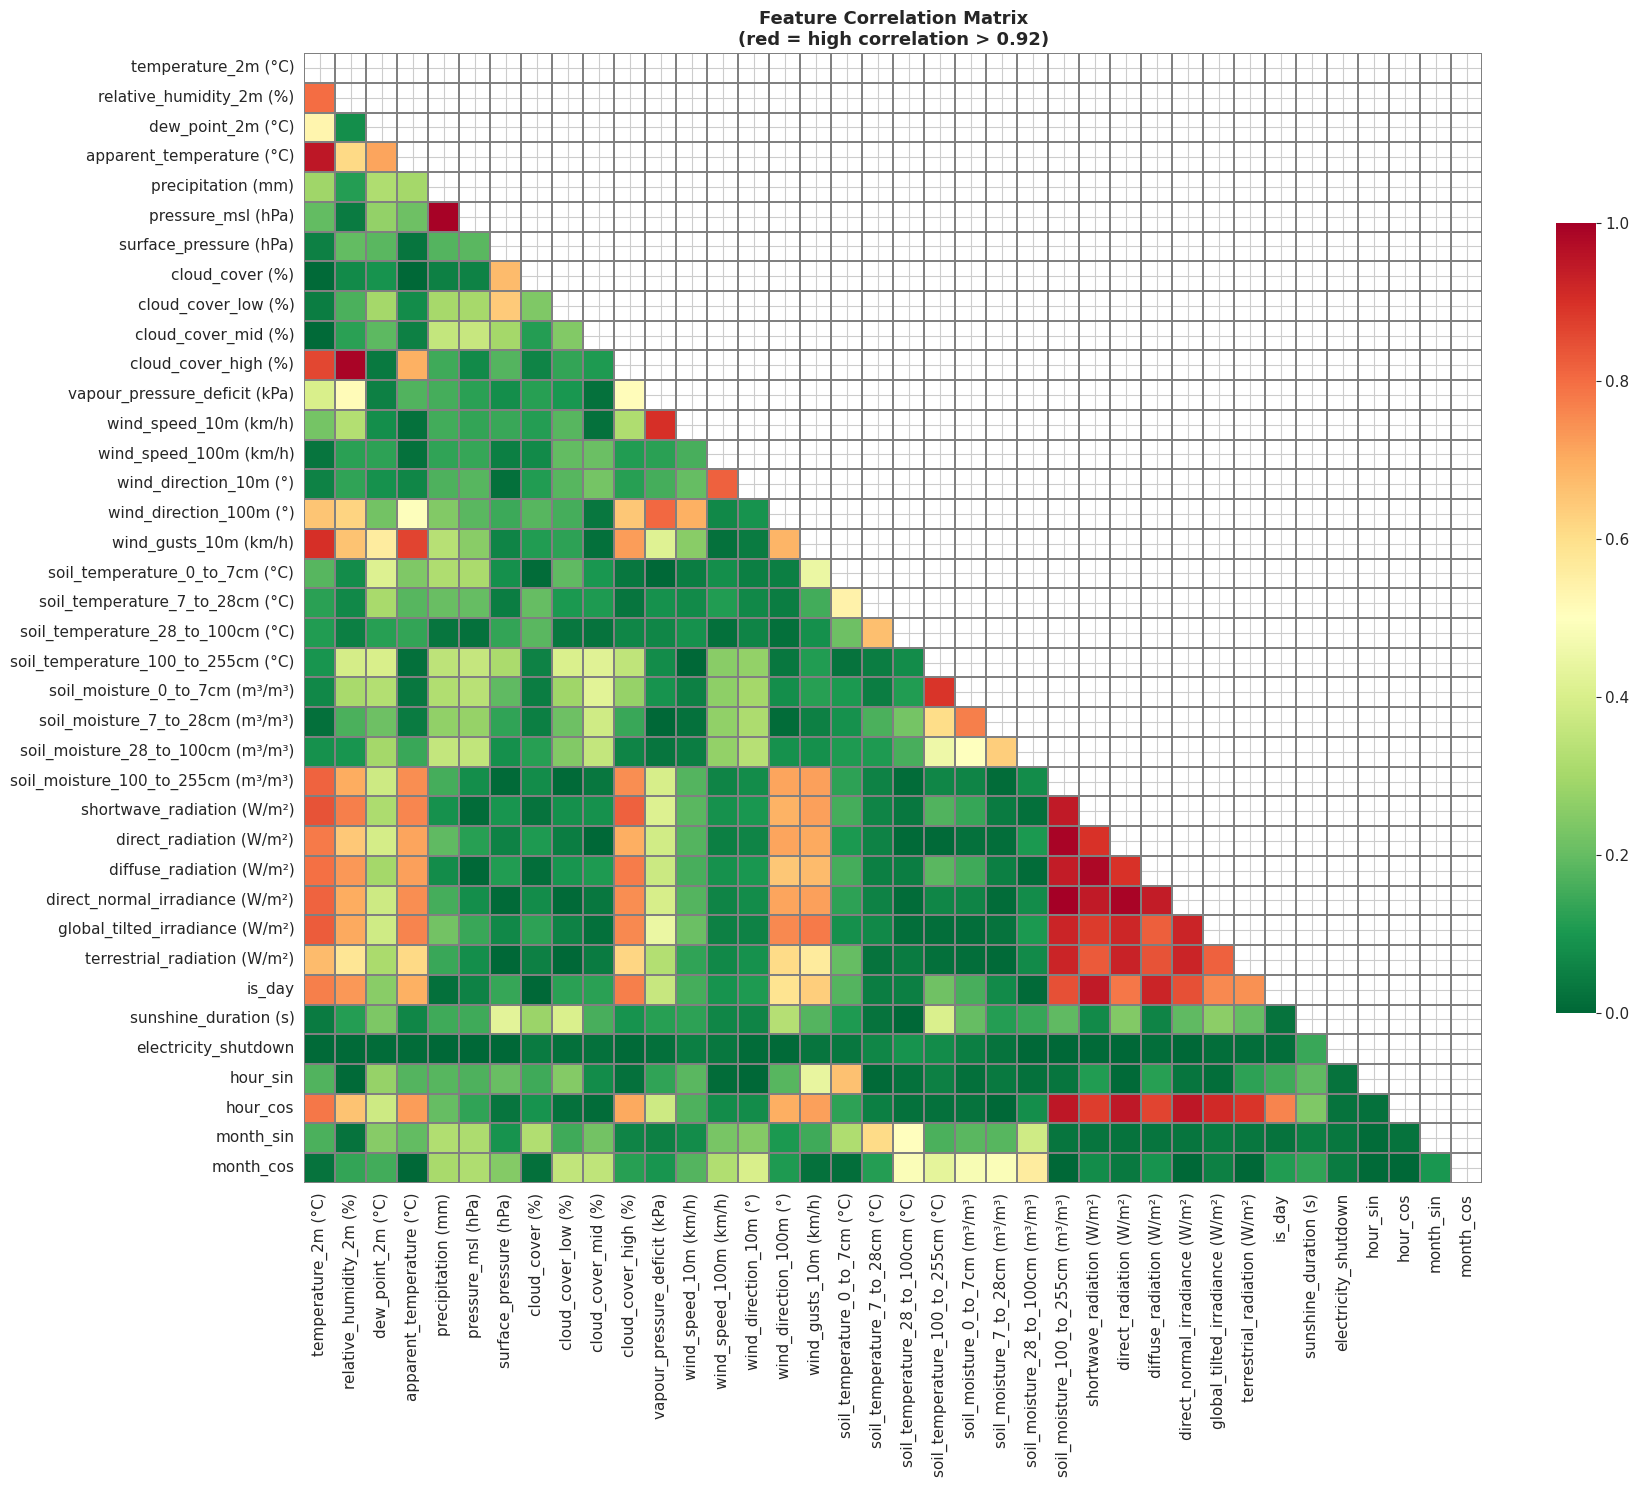

Correlation threshold : |r| > 0.92
Features to drop (8):
   - apparent_temperature (°C)
   - pressure_msl (hPa)
   - relative_humidity_2m (%)
   - soil_moisture_100_to_255cm (m³/m³)
   - shortwave_radiation (W/m²)
   - direct_radiation (W/m²)
   - diffuse_radiation (W/m²)
   - direct_normal_irradiance (W/m²)

✅ Remaining features after correlation filter: 30

Final feature list:
  [00] temperature_2m (°C)
  [01] dew_point_2m (°C)
  [02] precipitation (mm)
  [03] surface_pressure (hPa)
  [04] cloud_cover (%)
  [05] cloud_cover_low (%)
  [06] cloud_cover_mid (%)
  [07] cloud_cover_high (%)
  [08] vapour_pressure_deficit (kPa)
  [09] wind_speed_10m (km/h)
  [10] wind_speed_100m (km/h)
  [11] wind_direction_10m (°)
  [12] wind_direction_100m (°)
  [13] wind_gusts_10m (km/h)
  [14] soil_temperature_0_to_7cm (°C)
  [15] soil_temperature_7_to_28cm (°C)
  [16] soil_temperature_28_to_100cm (°C)
  [17] soil_temperature_100_to_255cm (°C)
  [18] soil_moisture_0_to_7cm (m³/m³)
  [19] soil_moisture_

In [ ]:
# ── Correlation-based Feature Selection ─────────────────────────────────────
CORR_THRESHOLD = 0.92   # Hapus fitur jika |correlation| dengan fitur lain > threshold

# Fitur yang wajib dipertahankan (tidak boleh di-drop oleh seleksi otomatis)
PROTECTED_FEATURES = [
    'electricity_shutdown',
    'precipitation (mm)',
    'temperature_2m (°C)',
    'wind_gusts_10m (km/h)',
    'cloud_cover (%)',
]

# Hitung correlation matrix (hanya fitur numerik, kecuali binary)
all_numeric = df.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df[all_numeric].corr().abs()

# Visualisasi correlation matrix
fig, ax = plt.subplots(figsize=(18, 15))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, ax=ax,
    cmap='RdYlGn_r', vmin=0, vmax=1,
    annot=False, linewidths=0.3, linecolor='gray',
    cbar_kws={'shrink': 0.7}
)
ax.set_title(f'Feature Correlation Matrix\n(red = high correlation > {CORR_THRESHOLD})',
             fontweight='bold')
plt.tight_layout()
plt.savefig('fig_correlation_matrix.png', dpi=120)
plt.show()

# ── Greedy removal: hapus fitur yang paling banyak berkorelasi tinggi ────────
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

cols_to_drop_corr = []
remaining = list(all_numeric)

for col in all_numeric:
    if col in cols_to_drop_corr:
        continue
    # Cari fitur lain yang berkorelasi tinggi dengan col
    if col in upper_tri.columns:
        high_corr_partners = upper_tri[col][upper_tri[col] > CORR_THRESHOLD].index.tolist()
        for partner in high_corr_partners:
            if partner in cols_to_drop_corr:
                continue
            if partner in PROTECTED_FEATURES:
                # Jika partner dilindungi, hapus 'col' saja jika col tidak dilindungi
                if col not in PROTECTED_FEATURES:
                    cols_to_drop_corr.append(col)
                    break
            else:
                # Hapus partner (yang datang belakangan dalam urutan kolom)
                cols_to_drop_corr.append(partner)

# Pastikan protected features tidak ikut ter-drop
cols_to_drop_corr = [c for c in cols_to_drop_corr if c not in PROTECTED_FEATURES]

print(f"Correlation threshold : |r| > {CORR_THRESHOLD}")
print(f"Features to drop ({len(cols_to_drop_corr)}):")
for c in cols_to_drop_corr:
    print(f"   - {c}")

df = df.drop(columns=cols_to_drop_corr)
print(f"\n✅ Remaining features after correlation filter: {df.shape[1]}")
print("\nFinal feature list:")
for i, col in enumerate(df.columns):
    print(f"  [{i:02d}] {col}")

Feature Selection — Hapus Fitur Redundan / Highly Correlated

> Fitur yang sangat berkorelasi satu sama lain tidak menambah informasi baru
> tetapi menambah noise dan dimensi.

Feature Scaling

In [ ]:
feature_names = df.columns.tolist()
scaler = RobustScaler()
X_scaled = scaler.fit_transform(df[feature_names])

print(f"Scaler           : RobustScaler (median + IQR)")
print(f"Input shape      : {df.shape}")
print(f"Output shape     : {X_scaled.shape}")
print(f"Median (should be ~0): {np.median(X_scaled):.4f}")

Scaler           : RobustScaler (median + IQR)
Input shape      : (741, 30)
Output shape     : (741, 30)
Median (should be ~0): 0.0000


Pada **Fitur Scaling**, fitur numerik diubah ke skala standar. `RobustScaler` digunakan.

PCA

In [ ]:
PCA_TUNING_GRID = {
    'n_components': [2, 3, 5, 8, 10, 15]
}

RANDOM_STATE = SEED

# Subsample agar cepat
PCA_TUNE_SAMPLE = min(5000, X_scaled.shape[0])

np.random.seed(RANDOM_STATE)
tune_idx = np.random.choice(
    X_scaled.shape[0],
    size=PCA_TUNE_SAMPLE,
    replace=False
)

X_tune = X_scaled[tune_idx]

PCA_TUNE_N_CLUSTERS = 5

print(f"{'n_comp':>7} {'silhouette':>11}")
print("-" * 22)

pca_results = []

for n_comp in PCA_TUNING_GRID['n_components']:

    pca_tune = PCA(
        n_components=n_comp,
        random_state=RANDOM_STATE
    )

    X_tune_reduced = pca_tune.fit_transform(X_tune)

    model_tune = AgglomerativeClustering(
        n_clusters=PCA_TUNE_N_CLUSTERS,
        linkage='average'
    )

    labels_tune = model_tune.fit_predict(X_tune_reduced)

    sil = silhouette_score(
        X_tune_reduced,
        labels_tune,
        sample_size=min(3000, len(labels_tune)),
        random_state=RANDOM_STATE
    )

    pca_results.append({
        'n_components': n_comp,
        'silhouette': sil
    })

    print(f"{n_comp:>7} {sil:>11.4f}")

# Best PCA
pca_results_df = pd.DataFrame(pca_results)

best_pca = pca_results_df.loc[
    pca_results_df['silhouette'].idxmax()
]

BEST_PCA_N_COMPONENTS = int(best_pca['n_components'])

print(f"\n✅ Best PCA config:")
print(f"   n_components = {BEST_PCA_N_COMPONENTS}")
print(f"   silhouette   = {best_pca['silhouette']:.4f}")

 n_comp  silhouette
----------------------
      2      0.6079
      3      0.4450
      5      0.3124
      8      0.2997
     10      0.2362
     15      0.2384

✅ Best PCA config:
   n_components = 2
   silhouette   = 0.6079


In [ ]:
print(f"Running PCA: {X_scaled.shape[1]}D → {BEST_PCA_N_COMPONENTS}D")

pca_full = PCA(
    n_components=BEST_PCA_N_COMPONENTS,
    random_state=RANDOM_STATE
)

X_reduced = pca_full.fit_transform(X_scaled)

print(f"Reduced shape: {X_reduced.shape}")

Running PCA: 30D → 2D
Reduced shape: (741, 2)


In [ ]:
print("Running PCA 2D projection for visualization...")

pca_2d = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_2d = pca_2d.fit_transform(X_scaled)

print(f"2D projection ready - Shape: {X_2d.shape}")

Running PCA 2D projection for visualization...
2D projection ready - Shape: (741, 2)


Bagian **Dimentional Reduction** bertujuan untuk mengurangi jumlah fitur sambil mempertahankan sebagian besar informasi penting. Ini dilakukan untuk mengatasi 'kutukan dimensionalitas' dan untuk membuat pengelompokan selanjutnya lebih efisien dan efektif. PCA dipilih karena ingin melihat fitur asli mana yang berkontribusi paling besar pada setiap komponen

Dendrogram Analisis

In [ ]:
DENDROGRAM_SAMPLE = 2000
np.random.seed(RANDOM_STATE)
sample_idx = np.random.choice(len(X_reduced), size=min(DENDROGRAM_SAMPLE, len(X_reduced)), replace=False)
X_dendro   = X_reduced[sample_idx]

print(f"Building linkage matrix on {len(sample_idx):,} sampled points...")
Z = linkage(X_dendro, method='ward', metric='euclidean')
print(f"Linkage matrix shape: {Z.shape}")

Building linkage matrix on 741 sampled points...
Linkage matrix shape: (740, 4)


Bagian **Analisis Dendrogram** menggunakan hasil pengelompokan hirarkis untuk membantu menentukan jumlah cluster optimal untuk Pengelompokan Aglomeratif. Karena Pengelompokan Aglomeratif memerlukan penentuan jumlah cluster (`n_clusters`) di awal, dendrogram secara visual merepresentasikan penggabungan cluster. Dengan mengamati celah vertikal terbesar dalam dendrogram dan menganalisis 'siku' dalam kurva jarak linkage, seseorang dapat menyimpulkan nilai `n_clusters` yang sesuai. Ini sangat berguna untuk dataset yang lebih kecil atau sampel, karena komputasi linkage untuk dataset yang sangat besar dapat memakan banyak komputasi.

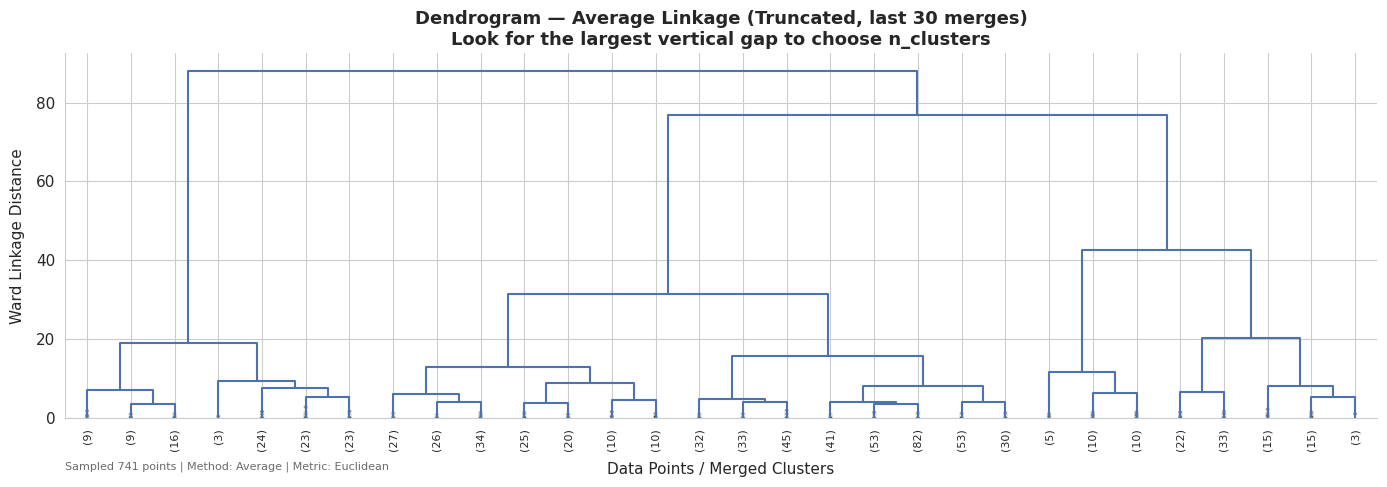

In [ ]:
# ── Plot dendrogram
fig, ax = plt.subplots(figsize=(14, 5))

dendrogram(
    Z,
    truncate_mode='lastp',   # hanya tampilkan p merge terakhir
    p=30,
    leaf_rotation=90,
    leaf_font_size=8,
    show_contracted=True,
    ax=ax,
    color_threshold=0,
    above_threshold_color='#4C72B0',
)

ax.set_title(
    'Dendrogram — Average Linkage (Truncated, last 30 merges)\n'
    'Look for the largest vertical gap to choose n_clusters',
    fontweight='bold'
)
ax.set_xlabel('Data Points / Merged Clusters', labelpad=8)
ax.set_ylabel('Ward Linkage Distance', labelpad=8)
clean_spines(ax)

add_figure_label(ax, f'Sampled {len(sample_idx):,} points | Method: Average | Metric: Euclidean')
plt.tight_layout()
plt.savefig('fig_dendrogram.png', dpi=150)
plt.show()

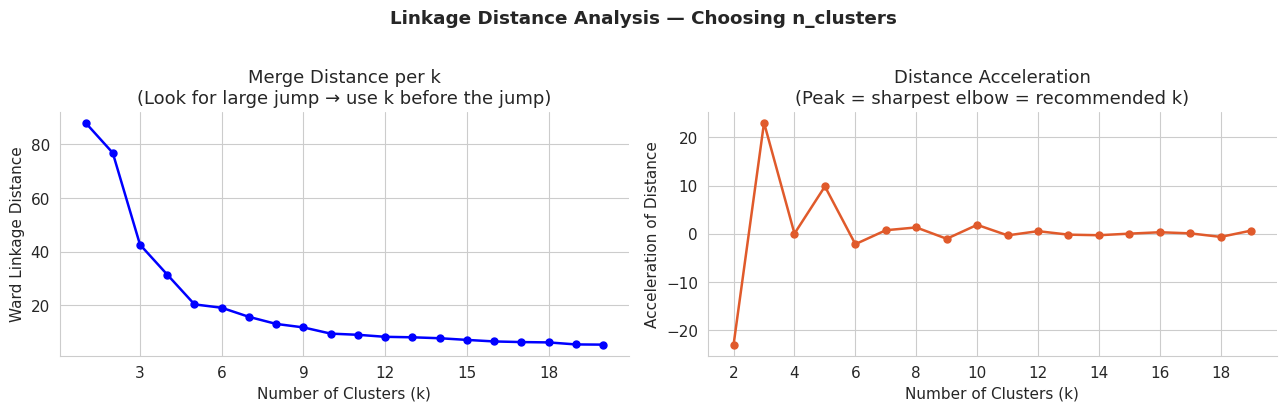


Recommended n_clusters from acceleration peak: 3


In [ ]:
# ── Plot linkage distance elbow ────────────────────────────────────────────
LAST_N = 20
last_distances = Z[-LAST_N:, 2][::-1]   # terbalik: dari banyak cluster → sedikit
k_values       = np.arange(1, LAST_N + 1)

# Acceleration (second derivative)
acceleration = np.diff(last_distances, 2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Linkage Distance Analysis — Choosing n_clusters', fontweight='bold', y=1.02)

# Left: distance curve
ax = axes[0]
ax.plot(k_values, last_distances, marker='o', color=PALETTE['normal_0'], linewidth=1.8, markersize=5)
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Ward Linkage Distance')
ax.set_title('Merge Distance per k\n(Look for large jump → use k before the jump)')
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
clean_spines(ax)
ax.set_axisbelow(True)

# Right: acceleration
ax = axes[1]
ax.plot(k_values[:-2] + 1, acceleration, marker='o', color=PALETTE['extreme'], linewidth=1.8, markersize=5)
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Acceleration of Distance')
ax.set_title('Distance Acceleration\n(Peak = sharpest elbow = recommended k)')
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
clean_spines(ax)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('fig_dendrogram_elbow.png', dpi=150)
plt.show()

recommended_k = int(k_values[:-2][np.argmax(acceleration)] + 1)
print(f"\nRecommended n_clusters from acceleration peak: {recommended_k}")

Hyperparameter Searhch

In [ ]:
# ── Gabungkan recommended_k dari dendrogram ke dalam grid ───────────────────
BASE_N_CLUSTERS = [2, 3, 4, 5]
# BASE_N_CLUSTERS = [2]

MAX_INTERPRETABLE_K = 5

recommended_k_clamped = min(recommended_k, MAX_INTERPRETABLE_K)
dendro_candidates = set([
    recommended_k_clamped - 1,
    recommended_k_clamped,
    recommended_k_clamped + 1
])

dendro_candidates = {
    k for k in dendro_candidates
    if 2 <= k <= MAX_INTERPRETABLE_K
}

all_n_clusters = sorted(set(BASE_N_CLUSTERS) | dendro_candidates)

param_grid = {
    'n_clusters': all_n_clusters,
    'linkage': ['ward', 'complete', 'single', 'average']
}

results = []

print(f"{'n_clusters':>12}  {'linkage':>10}  {'silhouette':>12}  {'from_dendro':>12}")
print("-" * 55)

for n_clust, link in product(param_grid['n_clusters'], param_grid['linkage']):
    metric      = 'euclidean'
    from_dendro = '★' if n_clust in dendro_candidates else ''

    model = AgglomerativeClustering(
        n_clusters=n_clust,
        linkage=link,
        metric=metric
    )
    labels = model.fit_predict(X_reduced)

    if n_clust >= 2:
        sil = silhouette_score(X_reduced, labels,
                               sample_size=min(5000, len(labels)),
                               random_state=RANDOM_STATE)
    else:
        sil = np.nan

    results.append({
        'n_clusters'  : n_clust,
        'linkage'     : link,
        'silhouette'  : sil,
        'from_dendro' : n_clust in dendro_candidates,
    })

    print(f"{n_clust:>12}  {link:>10}  {sil:>12.4f}  {from_dendro:>12}")

results_df = pd.DataFrame(results)

  n_clusters     linkage    silhouette   from_dendro
-------------------------------------------------------
           2        ward        0.5905             ★
           2    complete        0.5786             ★
           2      single        0.3358             ★
           2     average        0.6258             ★
           3        ward        0.6042             ★
           3    complete        0.5100             ★
           3      single        0.3337             ★
           3     average        0.5913             ★
           4        ward        0.5746             ★
           4    complete        0.5888             ★
           4      single        0.2946             ★
           4     average        0.6430             ★
           5        ward        0.4866              
           5    complete        0.5058              
           5      single        0.2621              
           5     average        0.6079              


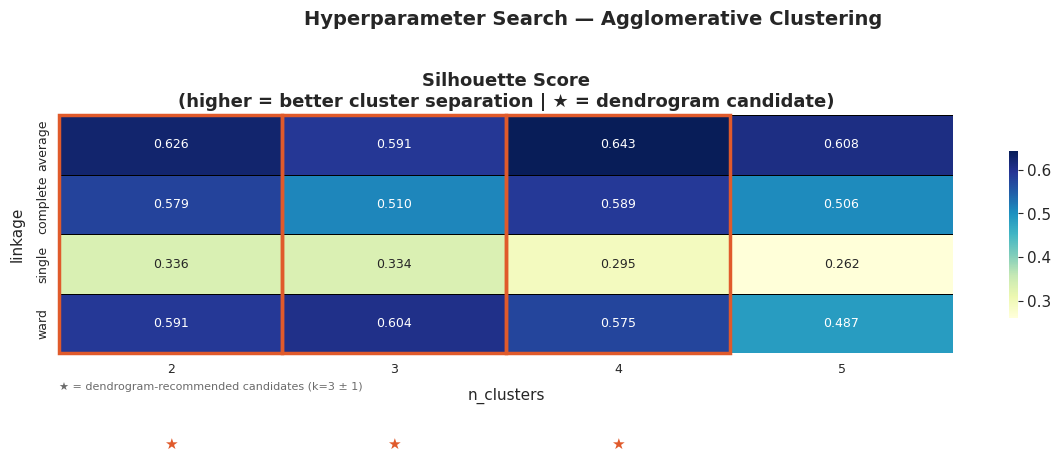

In [ ]:
# ── Visualize the hyperparameter search results ──────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle('Hyperparameter Search — Agglomerative Clustering', fontsize=14, fontweight='bold', y=1.02)

pivot = results_df.pivot(index='linkage', columns='n_clusters', values='silhouette')

cmap = sns.color_palette("YlGnBu", as_cmap=True)
sns.heatmap(
    pivot, ax=ax, annot=True, fmt='.3f', cmap=cmap,
    linewidths=0.5, linecolor="black",
    cbar_kws={'shrink': 0.7},
    annot_kws={'size': 9}
)
ax.set_title('Silhouette Score\n(higher = better cluster separation | ★ = dendrogram candidate)', fontweight='bold')
ax.set_xlabel('n_clusters', labelpad=8)
ax.set_ylabel('linkage', labelpad=8)
ax.tick_params(axis='both', labelsize=9)

# ── Highlight dendrogram-suggested columns with a border ─────────────────────
col_labels = list(pivot.columns)
for col_idx, col_val in enumerate(col_labels):
    if col_val in dendro_candidates:
        ax.add_patch(plt.Rectangle(
            (col_idx, 0), 1, len(pivot),
            fill=False, edgecolor=PALETTE['extreme'],
            lw=2.5, clip_on=False
        ))
        ax.text(
            col_idx + 0.5, -0.35, '★',
            ha='center', va='top', color=PALETTE['extreme'],
            fontsize=11, transform=ax.get_xaxis_transform()
        )

add_figure_label(ax, f'★ = dendrogram-recommended candidates (k={recommended_k} ± 1)')
plt.tight_layout()
plt.savefig('fig_hyperparam_search.png')
plt.show()

Bagian **Hyperparameter** secara sistematis mengevaluasi kombinasi hyperparameter yang berbeda untuk model Agglomerative Clustering. Ini mengulang `param_grid` dari `n_clusters` (jumlah cluster) dan metode `linkage` ('ward', 'complete', 'average'). Untuk setiap kombinasi, ia melatih model, memprediksi label cluster, dan menghitung Skor Silhouette. Skor Silhouette adalah metrik yang menunjukkan seberapa mirip suatu objek dengan clusternya sendiri dibandingkan dengan cluster lain, dengan skor yang lebih tinggi menunjukkan cluster yang lebih terdefinisi. Hasilnya kemudian divisualisasikan menggunakan heatmap untuk dengan mudah mengidentifikasi kombinasi dengan kinerja terbaik.

Final Model

In [ ]:
DENDRO_TOLERANCE = 0.01   # selisih silhouette yang dianggap 'sama baiknya'

# Kandidat terbaik global
best_global = results_df.loc[
    results_df['silhouette'].idxmax()
]

# Kandidat terbaik dari kelompok dendrogram
dendro_df = results_df[
    results_df['from_dendro'] == True
]

best_dendro = (
    dendro_df.loc[dendro_df['silhouette'].idxmax()]
    if len(dendro_df) > 0 else None
)

# Keputusan akhir
if best_dendro is not None:

    sil_gap = (
        best_global['silhouette']
        - best_dendro['silhouette']
    )

    if sil_gap <= DENDRO_TOLERANCE:

        best_row = best_dendro

        decision_src = (
            f'Dendrogram-guided '
            f'(gap={sil_gap:.4f} ≤ '
            f'tolerance={DENDRO_TOLERANCE})'
        )

    else:

        best_row = best_global

        decision_src = (
            f'Silhouette-only '
            f'(gap={sil_gap:.4f} > '
            f'tolerance={DENDRO_TOLERANCE})'
        )

else:

    best_row = best_global

    decision_src = (
        'Silhouette-only '
        '(no dendrogram candidates in grid)'
    )

BEST_N_CLUSTERS = int(best_row['n_clusters'])
BEST_LINKAGE    = str(best_row['linkage'])

print("FINAL MODEL CONFIGURATION")
print(f"\tAlgorithm        : Agglomerative Clustering")
print(f"\tn_clusters       : {BEST_N_CLUSTERS:<21}")
print(f"\tlinkage          : {BEST_LINKAGE:<21}")
print(f"\tmetric           : euclidean")
print(f"\tInput dimensions : {BEST_PCA_N_COMPONENTS} (PCA components)")
print()

print("DECISION AUDIT")
print(f"\tDendrogram recommended k : {recommended_k}")

print(
    f"\tBest global silhouette   : "
    f"{best_global['silhouette']:.4f} "
    f"(k={int(best_global['n_clusters'])}, "
    f"linkage={best_global['linkage']})"
)

if best_dendro is not None:

    print(
        f"\tBest dendro silhouette   : "
        f"{best_dendro['silhouette']:.4f} "
        f"(k={int(best_dendro['n_clusters'])}, "
        f"linkage={best_dendro['linkage']})"
    )

print(f"\tDecision source          : {decision_src}")

FINAL MODEL CONFIGURATION
	Algorithm        : Agglomerative Clustering
	n_clusters       : 4                    
	linkage          : average              
	metric           : euclidean
	Input dimensions : 2 (PCA components)

DECISION AUDIT
	Dendrogram recommended k : 3
	Best global silhouette   : 0.6430 (k=4, linkage=average)
	Best dendro silhouette   : 0.6430 (k=4, linkage=average)
	Decision source          : Dendrogram-guided (gap=0.0000 ≤ tolerance=0.01)


Model Training

In [ ]:
print(f"Training Agglomerative Clustering (n_clusters={BEST_N_CLUSTERS}, linkage='{BEST_LINKAGE}')...")

final_model = AgglomerativeClustering(
    n_clusters=BEST_N_CLUSTERS,
    linkage=BEST_LINKAGE,
    metric='euclidean',
    compute_distances=True    # Simpan jarak untuk analisis lanjutan
)
cluster_labels = final_model.fit_predict(X_reduced)

# ── Hitung outlier score berbasis jarak ke centroid ────────────────────────
# kita gunakan jarak Euclidean ke centroid cluster masing-masing titik.
centroids = np.array([
    X_reduced[cluster_labels == k].mean(axis=0)
    for k in range(BEST_N_CLUSTERS)
])
outlier_scores = np.array([
    np.linalg.norm(X_reduced[i] - centroids[cluster_labels[i]])
    for i in range(len(X_reduced))
])
# Normalisasi ke [0, 1]
outlier_scores = (outlier_scores - outlier_scores.min()) / (outlier_scores.max() - outlier_scores.min() + 1e-9)

# ── Summary ───────────────────────────────────────────────────────────────
unique_labels = sorted(set(cluster_labels))
n_clusters    = len(unique_labels)

print(f"\n{'─'*45}")
print(f"Unique labels      : {unique_labels}")
print(f"Number of clusters : {n_clusters}")
print(f"Total points       : {len(cluster_labels):,}")
print(f"{'─'*45}")

for lbl in unique_labels:
    cnt = (cluster_labels == lbl).sum()
    print(f"Cluster {lbl:>3} : {cnt:>6,} points")

Training Agglomerative Clustering (n_clusters=4, linkage='average')...

─────────────────────────────────────────────
Unique labels      : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Number of clusters : 4
Total points       : 741
─────────────────────────────────────────────
Cluster   0 :     52 points
Cluster   1 :    107 points
Cluster   2 :      5 points
Cluster   3 :    577 points


Model Evaluation

Bagian **Evaluasi Model** menilai kinerja dan kualitas cluster yang dihasilkan. Ini menghitung beberapa metrik kunci:

1.  **Skor Silhouette**: Mengukur seberapa baik titik data dikelompokkan, dengan nilai yang lebih tinggi menunjukkan pemisahan yang lebih baik antar cluster.
2.  **Skor Calinski-Harabasz**: Mengukur rasio varians antar-cluster terhadap varians dalam-cluster, di mana skor yang lebih tinggi menunjukkan cluster yang lebih padat dan terpisah dengan baik.
3.  **Skor Davies-Bouldin**: Mengukur rasio kemiripan rata-rata antara setiap cluster dan cluster yang paling mirip, di mana nilai yang lebih rendah menunjukkan pengelompokan yang lebih baik.

Ini juga memberikan ringkasan distribusi cluster (jumlah dan persentase titik di setiap cluster) dan memvisualisasikan distribusi ini menggunakan diagram batang, menawarkan pandangan yang jelas tentang ukuran cluster.

In [ ]:
# ── Silhouette Score ──────────────────────────────────────────────────────────
sil_score = silhouette_score(
    X_reduced,
    cluster_labels,
    sample_size=min(10000, len(cluster_labels)),
    random_state=RANDOM_STATE
)
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Interpretation  : ∈ [-1, 1]. Higher = better defined clusters.")

# ── Distribution summary ──────────────────────────────────────────────────────
print(f"\n{'─'*45}")
label_counts = pd.Series(cluster_labels).value_counts().sort_index()
print("Cluster distribution:")
for lbl, cnt in label_counts.items():
    pct = cnt / len(cluster_labels) * 100
    print(f"  Label {lbl:>3}: {cnt:>6,} points ({pct:5.1f}%)")

Silhouette Score: 0.6430
Interpretation  : ∈ [-1, 1]. Higher = better defined clusters.

─────────────────────────────────────────────
Cluster distribution:
  Label   0:     52 points (  7.0%)
  Label   1:    107 points ( 14.4%)
  Label   2:      5 points (  0.7%)
  Label   3:    577 points ( 77.9%)


In [ ]:
# ── Calinski-Harabasz & Davies-Bouldin ────────────────────────────────────────
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

ch_score = calinski_harabasz_score(X_reduced, cluster_labels)
db_score = davies_bouldin_score(X_reduced, cluster_labels)

print(f"Calinski-Harabasz Score : {ch_score:.2f}  (higher = better)")
print(f"Davies-Bouldin Score    : {db_score:.4f}  (lower = better)")

Calinski-Harabasz Score : 882.32  (higher = better)
Davies-Bouldin Score    : 0.4577  (lower = better)


Cluster Profile:
         precipitation (mm)  wind_gusts_10m (km/h)  cloud_cover (%)
cluster                                                            
0                   1009.74                  26.18             3.67
1                   1012.24                  25.13             3.08
2                   1010.80                  27.82             4.38
3                   1010.40                  25.23             2.55



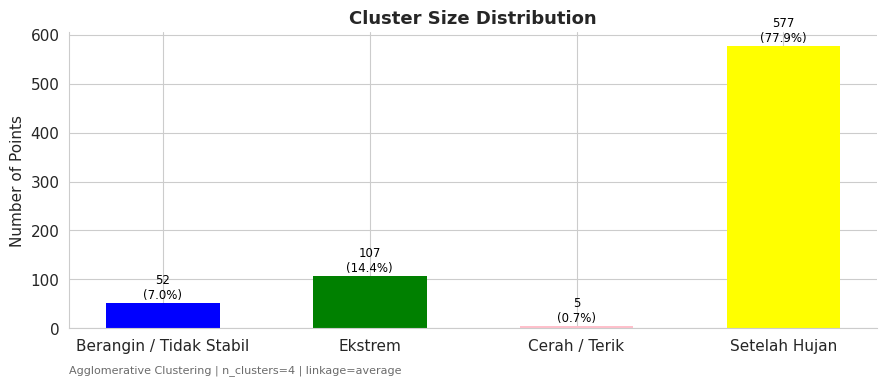

In [ ]:
# ── Evaluation Bar Chart + Semantic Interpretation ─────────────────────────

# ── Interpretasi cluster berdasarkan fitur cuaca
FEATURES = [
    'precipitation (mm)',
    'wind_gusts_10m (km/h)',
    'cloud_cover (%)'
]

FEATURES = [f for f in FEATURES if f in df.columns]

cluster_profile = (
    df.assign(cluster=cluster_labels)
      .groupby('cluster')[FEATURES]
      .mean()
      .round(2)
)

print("Cluster Profile:")
print(cluster_profile)
print()

# ── Tentukan label manual berdasarkan hasil profile
# ubah sesuai hasil print cluster_profile
cluster_label_map = {
    2: 'Cerah / Terik',          # radiation maks, sunshine tertinggi
    0: 'Berangin / Tidak Stabil', # wind tertinggi, outlier score tertinggi
    3: 'Setelah Hujan',           # radiation & sunshine rendah, soil basah
    1: 'Ekstrem',        # sunshine ~0, soil paling kering
}

semantic_labels = np.array([
    cluster_label_map[c]
    for c in cluster_labels
])

# ── Hitung jumlah data per cluster
label_counts_plot = label_counts.copy()

# ── Plot
fig, ax = plt.subplots(figsize=(9, 4))

bar_colors = [
    NORMAL_COLORS[i % len(NORMAL_COLORS)]
    for i, lbl in enumerate(label_counts_plot.index)
]

bars = ax.bar(
    [
        cluster_label_map.get(l, f'Cluster {l}')
        for l in label_counts_plot.index
    ],
    label_counts_plot.values,
    color=bar_colors,
    width=0.55,
    edgecolor='none'
)

# ── Value labels
for bar, val in zip(bars, label_counts_plot.values):

    pct = val / len(cluster_labels) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + len(cluster_labels) * 0.005,
        f'{val:,}\n({pct:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=8.5,
        color='black'
    )

ax.set_title(
    'Cluster Size Distribution',
    fontweight='bold'
)

ax.set_ylabel('Number of Points')

ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{int(x):,}')
)

clean_spines(ax)
ax.set_axisbelow(True)

add_figure_label(
    ax,
    f'Agglomerative Clustering | '
    f'n_clusters={BEST_N_CLUSTERS} | '
    f'linkage={BEST_LINKAGE}'
)

plt.tight_layout()
plt.savefig('fig_cluster_distribution.png')
plt.show()

Visualisasi

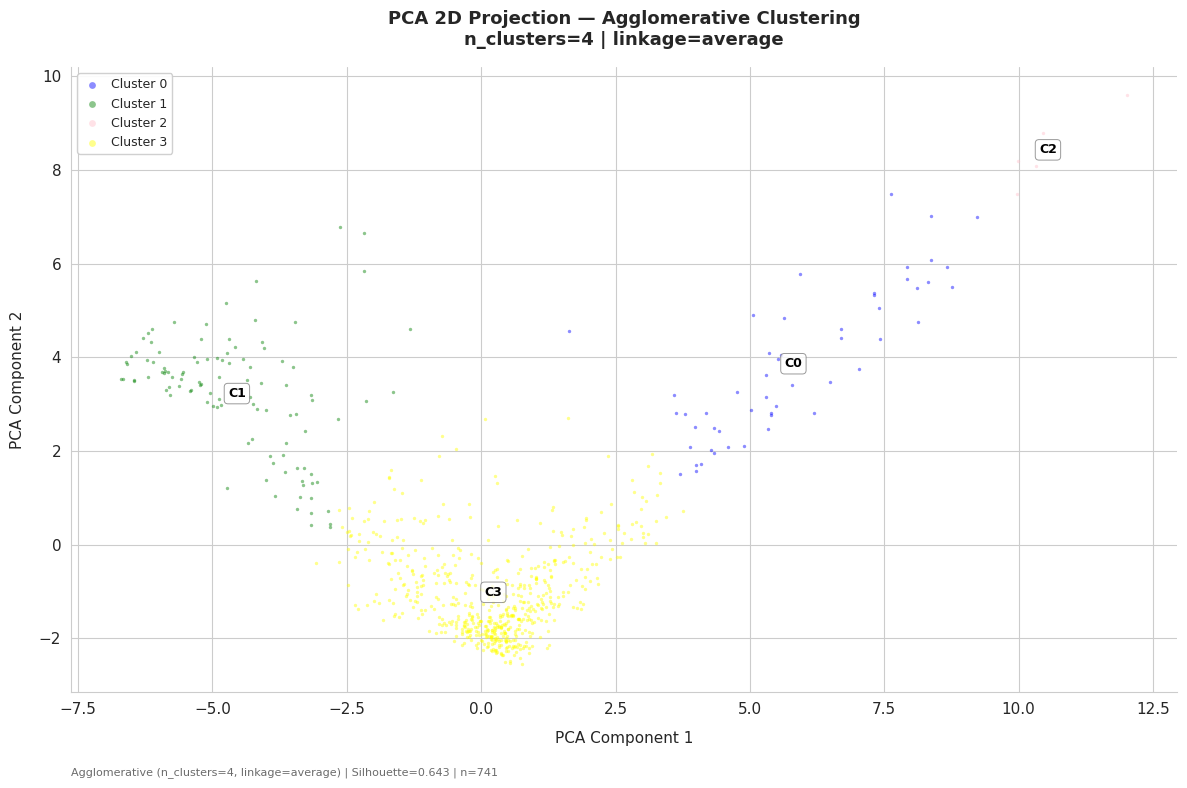

In [ ]:
# ── Build color array for scatter plot ───────────────────────────────────────
color_map = {
    lbl: NORMAL_COLORS[i % len(NORMAL_COLORS)]
    for i, lbl in enumerate(unique_labels)
}

point_colors = [color_map[l] for l in cluster_labels]

# ── Main scatter plot ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 8))

for lbl in unique_labels:

    mask = cluster_labels == lbl

    ax.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        c=color_map[lbl],
        s=6,
        alpha=0.45,
        linewidths=0,
        rasterized=True,
        label=f'Cluster {lbl}'
    )

# ── Annotations ──────────────────────────────────────────────────────────────
ax.set_title(
    f'PCA 2D Projection — Agglomerative Clustering\n'
    f'n_clusters={BEST_N_CLUSTERS} | linkage={BEST_LINKAGE}',
    fontweight='bold',
    pad=16
)

ax.set_xlabel('PCA Component 1', labelpad=10)
ax.set_ylabel('PCA Component 2', labelpad=10)

ax.legend(
    loc='upper left',
    frameon=True,
    framealpha=0.92,
    fontsize=9,
    markerscale=2.0,
    handlelength=1.5
)

# ── Annotate cluster centroids in 2D ─────────────────────────────────────────
for lbl in unique_labels:

    mask = cluster_labels == lbl

    cx = X_2d[mask, 0].mean()
    cy = X_2d[mask, 1].mean()

    ax.annotate(
        f'C{lbl}',
        xy=(cx, cy),
        fontsize=9,
        fontweight='bold',
        color='black',
        ha='center',
        va='center',
        bbox=dict(
            boxstyle='round,pad=0.3',
            edgecolor='gray',
            facecolor='white',
            linewidth=0.7,
            alpha=0.8
        )
    )

clean_spines(ax)

ax.set_axisbelow(True)

add_figure_label(
    ax,
    f'Agglomerative '
    f'(n_clusters={BEST_N_CLUSTERS}, '
    f'linkage={BEST_LINKAGE}) | '
    f'Silhouette={sil_score:.3f} | '
    f'n={len(cluster_labels):,}'
)

plt.tight_layout()

plt.savefig('fig_pca_clusters.png', dpi=180)

plt.show()

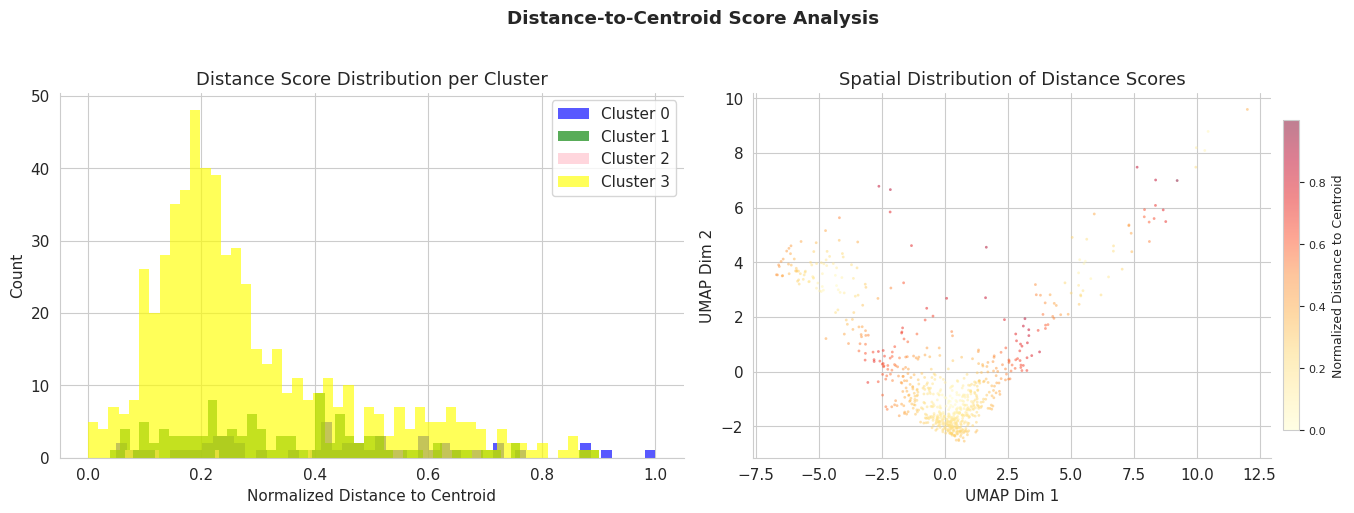

In [ ]:
# ── Supplementary: Distance-to-Centroid Score Distribution ───────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distance-to-Centroid Score Analysis', fontweight='bold', y=1.02)

# Left: Histogram of outlier scores per cluster
ax = axes[0]
for i, lbl in enumerate(unique_labels):
    scores = outlier_scores[cluster_labels == lbl]
    ax.hist(scores, bins=50, color=NORMAL_COLORS[i % len(NORMAL_COLORS)],
            alpha=0.65, label=f'Cluster {lbl}', edgecolor='none')
ax.set_xlabel('Normalized Distance to Centroid')
ax.set_ylabel('Count')
ax.set_title('Distance Score Distribution per Cluster')
ax.legend()
clean_spines(ax)

# Right: 2D scatter colored by distance score
ax = axes[1]
sc = ax.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=outlier_scores, cmap='YlOrRd',
    s=4, alpha=0.5, linewidths=0, rasterized=True
)
cbar = plt.colorbar(sc, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label('Normalized Distance to Centroid', fontsize=9)
cbar.ax.tick_params(labelsize=8)
ax.set_title('Spatial Distribution of Distance Scores')
ax.set_xlabel(f'UMAP Dim 1')
ax.set_ylabel(f'UMAP Dim 2')
clean_spines(ax)

plt.tight_layout()
plt.savefig('fig_outlier_scores.png')
plt.show()

Cluster Profilling

In [ ]:
# ── Attach cluster labels back to the original (unscaled) dataframe ──────────
df_clustered = df.copy()
df_clustered['cluster']       = cluster_labels
df_clustered['outlier_score'] = outlier_scores
df_clustered['cluster_label'] = df_clustered['cluster'].apply(
    lambda x: f'Cluster {x}'
)

# ── Mean feature values per cluster ──────────────────────────────────────────
KEY_FEATURES = [
    'temperature_2m (°C)',
    'relative_humidity_2m (%)',
    'dew_point_2m (°C)',
    'apparent_temperature (°C)',
    'pressure_msl (hPa)',
    'cloud_cover (%)',
    'vapour_pressure_deficit (kPa)',
    'wind_speed_10m (km/h)',
    'wind_speed_100m (km/h)',
    'wind_gusts_10m (km/h)',
    'shortwave_radiation (W/m²)',
    'terrestrial_radiation (W/m²)',
    'soil_moisture_0_to_7cm (m³/m³)',
    'sunshine_duration (s)',
    'outlier_score',
]
key_features_present = [f for f in KEY_FEATURES if f in df_clustered.columns]

profile = (df_clustered
           .groupby('cluster')[key_features_present]
           .agg(['mean', 'std'])
           .round(3))

print("Cluster Profile - Mean ± Std of Key Features:")
print(profile.to_string())

Cluster Profile - Mean ± Std of Key Features:
        temperature_2m (°C)        dew_point_2m (°C)        cloud_cover (%)        vapour_pressure_deficit (kPa)        wind_speed_10m (km/h)        wind_speed_100m (km/h)         wind_gusts_10m (km/h)        terrestrial_radiation (W/m²)        soil_moisture_0_to_7cm (m³/m³)        sunshine_duration (s)        outlier_score       
                       mean    std              mean    std            mean    std                          mean    std                  mean    std                   mean     std                  mean    std                         mean    std                           mean    std                  mean    std          mean    std
cluster                                                                                                                                                                                                                                                                                         

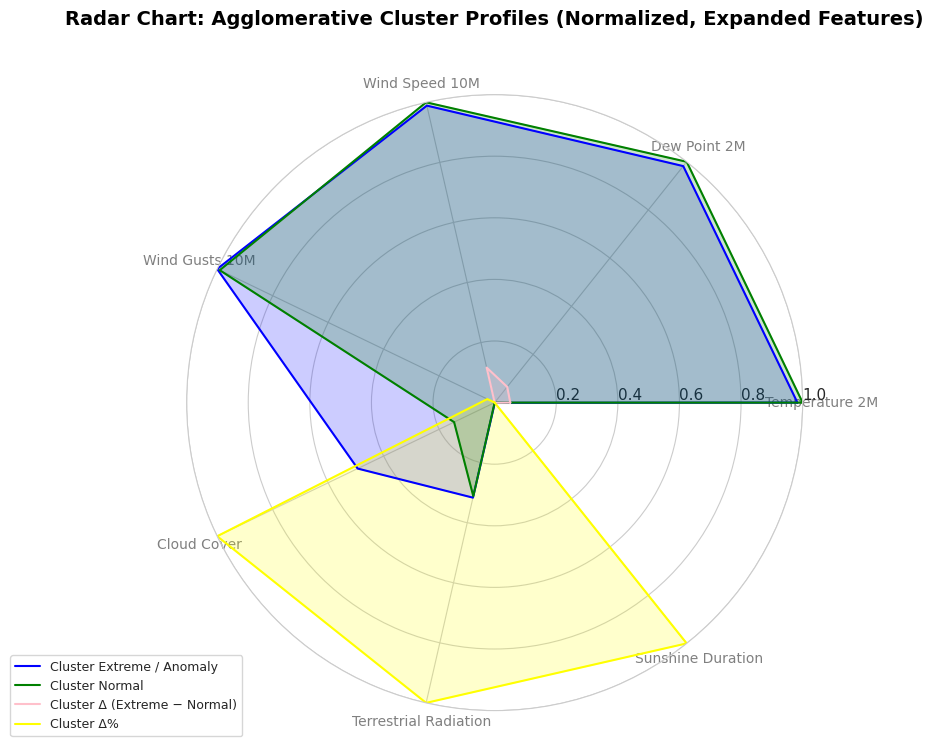

In [ ]:
from math import pi

def create_radar_chart(df, features, title, save_path=None):
    """Generates a radar chart for cluster profiling."""
    # Number of variables
    categories = [f.split('(')[0].strip().replace('_', ' ').title() for f in features]
    N = len(categories)

    # What angle each axis will be at
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # Draw one axe per variable + add labels
    plt.xticks(angles[:-1], categories, color='grey', size=10)
    ax.set_rlabel_position(0)

    # Plot each cluster
    for i, (cluster_id, row) in enumerate(df.iterrows()):
        values = row.values.flatten().tolist()
        values += values[:1]
        color = NORMAL_COLORS[i % len(NORMAL_COLORS)]
        ax.plot(angles, values, linewidth=1.5, linestyle='solid', label=f'Cluster {cluster_id}', color=color)
        ax.fill(angles, values, color=color, alpha=0.2)

    # Set title and legend
    plt.title(title, size=14, color='black', y=1.1, fontweight='bold')
    plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1), fontsize=9)
    ax.grid(True)
    ax.set_ylim(0, 1) # Ensure consistent scale for normalized data

    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

# Select features for the radar chart
# Using a broader subset of available features for clarity and relevance on a radar chart
RADAR_FEATURES_AGG = [
    'temperature_2m (°C)',
    'dew_point_2m (°C)', # Related to humidity
    'wind_speed_10m (km/h)',
    'wind_gusts_10m (km/h)',
    'cloud_cover (%)',
    'terrestrial_radiation (W/m²)', # Radiation
    'sunshine_duration (s)', # Sunshine/Radiation
    'soil_moisture_0_to_7cm (m³/m³)' # Soil wetness
]

# Filter to only features present in the mean_compare table (after correlation filtering)
filtered_radar_features = [f for f in RADAR_FEATURES_AGG if f in mean_compare.index]

# Prepare data for radar chart: normalize mean values to a 0-1 scale
# Transpose mean_compare to have features as columns and clusters as rows
radar_data = mean_compare.loc[filtered_radar_features].T

# Normalize each feature independently across clusters (min-max scaling)
# Add a small epsilon to avoid division by zero if all values are the same
normalized_radar_data = (radar_data - radar_data.min()) / (radar_data.max() - radar_data.min() + 1e-9)

# Create the radar chart
create_radar_chart(
    normalized_radar_data,
    filtered_radar_features,
    'Radar Chart: Agglomerative Cluster Profiles (Normalized, Expanded Features)',
    'fig_radar_chart_agg_expanded.png'
)


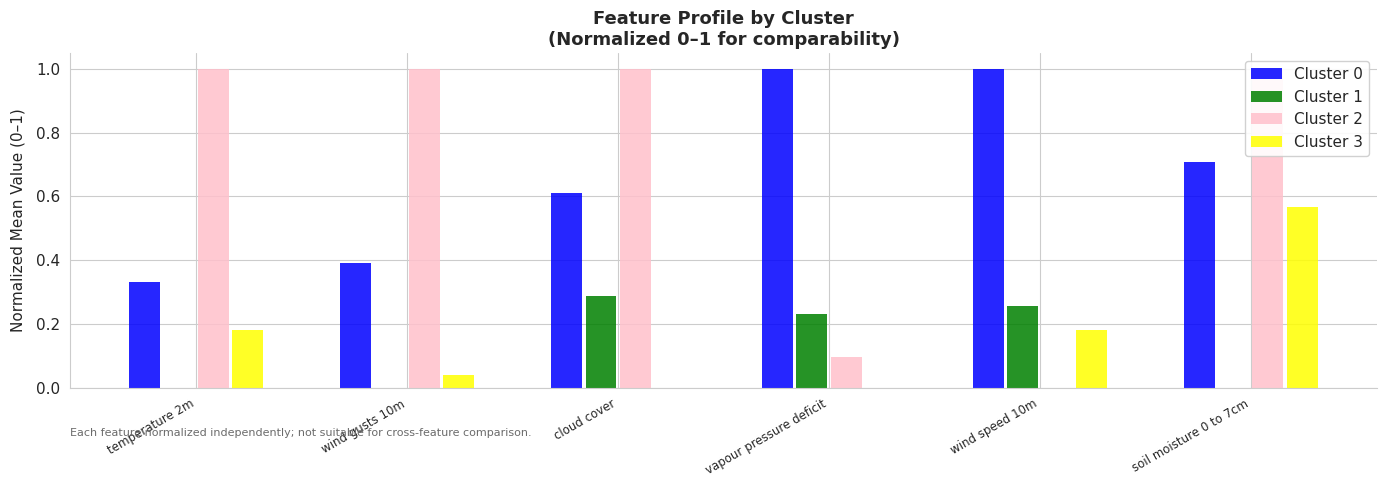

In [ ]:
# ── Radar / Bar Chart for key feature comparison ─────────────────────────────
RADAR_FEATURES = [
    f for f in [
        'temperature_2m (°C)', 'relative_humidity_2m (%)',
        'wind_gusts_10m (km/h)', 'cloud_cover (%)',
        'vapour_pressure_deficit (kPa)', 'shortwave_radiation (W/m²)',
        'wind_speed_10m (km/h)', 'soil_moisture_0_to_7cm (m³/m³)'
    ] if f in df_clustered.columns
]

means = df_clustered.groupby('cluster')[RADAR_FEATURES].mean()
# Normalize
means_norm = (means - means.min()) / (means.max() - means.min() + 1e-9)

# ── Grouped bar chart ─────────────────────────────────────────────────────────
n_feats   = len(RADAR_FEATURES)
n_labels  = len(means.index)
x_pos     = np.arange(n_feats)
bar_width = 0.65 / n_labels

fig, ax = plt.subplots(figsize=(14, 5))

for i, (lbl, row) in enumerate(means_norm.iterrows()):
    color = NORMAL_COLORS[i % len(NORMAL_COLORS)]
    ax.bar(
        x_pos + i * bar_width - (n_labels - 1) * bar_width / 2,
        row.values, width=bar_width * 0.9,
        color=color, alpha=0.85, label=f'Cluster {lbl}', edgecolor='none'
    )

ax.set_xticks(x_pos)
ax.set_xticklabels(
    [f.split('(')[0].strip().replace('_', ' ') for f in RADAR_FEATURES],
    rotation=30, ha='right', fontsize=8.5
)
ax.set_ylabel('Normalized Mean Value (0–1)', labelpad=8)
ax.set_title('Feature Profile by Cluster\n(Normalized 0–1 for comparability)', fontweight='bold')
ax.legend(loc='upper right', frameon=True, framealpha=0.9, facecolor='white')
clean_spines(ax)
ax.set_axisbelow(True)

add_figure_label(ax, 'Each feature normalized independently; not suitable for cross-feature comparison.')
plt.tight_layout()
plt.savefig('fig_cluster_profile_bars.png')
plt.show()

Outer Analisis

Bagian **Analisis Outlier** mengidentifikasi dan memeriksa titik data yang secara signifikan berbeda dari cluster yang ditugaskan. Karena Agglomerative Clustering tidak secara inheren menyediakan skor outlier, jarak Euclidean yang dinormalisasi ke centroid cluster setiap titik digunakan sebagai proksi. `OUTLIER_THRESHOLD` didefinisikan, dan titik yang melebihi ambang batas ini ditandai sebagai anomali potensial. Bagian ini menampilkan titik-titik jarak tinggi teratas dan menggunakan box plot untuk memvisualisasikan distribusi skor jarak ini di seluruh cluster, membantu mengidentifikasi cluster dengan variabilitas internal yang lebih besar atau outlier yang signifikan.

Points with distance score > 0.85: 9 (1.2%)

Top 20 High-Distance Points (possible anomalies):
 wind_gusts_10m (km/h)  temperature_2m (°C)  cloud_cover (%)  vapour_pressure_deficit (kPa)  outlier_score  cluster
                  26.0                 24.3         4.615121                            9.4       1.000000        0
                  26.7                 25.4         4.615121                            8.9       0.911558        0
                  26.6                 26.6         2.772589                            8.7       0.900179        3
                  24.2                 23.5         4.615121                           11.6       0.900082        1
                  26.8                 24.7         4.488636                            6.6       0.874271        0
                  29.5                 26.0         3.737670                           11.1       0.872847        0
                  29.0                 27.1         4.615121                           10.2  

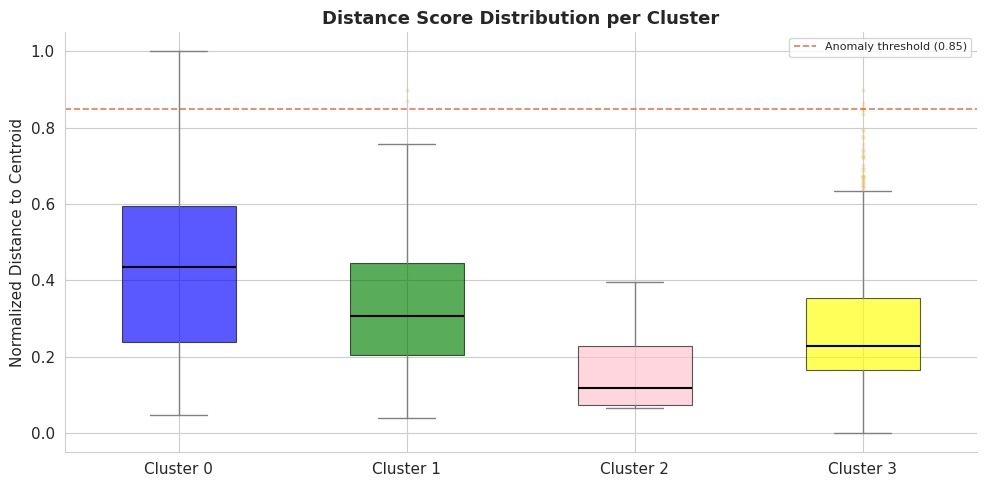

In [ ]:
# ── Top high-distance points per cluster ──────────────────────────────────────
OUTLIER_THRESHOLD = 0.85   # titik dengan distance score > threshold dianggap ekstrem

extreme_mask = outlier_scores > OUTLIER_THRESHOLD
df_extreme   = df_clustered[extreme_mask].copy()

display_cols = [c for c in [
    'wind_gusts_10m (km/h)', 'temperature_2m (°C)',
    'relative_humidity_2m (%)', 'cloud_cover (%)',
    'vapour_pressure_deficit (kPa)', 'shortwave_radiation (W/m²)',
    'outlier_score', 'cluster'
] if c in df_clustered.columns]

top_extreme = df_extreme.sort_values('outlier_score', ascending=False).head(20)
print(f"Points with distance score > {OUTLIER_THRESHOLD}: {extreme_mask.sum():,} ({extreme_mask.mean()*100:.1f}%)")
print(f"\nTop 20 High-Distance Points (possible anomalies):")
print(top_extreme[display_cols].to_string(index=False))

# ── Box plots: distance score per cluster ────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

cluster_order = sorted(df_clustered['cluster'].unique())
data_by_cluster = [df_clustered[df_clustered['cluster'] == c]['outlier_score'].values
                   for c in cluster_order]
box_colors = [NORMAL_COLORS[i % len(NORMAL_COLORS)] for i, c in enumerate(cluster_order)]

bp = ax.boxplot(
    data_by_cluster,
    patch_artist=True,
    medianprops=dict(color='black', linewidth=1.5),
    whiskerprops=dict(color='gray', linewidth=1),
    capprops=dict(color='gray', linewidth=1),
    flierprops=dict(marker='o', markersize=3, alpha=0.3,
                    markerfacecolor=PALETTE['extreme_alt'],
                    markeredgecolor='none'),
    widths=0.5
)

for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)
    patch.set_linewidth(0.8)

ax.set_xticklabels([f'Cluster {c}' for c in cluster_order])
ax.set_ylabel('Normalized Distance to Centroid')
ax.set_title('Distance Score Distribution per Cluster', fontweight='bold')
clean_spines(ax)
ax.set_axisbelow(True)

# Threshold line
ax.axhline(OUTLIER_THRESHOLD, color=PALETTE['extreme'], linestyle='--',
           linewidth=1.2, alpha=0.8, label=f'Anomaly threshold ({OUTLIER_THRESHOLD})')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('fig_outlier_boxplot.png')
plt.show()

Physical Interpretation

Bagian **Physical Interpretation** bertujuan untuk mendeskripsikan karakteristik setiap cluster berdasarkan nilai fiturnya. Ini melakukan dua tugas utama:

1.  **Perbandingan Rata-rata**: Menghitung dan menampilkan nilai rata-rata fitur-fitur kunci yang dipilih untuk setiap cluster. Tabel ini membantu dalam memahami bagaimana cluster berbeda satu sama lain dalam hal kondisi lingkungan atau properti tipikalnya.
2.  **Visualisasi Ringkasan**: Menggunakan plot violin untuk memvisualisasikan distribusi fitur spesifik di seluruh cluster yang berbeda. Ini memberikan pandangan yang lebih detail daripada hanya rata-rata, menunjukkan kepadatan dan penyebaran nilai fitur dalam setiap cluster dan memfasilitasi perbandingan berdampingan.

In [ ]:
# ── Mean comparison across all clusters ──────────────────────────────────────
COMPARE_FEATURES = [
    f for f in [
        'temperature_2m (°C)',
        'apparent_temperature (°C)',
        'relative_humidity_2m (%)',
        'dew_point_2m (°C)',
        'pressure_msl (hPa)',
        'cloud_cover (%)',
        'vapour_pressure_deficit (kPa)',
        'wind_speed_10m (km/h)',
        'wind_gusts_10m (km/h)',
        'shortwave_radiation (W/m²)',
        'terrestrial_radiation (W/m²)',
        'sunshine_duration (s)',
        'soil_moisture_0_to_7cm (m³/m³)',
        'outlier_score',
    ] if f in df_clustered.columns
]

mean_compare = df_clustered.groupby('cluster')[COMPARE_FEATURES].mean().round(3).T
mean_compare.columns = [f'Cluster {c}' for c in mean_compare.columns]
mean_compare.columns.name = None

print(mean_compare.to_string())

                                Cluster 0  Cluster 1  Cluster 2  Cluster 3
temperature_2m (°C)                24.781     24.554     25.240     24.678
dew_point_2m (°C)                  22.563     21.205     22.980     21.958
cloud_cover (%)                     3.672      3.080      4.380      2.555
vapour_pressure_deficit (kPa)       7.621      6.278      6.040      5.875
wind_speed_10m (km/h)              11.188      8.877      8.080      8.644
wind_gusts_10m (km/h)              26.185     25.128     27.820     25.232
terrestrial_radiation (W/m²)        0.769      0.533      1.000      0.473
sunshine_duration (s)               1.410      0.057      2.629      0.098
soil_moisture_0_to_7cm (m³/m³)      0.288      0.205      0.323      0.272
outlier_score                       0.438      0.334      0.176      0.281


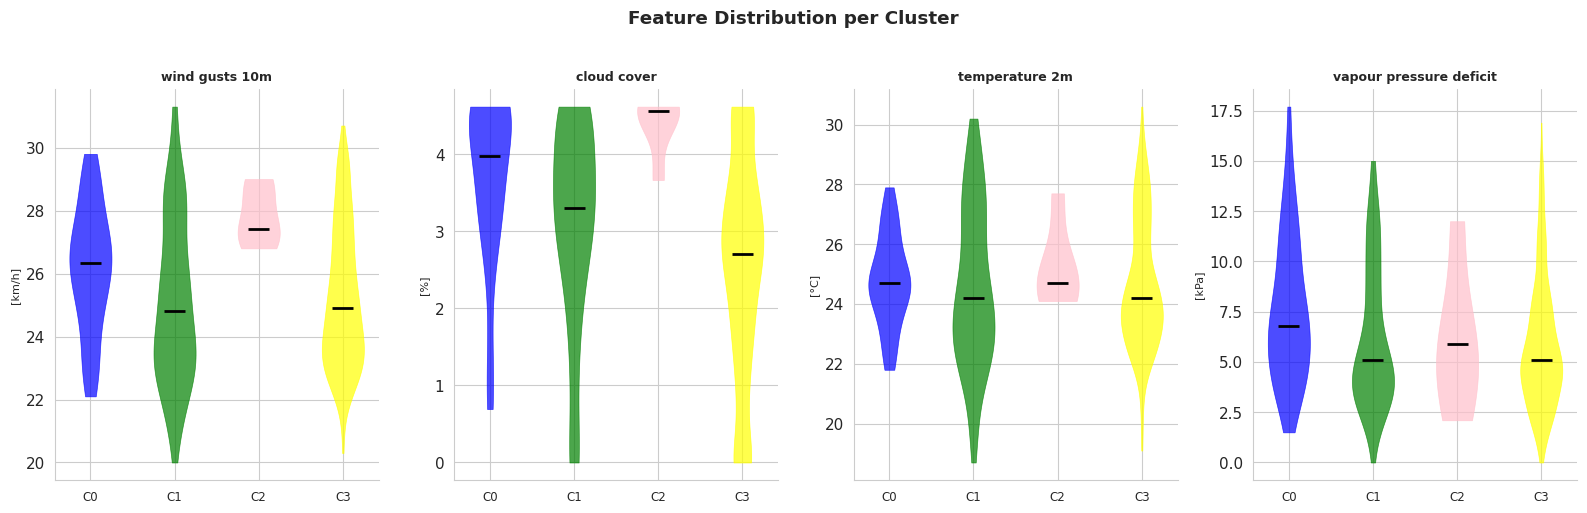

In [ ]:
# ── Summary visualization: Side-by-side violin plots ─────────────────────────
VIOLIN_FEATURES = [
    f for f in [
        'wind_gusts_10m (km/h)',
        'cloud_cover (%)',
        'temperature_2m (°C)',
        'vapour_pressure_deficit (kPa)',
    ] if f in df_clustered.columns
]

if len(VIOLIN_FEATURES) > 0:
    fig, axes = plt.subplots(1, len(VIOLIN_FEATURES),
                              figsize=(4 * len(VIOLIN_FEATURES), 5))
    if len(VIOLIN_FEATURES) == 1:
        axes = [axes]

    fig.suptitle('Feature Distribution per Cluster',
                 fontweight='bold', y=1.02)

    for ax, feat in zip(axes, VIOLIN_FEATURES):
        data_by_cluster = [
            df_clustered[df_clustered['cluster'] == lbl][feat].dropna().values
            for lbl in unique_labels
        ]
        positions = list(range(1, len(unique_labels) + 1))

        parts = ax.violinplot(
            data_by_cluster,
            positions=positions,
            showmedians=True, showextrema=False
        )

        for pc, color in zip(parts['bodies'], NORMAL_COLORS[:len(unique_labels)]):
            pc.set_facecolor(color)
            pc.set_alpha(0.70)
            pc.set_edgecolor(color)
            pc.set_linewidth(0.5)

        parts['cmedians'].set_color('black')
        parts['cmedians'].set_linewidth(2)

        short_name = feat.split('(')[0].strip().replace('_', ' ')
        unit = feat[feat.find('(')+1:feat.find(')')] if '(' in feat else ''

        ax.set_title(short_name, fontsize=9, fontweight='bold')
        ax.set_ylabel(f'[{unit}]' if unit else '', fontsize=8)
        ax.set_xticks(positions)
        ax.set_xticklabels([f'C{l}' for l in unique_labels], fontsize=8.5)
        clean_spines(ax)
        ax.set_axisbelow(True)

    plt.tight_layout()
    plt.savefig('fig_violin_comparison.png')
    plt.show()

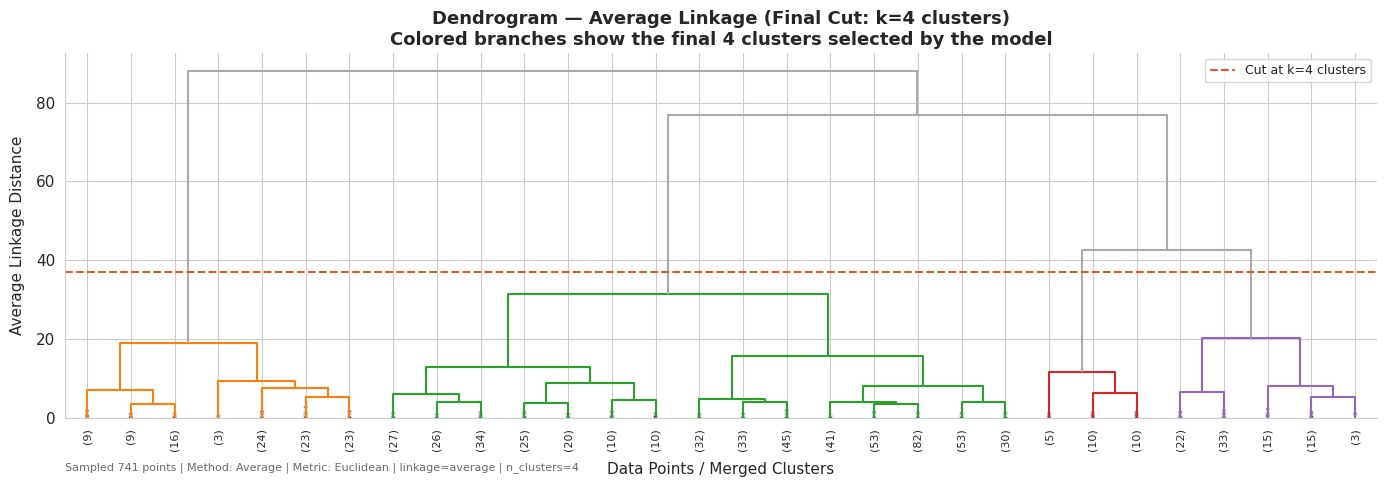

In [ ]:
cut_distance = 0.5 * (Z[-(BEST_N_CLUSTERS - 1), 2] + Z[-BEST_N_CLUSTERS, 2])

fig, ax = plt.subplots(figsize=(14, 5))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=8,
    show_contracted=True,
    ax=ax,
    color_threshold=cut_distance,
    above_threshold_color='#aaaaaa',
)

ax.axhline(y=cut_distance, color=PALETTE['extreme'], linestyle='--',
           linewidth=1.5, label=f'Cut at k={BEST_N_CLUSTERS} clusters')
ax.legend(fontsize=9, loc='upper right')

ax.set_title(
    f'Dendrogram — Average Linkage (Final Cut: k={BEST_N_CLUSTERS} clusters)\n'
    f'Colored branches show the final {BEST_N_CLUSTERS} clusters selected by the model',
    fontweight='bold'
)
ax.set_xlabel('Data Points / Merged Clusters', labelpad=8)
ax.set_ylabel('Average Linkage Distance', labelpad=8)
clean_spines(ax)
add_figure_label(
    ax,
    f'Sampled {len(sample_idx):,} points | Method: Average | Metric: Euclidean | '
    f'linkage={BEST_LINKAGE} | n_clusters={BEST_N_CLUSTERS}'
)
plt.tight_layout()
plt.savefig('fig_dendrogram_final.png', dpi=150)
plt.show()

Export

In [ ]:
# ── Save labeled dataset ──────────────────────────────────────────────────────
output_path = 'clustered_weather_results_agglomerative.csv'
df_clustered.to_csv(output_path, index=False)

# ── Save clean summary table ──────────────────────────────────────────────────
summary_path = 'cluster_summary_agglomerative.csv'
mean_compare.to_csv(summary_path)

print(f"  Labeled dataset saved  → {output_path}")
print(f"  Cluster summary saved  → {summary_path}")

  Labeled dataset saved  → clustered_weather_results_agglomerative.csv
  Cluster summary saved  → cluster_summary_agglomerative.csv


---
## K - Means Clustering


feature selection

In [ ]:
# Definisi fitur yang dipilih — satu representatif per grup
CLUSTERING_FEATURES = [

    'temperature_2m',
    'relative_humidity_2m',
    'dew_point_2m',
    'apparent_temperature',

    'pressure_msl',

    'cloud_cover',

    'vapour_pressure_deficit',

    'wind_speed_10m',
    'wind_speed_100m',
    'wind_gusts_10m',

    'shortwave_radiation',
    'sunshine_duration',

    'soil_moisture_0_to_7cm',
    'soil_moisture_100_to_255cm',

    'soil_temperature_0_to_7cm',

    'precipitation',
]

print(
    f"Total fitur terpilih untuk clustering: "
    f"{len(CLUSTERING_FEATURES)} fitur"
)

# Note:
# wind_speed_100m ditambahkan berdasarkan EDA 4.7 —
# meskipun r=0.903 dengan wind_speed_10m,
# wind shear antar ketinggian memberi sinyal meteorologi
# tambahan untuk cluster ekstrem

print("\nKelompok fitur:")

groups = {

    "   Suhu & Kelembaban": [
        'temperature_2m',
        'relative_humidity_2m',
        'dew_point_2m',
        'apparent_temperature'
    ],

    "    Atmosfer & Tekanan": [
        'pressure_msl',
        'vapour_pressure_deficit'
    ],

    "    Tutupan Awan": [
        'cloud_cover'
    ],

    "    Angin": [
        'wind_speed_10m',
        'wind_speed_100m',
        'wind_gusts_10m'
    ],

    "    Radiasi": [
        'shortwave_radiation',
        'sunshine_duration'
    ],

    "    Tanah": [
        'soil_moisture_0_to_7cm',
        'soil_moisture_100_to_255cm',
        'soil_temperature_0_to_7cm'
    ],

    "    Presipitasi": [
        'precipitation'
    ],
}

for g, cols in groups.items():
    print(f"  {g}: {', '.join(cols)}")

Total fitur terpilih untuk clustering: 16 fitur

Kelompok fitur:
     Suhu & Kelembaban: temperature_2m, relative_humidity_2m, dew_point_2m, apparent_temperature
      Atmosfer & Tekanan: pressure_msl, vapour_pressure_deficit
      Tutupan Awan: cloud_cover
      Angin: wind_speed_10m, wind_speed_100m, wind_gusts_10m
      Radiasi: shortwave_radiation, sunshine_duration
      Tanah: soil_moisture_0_to_7cm, soil_moisture_100_to_255cm, soil_temperature_0_to_7cm
      Presipitasi: precipitation


Buat dataframe fitur clustering dan Imputasi mean

In [ ]:

clustering_df = train_df[CLUSTERING_FEATURES].copy()
clustering_df_original = clustering_df.copy()

print(f"Shape dataframe clustering: {clustering_df.shape}")
print(f"\nMissing values sebelum imputasi:")
print(clustering_df.isnull().sum()[clustering_df.isnull().sum() > 0])


imputer = SimpleImputer(strategy='mean')
clustering_imputed = imputer.fit_transform(clustering_df)
clustering_df = pd.DataFrame(clustering_imputed, columns=CLUSTERING_FEATURES)

print(f"\n Imputasi selesai. Missing values tersisa: {clustering_df.isnull().sum().sum()}")


Shape dataframe clustering: (14016, 16)

Missing values sebelum imputasi:
temperature_2m             6425
relative_humidity_2m       1395
cloud_cover                3494
vapour_pressure_deficit    1413
wind_speed_10m             2781
wind_gusts_10m             2100
sunshine_duration          1346
precipitation              2869
dtype: int64

 Imputasi selesai. Missing values tersisa: 0


Feature Scaling

K-Means menggunakan **jarak Euclidean** untuk mengukur kedekatan antar titik data. Tanpa scaling, fitur dengan rentang nilai besar (misalnya `sunshine_duration` dalam satuan detik, bisa mencapai ribuan) akan **mendominasi perhitungan jarak** dibandingkan fitur dengan rentang kecil (misalnya `soil_moisture` dalam kisaran 0–0.5).

**StandardScaler** mentransformasi setiap fitur sehingga memiliki:
- Mean = 0
- Standar Deviasi = 1

Ini memastikan setiap fitur berkontribusi secara **setara** dalam proses clustering.


In [ ]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(clustering_df)
X_scaled_df = pd.DataFrame(X_scaled, columns=CLUSTERING_FEATURES)

print("Statistik Setelah Scaling (semua fitur):")
print(X_scaled_df.describe().T[['mean','std','min','max']].round(3).to_string())


Statistik Setelah Scaling (semua fitur):
                            mean  std    min     max
temperature_2m               0.0  1.0 -4.399   4.153
relative_humidity_2m         0.0  1.0 -4.362   1.813
dew_point_2m                -0.0  1.0 -4.926   2.953
apparent_temperature        -0.0  1.0 -3.775   3.146
pressure_msl                -0.0  1.0 -3.057   4.060
cloud_cover                 -0.0  1.0 -2.278   1.618
vapour_pressure_deficit     -0.0  1.0 -1.462   5.398
wind_speed_10m               0.0  1.0 -2.082   5.180
wind_speed_100m             -0.0  1.0 -1.731   4.129
wind_gusts_10m               0.0  1.0 -1.791   4.587
shortwave_radiation         -0.0  1.0 -0.727   2.954
sunshine_duration            0.0  1.0 -0.793   1.474
soil_moisture_0_to_7cm      -0.0  1.0 -3.490   2.297
soil_moisture_100_to_255cm   0.0  1.0 -2.026   2.185
soil_temperature_0_to_7cm    0.0  1.0 -2.897   3.285
precipitation                0.0  1.0 -0.343  22.129


Menentukan Jumlah Cluster Optimal

Silhouette Score

**Silhouette Score** mengukur kualitas clustering dari dua aspek sekaligus:
- **Kohesi**: Seberapa dekat titik dengan anggota klusternya sendiri
- **Separasi**: Seberapa jauh titik dari kluster terdekat lainnya

Nilai berkisar antara -1 hingga +1:
- Mendekati **+1** = clustering berkualitas sangat baik
- Mendekati **0** = titik berada di batas antar kluster
- Mendekati **-1** = titik kemungkinan salah ditempatkan


In [ ]:

silhouette_scores = []

K_RANGE = range(2, 11)

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels, sample_size=5000, random_state=42)
    silhouette_scores.append(score)
    print(f"  K={k}: Silhouette Score = {score:.4f}")

best_k_sil = list(K_RANGE)[silhouette_scores.index(max(silhouette_scores))]
print(f"\n Silhouette Score terbaik pada K = {best_k_sil} ({max(silhouette_scores):.4f})")


  K=2: Silhouette Score = 0.3051
  K=3: Silhouette Score = 0.1922
  K=4: Silhouette Score = 0.1775
  K=5: Silhouette Score = 0.1753
  K=6: Silhouette Score = 0.1646
  K=7: Silhouette Score = 0.1574
  K=8: Silhouette Score = 0.1291
  K=9: Silhouette Score = 0.1311
  K=10: Silhouette Score = 0.1352

 Silhouette Score terbaik pada K = 2 (0.3051)


In [ ]:
OPTIMAL_K = 4

print(f"  K OPTIMAL YANG DIPILIH: {OPTIMAL_K}")

print(f"Alasan pemilihan K = {OPTIMAL_K}:")
print(f"1. Silhouette Score : Nilai kompetitif pada K={OPTIMAL_K}")
print(f"2. Interpretabilitas: K={OPTIMAL_K} menghasilkan 4 kluster cuaca yang bermakna:")
print("   - Kluster cuaca cerah/normal (suhu sedang, sedikit hujan)")
print("   - Kluster berawan/lembab")
print("   - Kluster cuaca hujan sedang")
print("   - Kluster cuaca ekstrem/badai")


  K OPTIMAL YANG DIPILIH: 4
Alasan pemilihan K = 4:
1. Silhouette Score : Nilai kompetitif pada K=4
2. Interpretabilitas: K=4 menghasilkan 4 kluster cuaca yang bermakna:
   - Kluster cuaca cerah/normal (suhu sedang, sedikit hujan)
   - Kluster berawan/lembab
   - Kluster cuaca hujan sedang
   - Kluster cuaca ekstrem/badai


clustering

In [ ]:

kmeans = KMeans(
    n_clusters=OPTIMAL_K,
    random_state=42,
    n_init=10,
    max_iter=300
)
cluster_labels = kmeans.fit_predict(X_scaled)


clustering_df['cluster'] = cluster_labels
train_df['cluster'] = cluster_labels


print(f"K-Means selesai dilatih dengan K={OPTIMAL_K}")
print(f"\nInertia Final : {kmeans.inertia_:,.2f}")
print(f"Iterasi       : {kmeans.n_iter_}")

# Distribusi cluster
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()
cluster_pct = (cluster_counts / len(cluster_labels) * 100).round(2)

cluster_dist = pd.DataFrame({
    'Jumlah Observasi': cluster_counts,
    'Persentase (%)': cluster_pct
})
cluster_dist.index.name = 'Cluster'
print("Distribusi Cluster:")
print(cluster_dist.to_string())


K-Means selesai dilatih dengan K=4

Inertia Final : 129,468.12
Iterasi       : 12
Distribusi Cluster:
         Jumlah Observasi  Persentase (%)
Cluster                                  
0                    2344           16.72
1                    2526           18.02
2                    3690           26.33
3                    5456           38.93


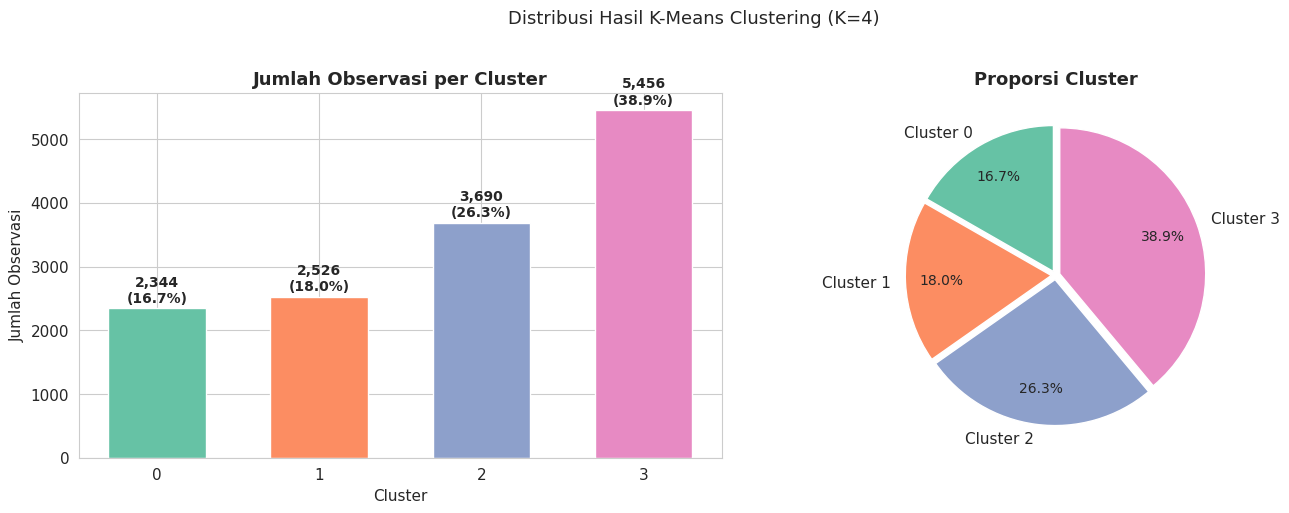

In [ ]:
# Visualisasi distribusi cluster
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

palette = sns.color_palette("Set2", OPTIMAL_K)

# Bar chart
ax = axes[0]
bars = ax.bar(cluster_counts.index, cluster_counts.values,
              color=palette, edgecolor='white', width=0.6)
for bar, count, pct in zip(bars, cluster_counts.values, cluster_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{count:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xlabel('Cluster', fontsize=11)
ax.set_ylabel('Jumlah Observasi', fontsize=11)
ax.set_title('Jumlah Observasi per Cluster', fontsize=13, fontweight='bold')
ax.set_xticks(range(OPTIMAL_K))

# Pie chart
ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    cluster_counts.values,
    labels=[f'Cluster {i}' for i in cluster_counts.index],
    colors=palette,
    autopct='%1.1f%%', startangle=90, pctdistance=0.75,
    explode=[0.03]*OPTIMAL_K
)
for at in autotexts:
    at.set_fontsize(10)
ax2.set_title('Proporsi Cluster', fontsize=13, fontweight='bold')

plt.suptitle(f'Distribusi Hasil K-Means Clustering (K={OPTIMAL_K})', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


In [ ]:
# # Transformasi centroid ke ruang PCA
# pca = PCA(n_components=2, random_state=42)
# X_pca = pca.fit_transform(X_scaled)

# # Buat dataframe PCA
# pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
# centroids_pca = pca.transform(kmeans.cluster_centers_)

# fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# palette = sns.color_palette("Set2", OPTIMAL_K)

# # --- Plot 1: PCA scatter dengan centroid ---
# ax = axes[0]
# for k in range(OPTIMAL_K):
#     mask = pca_df['cluster'] == k
#     ax.scatter(pca_df.loc[mask, 'PC1'], pca_df.loc[mask, 'PC2'],
#                c=[palette[k]], alpha=0.3, s=8, label=f'Cluster {k}')

# # Plot centroid
# ax.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
#            c='black', marker='X', s=250, zorder=10,
#            linewidths=1.5, edgecolors='white', label='Centroid')
# for i, (cx, cy) in enumerate(centroids_pca):
#     ax.annotate(f'C{i}', (cx, cy), textcoords='offset points',
#                 xytext=(8, 5), fontsize=10, fontweight='bold', color='black')

# ax.set_xlabel(f'PC1 ({var_explained[0]:.1f}% variansi)', fontsize=11)
# ax.set_ylabel(f'PC2 ({var_explained[1]:.1f}% variansi)', fontsize=11)

# ax.set_title(
#     'Visualisasi Cluster dalam Ruang PCA\n(dengan Centroid)',
#     fontsize=12,
#     fontweight='bold'
# )

# ax.legend(loc='upper right', fontsize=9)

# # --- Plot 2: Density per cluster ---
# ax2 = axes[1]
# for k in range(OPTIMAL_K):
#     mask = pca_df['cluster'] == k
#     subset = pca_df.loc[mask]
#     try:
#         sns.kdeplot(x=subset['PC1'], y=subset['PC2'], ax=ax2,
#                     color=palette[k], alpha=0.6, levels=4, linewidths=1.5,
#                     label=f'Cluster {k}')
#     except Exception:
#         ax2.scatter(subset['PC1'], subset['PC2'],
#                     c=[palette[k]], alpha=0.2, s=5)

# ax2.set_xlabel(f'PC1 ({var_explained[0]:.1f}% variansi)', fontsize=11)
# ax2.set_ylabel(f'PC2 ({var_explained[1]:.1f}% variansi)', fontsize=11)
# ax2.set_title('KDE Kontur Cluster dalam Ruang PCA', fontsize=12, fontweight='bold')
# ax2.legend(fontsize=9)

# plt.suptitle('Visualisasi Cluster K-Means via PCA 2D', fontsize=13, y=1.02)
# plt.tight_layout()
# plt.show()


---
## Bisecting K-Means

In [ ]:
cols = train_df.columns
numeric_cols = [col for col in cols if (train_df[col].dtype == int or train_df[col].dtype == float)]
used_cols = list(set(numeric_cols) - {"ID"})
train_df_numeric_cols = train_df[numeric_cols]

processed_df = train_df.copy()
processed_df = processed_df[used_cols]

In [ ]:
# HASIL PARAMETER TUNING
X = processed_df
n_clusters = 2

bkmeans = BisectingKMeans(
    n_clusters=n_clusters,
    random_state=SEED,
    init="random",
    n_init=5,
    max_iter=107,
    bisecting_strategy="largest_cluster",
)

pipeline_bkmeans = Pipeline([
    ("scaling", StandardScaler()),
    ("imputer", KNNImputer()), # tidak ada scaling karena tanpa scaling shiloutte score lebih besar??
    ("pca", PCA(n_components=2, random_state=SEED)),
    ("bisecting_kmeans", bkmeans),
])

# Fit pipeline_bkmeans
pipeline_bkmeans.fit(X)

# Ambil hasil transform step-by-step
X_scaled = pipeline_bkmeans.named_steps["scaling"].transform(X)

X_imputed = pipeline_bkmeans.named_steps["imputer"].transform(X_scaled)

X_pca = pipeline_bkmeans.named_steps["pca"].transform(X_imputed)

# Labels cluster
labels = pipeline_bkmeans.named_steps["bisecting_kmeans"].labels_

# Jumlah cluster
n_clusters_ = len(set(labels))

cluster_counts = pd.Series(labels).value_counts().sort_index()
cluster_pct = (cluster_counts / len(labels) * 100).round(2)

print(set(labels))

print("Estimated number of clusters: %d" % n_clusters_)

# Silhouette score
print(
    f"Silhouette Coefficient: "
    f"{metrics.silhouette_score(X_pca, labels):.3f}"
)

In [ ]:
#HYERPARAMETER TUNING
optuna.logging.set_verbosity(optuna.logging.WARNING)

X = processed_df.copy()

# =========================================================
# Objective Function
# =========================================================
def objective(trial):

    # Hyperparameter search space
    params = {
        "n_clusters":trial.suggest_int("n_clusters", 2, 10),
        "init": trial.suggest_categorical("init", ["k-means++", "random"]),
        "n_init": trial.suggest_int("n_init", 5, 30),
        "max_iter": trial.suggest_int("max_iter", 100, 500),
        "bisecting_strategy": trial.suggest_categorical("bisecting_strategy", ["biggest_inertia", "largest_cluster"]),
    }

    bkmeans = BisectingKMeans(
        random_state=SEED,
        **params
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", KNNImputer()),
        ("pca", PCA(n_components=2, random_state=SEED)),
        ("bisecting_kmeans", bkmeans),
    ])

    # Fit pipeline
    pipeline.fit(X)

    # Transform data step-by-step
    X_scaled = pipeline.named_steps["scaler"].transform(X)

    X_imputed = pipeline.named_steps["imputer"].transform(X_scaled)

    X_pca = pipeline.named_steps["pca"].transform(X_imputed)

    # Get labels
    labels = pipeline.named_steps["bisecting_kmeans"].labels_

    # Silhouette score
    score = silhouette_score(X_pca, labels)

    return score


# =========================================================
# Optuna Study
# =========================================================
study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEED),
    study_name="BisectingKMeans_Tuning"
)

study.optimize(
    objective,
    n_trials=100,
    show_progress_bar=True
)

# =========================================================
# Best Result
# =========================================================
print("=" * 50)

print(f"Best Silhouette Score : {study.best_value:.4f}")

print(f"Best Params           :")
for key, value in study.best_params.items():
    print(f"{key}: {value}")


# =========================================================
# Retrain Best Model
# =========================================================
best_model = BisectingKMeans(
    random_state=SEED,
    **study.best_params
)

best_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer()),
    ("pca", PCA(
        n_components=2,
        random_state=SEED
    )),
    ("bisecting_kmeans", best_model),
])

best_pipeline.fit(X)

# Transform for evaluation
X_scaled = best_pipeline.named_steps["scaler"].transform(X)

X_imputed = best_pipeline.named_steps["imputer"].transform(X_scaled)

X_pca = best_pipeline.named_steps["pca"].transform(X_imputed)

labels = best_pipeline.named_steps["bisecting_kmeans"].labels_

# Final metrics
final_score = silhouette_score(X_pca, labels)

n_clusters_ = len(set(labels))

print("\n" + "=" * 50)

print(f"Final Silhouette Score : {final_score:.4f}")

print(f"Number of Clusters     : {n_clusters_}")

In [ ]:
# VISUALISASI
unique_labels = set(labels)

colors = [
    plt.cm.Spectral(each)
    for each in np.linspace(0, 1, len(unique_labels))
]

for k, col in zip(unique_labels, colors):

    class_member_mask = (labels == k)

    xy = X_pca[class_member_mask]

    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
        label=f"Cluster {k}"
    )

plt.title(f"Estimated number of clusters: {n_clusters_}")

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")

plt.legend()

plt.show()

In [ ]:
# VISUALISASI
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

palette = sns.color_palette("Set2", n_clusters)

# Bar chart
ax = axes[0]
bars = ax.bar(cluster_counts.index, cluster_counts.values,
              color=palette, edgecolor='white', width=0.6)
for bar, count, pct in zip(bars, cluster_counts.values, cluster_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{count:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_xlabel('Cluster', fontsize=11)
ax.set_ylabel('Jumlah Observasi', fontsize=11)
ax.set_title('Jumlah Observasi per Cluster', fontsize=13, fontweight='bold')
ax.set_xticks(range(n_clusters))

# Pie chart
ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    cluster_counts.values,
    labels=[f'Cluster {i}' for i in cluster_counts.index],
    colors=palette,
    autopct='%1.1f%%', startangle=90, pctdistance=0.75,
    explode=[0.03]*n_clusters
)
for at in autotexts:
    at.set_fontsize(10)
ax2.set_title('Proporsi Cluster', fontsize=13, fontweight='bold')

plt.suptitle(f'Distribusi Hasil Bisecting K-Means Clustering (K={n_clusters})', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
df_labeled = processed_df.copy()
df_labeled['cluster'] = labels

# Pilih fitur-fitur kunci yang relevan untuk cuaca ekstrem
key_features = processed_df.columns

# Statistik deskriptif per cluster
profile = df_labeled.groupby('cluster')[key_features].agg(['mean', 'median', 'max', 'std'])
print(profile.T)

In [ ]:
# Threshold berdasarkan pengetahuan domain / percentile data
thresholds = df_labeled[key_features].median() # pake median karena banyak outliers

# Hitung "extreme score" per cluster: berapa banyak threshold yang dilampaui rata-ratanya
cluster_means = df_labeled.groupby('cluster')[key_features].mean()

extreme_score = {}
for cluster_id in cluster_means.index:
    score = 0
    for feat_keyword, threshold in thresholds.items():
        col = [c for c in key_features if feat_keyword in c]
        if col and cluster_means.loc[cluster_id, col[0]] >= threshold:
            score += 1
    extreme_score[cluster_id] = score

print(pd.Series(extreme_score, name='extreme_score'))
# Cluster dengan skor tertinggi → labeli sebagai "ekstrem"

Karena cluster 0 memiliki extreme_score yang lebih tinggi, maka cluster 0 diklasifikasikan sebagai cluster dengan cuaca extreme.

In [ ]:
# =============================================================================
# BISECTING K-MEANS — CLUSTER PROFILING
# Tambahkan sel-sel berikut setelah blok model training Bisecting K-Means
# =============================================================================

# ── [SEL 1] Setup: Tempel label cluster ke dataframe asli ────────────────────
df_bkm = processed_df.copy()
df_bkm['cluster'] = labels

# Label semantik berdasarkan extreme_score (cluster 0 = ekstrem)
cluster_label_map_bkm = {
    0: 'Ekstrem',
    1: 'Normal',
}
df_bkm['cluster_label'] = df_bkm['cluster'].map(cluster_label_map_bkm)

print("Cluster distribution:")
print(df_bkm['cluster_label'].value_counts())


# ── [SEL 2] Statistik Deskriptif per Cluster ────────────────────────────────
KEY_FEATURES_BKM = [
    'temperature_2m',
    'relative_humidity_2m',
    'dew_point_2m',
    'apparent_temperature',
    'pressure_msl',
    'cloud_cover',
    'vapour_pressure_deficit',
    'wind_speed_10m',
    'wind_speed_100m',
    'wind_gusts_10m',
    'shortwave_radiation',
    'sunshine_duration',
    'soil_moisture_0_to_7cm',
    'precipitation',
]

key_feats = [f for f in KEY_FEATURES_BKM if f in df_bkm.columns]

# Tabel mean ± std per cluster
profile_bkm = df_bkm.groupby('cluster_label')[key_feats].agg(['mean', 'std']).round(3)
print("\nCluster Profile — Mean ± Std:")
print(profile_bkm.T.to_string())

# Tabel selisih (delta)
mean_bkm = df_bkm.groupby('cluster_label')[key_feats].mean().round(3).T
mean_bkm.columns.name = None
if 'Ekstrem' in mean_bkm.columns and 'Normal' in mean_bkm.columns:
    mean_bkm['Δ (Ekstrem − Normal)'] = (mean_bkm['Ekstrem'] - mean_bkm['Normal']).round(3)
    mean_bkm['Δ%'] = (
        mean_bkm['Δ (Ekstrem − Normal)'] / mean_bkm['Normal'].abs().replace(0, 1) * 100
    ).round(1)
print("\nPerbandingan rata-rata per fitur:")
print(mean_bkm.to_string())


# ── [SEL 3] Grouped Bar Chart — Profil Fitur (Normalized) ───────────────────
RADAR_FEATS = [f for f in key_feats]

means_bkm = df_bkm.groupby('cluster')[RADAR_FEATS].mean()
means_norm_bkm = (means_bkm - means_bkm.min()) / (means_bkm.max() - means_bkm.min() + 1e-9)

n_feats   = len(RADAR_FEATS)
n_labels  = len(means_bkm.index)
x_pos     = np.arange(n_feats)
bar_width = 0.65 / n_labels

CLUSTER_COLORS_BKM = {0: PALETTE['extreme'], 1: PALETTE['normal_0']}

fig, ax = plt.subplots(figsize=(16, 5))

for i, (lbl, row) in enumerate(means_norm_bkm.iterrows()):
    color     = CLUSTER_COLORS_BKM.get(lbl, NORMAL_COLORS[i])
    label_txt = f'Cluster {lbl} — {cluster_label_map_bkm.get(lbl, "")}'
    ax.bar(
        x_pos + i * bar_width - (n_labels - 1) * bar_width / 2,
        row.values,
        width=bar_width * 0.9,
        color=color, alpha=0.85,
        label=label_txt, edgecolor='none'
    )

ax.set_xticks(x_pos)
ax.set_xticklabels(
    [f.replace('_', ' ').title() for f in RADAR_FEATS],
    rotation=35, ha='right', fontsize=8.5
)
ax.set_ylabel('Normalized Mean (0–1)', labelpad=8)
ax.set_title(
    'Bisecting K-Means — Profil Fitur per Cluster\n'
    '(Nilai dinormalisasi 0–1 untuk komparasi)',
    fontweight='bold'
)
ax.legend(loc='upper right', frameon=True, framealpha=0.9)
clean_spines(ax)
ax.set_axisbelow(True)
add_figure_label(ax, 'Setiap fitur dinormalisasi secara independen.')
plt.tight_layout()
plt.show()


# ── [SEL 4] Violin Plots — Distribusi Fitur Kunci ────────────────────────────
VIOLIN_FEATS_BKM = [
    'temperature_2m',
    'relative_humidity_2m',
    'wind_gusts_10m',
    'cloud_cover',
    'precipitation',
    'shortwave_radiation',
]
VIOLIN_FEATS_BKM = [f for f in VIOLIN_FEATS_BKM if f in df_bkm.columns]

VIOLIN_PALETTE_BKM = {
    'Normal'  : PALETTE['normal_0'],
    'Ekstrem' : PALETTE['extreme'],
}

n_viol = len(VIOLIN_FEATS_BKM)
fig, axes = plt.subplots(1, n_viol, figsize=(3.5 * n_viol, 5))
if n_viol == 1:
    axes = [axes]

fig.suptitle(
    'Bisecting K-Means — Distribusi Fitur: Normal vs Ekstrem',
    fontweight='bold', y=1.02
)

for ax, feat in zip(axes, VIOLIN_FEATS_BKM):
    sns.violinplot(
        data=df_bkm,
        x='cluster_label',
        y=feat,
        order=['Normal', 'Ekstrem'],
        palette=VIOLIN_PALETTE_BKM,
        inner='quart',
        linewidth=1,
        ax=ax
    )
    short = feat.replace('_', ' ').title()
    ax.set_title(short, fontsize=9, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()


# ── [SEL 5] Box Plot — Distribusi Fitur per Cluster ─────────────────────────
BOX_FEATS = [
    'temperature_2m',
    'relative_humidity_2m',
    'wind_gusts_10m',
    'cloud_cover',
    'precipitation',
    'shortwave_radiation',
    'soil_moisture_0_to_7cm',
    'vapour_pressure_deficit',
]
BOX_FEATS = [f for f in BOX_FEATS if f in df_bkm.columns]

n_box = len(BOX_FEATS)
ncols = 4
nrows = math.ceil(n_box / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.flatten()

fig.suptitle(
    'Bisecting K-Means — Box Plot Fitur per Cluster',
    fontweight='bold', fontsize=14, y=1.01
)

for ax, feat in zip(axes, BOX_FEATS):
    data_by_cluster = [
        df_bkm[df_bkm['cluster_label'] == lbl][feat].dropna().values
        for lbl in ['Normal', 'Ekstrem']
    ]
    bp = ax.boxplot(
        data_by_cluster,
        patch_artist=True,
        medianprops=dict(color='black', linewidth=2),
        whiskerprops=dict(color='gray', linewidth=1),
        capprops=dict(color='gray'),
        flierprops=dict(marker='o', markersize=3, alpha=0.3,
                        markerfacecolor='orange', markeredgecolor='none'),
        widths=0.45
    )
    colors_box = [PALETTE['normal_0'], PALETTE['extreme']]
    for patch, c in zip(bp['boxes'], colors_box):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)

    short = feat.replace('_', ' ').title()
    ax.set_title(short, fontsize=9, fontweight='bold')
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Normal', 'Ekstrem'], fontsize=9)
    clean_spines(ax)
    ax.set_axisbelow(True)

# Sembunyikan axes berlebih
for ax in axes[n_box:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


# ── [SEL 6] Heatmap Korelasi Fitur dalam setiap Cluster ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

HEATMAP_FEATS = [f for f in KEY_FEATURES_BKM if f in df_bkm.columns]

for ax, (lbl, name) in zip(axes, [(0, 'Cluster 0 — Ekstrem'), (1, 'Cluster 1 — Normal')]):
    subset = df_bkm[df_bkm['cluster'] == lbl][HEATMAP_FEATS]
    corr   = subset.corr()

    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(
        corr, ax=ax,
        mask=mask,
        cmap='coolwarm', vmin=-1, vmax=1,
        annot=True, fmt='.2f', annot_kws={'size': 7},
        linewidths=0.4, linecolor='gray',
        cbar_kws={'shrink': 0.7}
    )
    ax.set_title(name, fontweight='bold', fontsize=12)
    ax.set_xticklabels(
        [f.replace('_', ' ') for f in HEATMAP_FEATS],
        rotation=45, ha='right', fontsize=7.5
    )
    ax.set_yticklabels(
        [f.replace('_', ' ') for f in HEATMAP_FEATS],
        rotation=0, fontsize=7.5
    )

fig.suptitle(
    'Matriks Korelasi Fitur — per Cluster Bisecting K-Means',
    fontweight='bold', fontsize=14, y=1.01
)
plt.tight_layout()
plt.show()


# ── [SEL 7] Pairplot Fitur Terpilih ─────────────────────────────────────────
PAIR_FEATS = [
    'temperature_2m',
    'relative_humidity_2m',
    'cloud_cover',
    'wind_gusts_10m',
    'shortwave_radiation',
    'precipitation',
]
PAIR_FEATS = [f for f in PAIR_FEATS if f in df_bkm.columns]

sample_pair = df_bkm[PAIR_FEATS + ['cluster_label']].dropna().sample(
    min(1500, len(df_bkm)), random_state=SEED
)

g = sns.pairplot(
    sample_pair,
    hue='cluster_label',
    hue_order=['Normal', 'Ekstrem'],
    palette={'Normal': PALETTE['normal_0'], 'Ekstrem': PALETTE['extreme']},
    diag_kind='kde',
    plot_kws=dict(alpha=0.35, s=12, linewidth=0),
    diag_kws=dict(fill=True, alpha=0.4)
)
g.fig.suptitle(
    'Bisecting K-Means — Pairplot Fitur Terpilih\n'
    '(Sample 1500 titik, warna = cluster)',
    fontweight='bold', y=1.02
)
plt.show()


# ── [SEL 8] Radar Chart — Profil Cluster ─────────────────────────────────────
from math import pi

RADAR_FEATS_BKM = [
    'temperature_2m',
    'relative_humidity_2m',
    'wind_gusts_10m',
    'cloud_cover',
    'shortwave_radiation',
    'soil_moisture_0_to_7cm',
    'precipitation',
    'vapour_pressure_deficit',
]
RADAR_FEATS_BKM = [f for f in RADAR_FEATS_BKM if f in df_bkm.columns]

radar_means = df_bkm.groupby('cluster')[RADAR_FEATS_BKM].mean()
radar_norm  = (radar_means - radar_means.min()) / (
    radar_means.max() - radar_means.min() + 1e-9
)

categories = [f.replace('_', ' ').title() for f in RADAR_FEATS_BKM]
N          = len(categories)
angles     = [n / float(N) * 2 * pi for n in range(N)]
angles    += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
plt.xticks(angles[:-1], categories, color='gray', size=9)
ax.set_rlabel_position(0)
ax.set_ylim(0, 1)

for cluster_id, row in radar_norm.iterrows():
    values  = row.tolist() + [row.tolist()[0]]
    color   = CLUSTER_COLORS_BKM.get(cluster_id, NORMAL_COLORS[0])
    label   = f'Cluster {cluster_id} — {cluster_label_map_bkm.get(cluster_id, "")}'
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=label, color=color)
    ax.fill(angles, values, color=color, alpha=0.18)

ax.set_title(
    'Bisecting K-Means — Radar Chart Profil Cluster\n(Nilai dinormalisasi 0–1)',
    fontsize=12, fontweight='bold', y=1.12
)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.15), fontsize=9)
plt.tight_layout()
plt.show()


# ── [SEL 9] Analisis Temporal — Komposisi Cluster per Jam & Bulan ─────────────
if 'time' in train_df.columns:
    df_time = train_df[['time', 'cluster']].copy()
    df_time['time']  = pd.to_datetime(df_time['time'])
    df_time['hour']  = df_time['time'].dt.hour
    df_time['month'] = df_time['time'].dt.month
else:
    # Jika 'time' sudah di-drop, skip sel ini
    df_time = None

if df_time is not None:
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle(
        'Bisecting K-Means — Komposisi Cluster per Waktu',
        fontweight='bold', fontsize=13, y=1.02
    )

    # Proporsi cluster per jam
    hourly_comp = (
        df_time.groupby(['hour', 'cluster'])
        .size()
        .unstack(fill_value=0)
    )
    hourly_prop = hourly_comp.div(hourly_comp.sum(axis=1), axis=0)

    hourly_prop.plot(
        kind='bar', stacked=True, ax=axes[0],
        color=[CLUSTER_COLORS_BKM.get(c, NORMAL_COLORS[0]) for c in hourly_prop.columns],
        width=0.8, edgecolor='none', alpha=0.85
    )
    axes[0].set_title('Proporsi Cluster per Jam', fontweight='bold')
    axes[0].set_xlabel('Jam')
    axes[0].set_ylabel('Proporsi')
    axes[0].set_xticklabels(hourly_prop.index, rotation=0, fontsize=8)
    axes[0].legend(
        [f'Cluster {c} — {cluster_label_map_bkm.get(c,"")}' for c in hourly_prop.columns],
        fontsize=8, loc='upper right'
    )
    clean_spines(axes[0])

    # Proporsi cluster per bulan
    month_names = ['Jan','Feb','Mar','Apr','Mei','Jun',
                   'Jul','Agu','Sep','Okt','Nov','Des']
    monthly_comp = (
        df_time.groupby(['month', 'cluster'])
        .size()
        .unstack(fill_value=0)
    )
    monthly_prop = monthly_comp.div(monthly_comp.sum(axis=1), axis=0)
    monthly_prop.index = [month_names[m-1] for m in monthly_prop.index]

    monthly_prop.plot(
        kind='bar', stacked=True, ax=axes[1],
        color=[CLUSTER_COLORS_BKM.get(c, NORMAL_COLORS[0]) for c in monthly_prop.columns],
        width=0.8, edgecolor='none', alpha=0.85
    )
    axes[1].set_title('Proporsi Cluster per Bulan', fontweight='bold')
    axes[1].set_xlabel('Bulan')
    axes[1].set_ylabel('Proporsi')
    axes[1].set_xticklabels(monthly_prop.index, rotation=30, ha='right', fontsize=9)
    axes[1].legend(
        [f'Cluster {c} — {cluster_label_map_bkm.get(c,"")}' for c in monthly_prop.columns],
        fontsize=8, loc='upper right'
    )
    clean_spines(axes[1])

    plt.tight_layout()
    plt.show()


# ── [SEL 10] Ringkasan Naratif ───────────────────────────────────────────────
print("=" * 65)
print("BISECTING K-MEANS — RINGKASAN PROFILING CLUSTER")
print("=" * 65)

for lbl in sorted(df_bkm['cluster'].unique()):
    sub    = df_bkm[df_bkm['cluster'] == lbl]
    name   = cluster_label_map_bkm.get(lbl, f'Cluster {lbl}')
    n_pts  = len(sub)
    pct    = n_pts / len(df_bkm) * 100

    print(f"\nCluster {lbl} — {name}")
    print(f"  Jumlah data : {n_pts:,} ({pct:.1f}%)")
    print(f"  Karakteristik utama:")
    for feat in key_feats:
        mu  = sub[feat].mean()
        std = sub[feat].std()
        print(f"    {feat:40s}: mean={mu:.3f}, std={std:.3f}")

---
# Summary

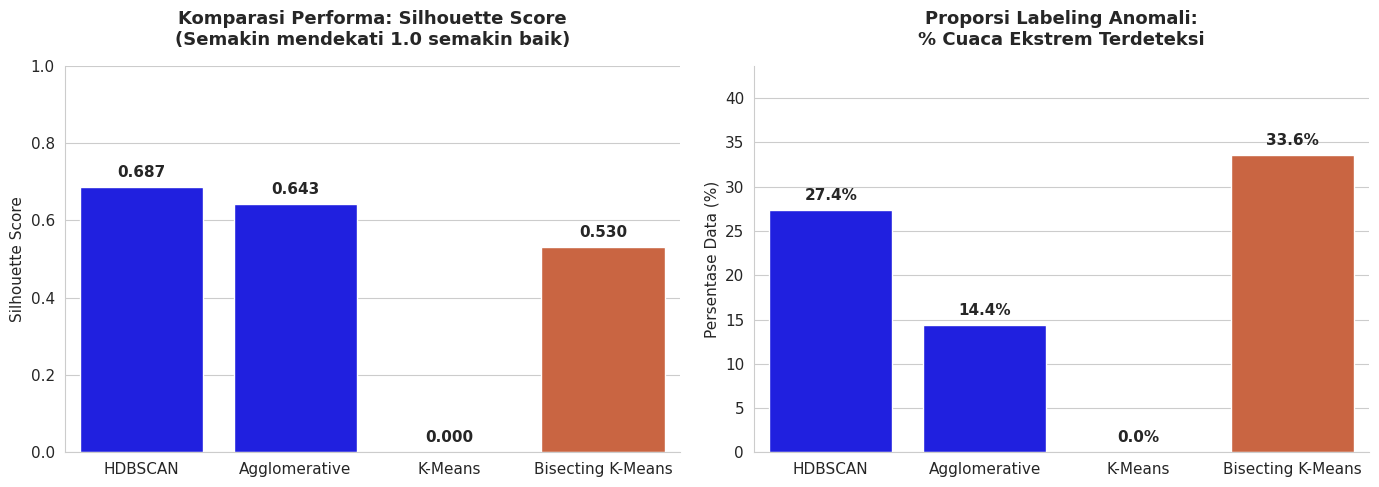

In [ ]:
data_komparasi = {
    'Model': ['HDBSCAN', 'Agglomerative','K-Means', 'Bisecting K-Means'],
    'Silhouette Score': [0.687, 0.643, 0.178, 0.530], # MASUKIN SCORE KALIAN GES
    '% Cuaca Ekstrem': [27.4, 14.4, 0, 33.6]
}
df_compare = pd.DataFrame(data_komparasi)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bar_colors = [NORMAL_COLORS[0], NORMAL_COLORS[0], NORMAL_COLORS[0], EXTREME_COLORS[0]]

sns.barplot(data=df_compare, x='Model', y='Silhouette Score', palette=bar_colors, ax=axes[0])
axes[0].set_title('Komparasi Performa: Silhouette Score\n(Semakin mendekati 1.0 semakin baik)',
                  fontweight='bold', pad=15)
axes[0].set_ylim(0, 1.0)
axes[0].set_ylabel('Silhouette Score')
axes[0].set_xlabel('')

for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 5),
                     textcoords='offset points')

sns.barplot(data=df_compare, x='Model', y='% Cuaca Ekstrem', palette=bar_colors, ax=axes[1])
axes[1].set_title('Proporsi Labeling Anomali:\n% Cuaca Ekstrem Terdeteksi',
                  fontweight='bold', pad=15)
axes[1].set_ylim(0, max(df_compare['% Cuaca Ekstrem']) * 1.3) # Ruang ekstra untuk label
axes[1].set_ylabel('Persentase Data (%)')
axes[1].set_xlabel('')

for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 5),
                     textcoords='offset points')

sns.despine()
plt.tight_layout()
plt.show()